In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

ruta_scripts = Path.cwd().parent / "scripts"
sys.path.append(str(ruta_scripts))

import Modelos_neuronales as mn

In [2]:
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde, ks_2samp
from scipy.signal import welch

import jpype
import os
from jpype import JClass
jar_path = os.path.abspath("infodynamics.jar")
jpype.startJVM(classpath=[jar_path])
TECalcClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").TransferEntropyCalculatorKraskov
teCalc = TECalcClass()
from jpype import JPackage
CTEClass = JPackage("infodynamics.measures.continuous.kraskov").ConditionalTransferEntropyCalculatorKraskov
cteCalc = CTEClass()
MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()

from sklearn.feature_selection import mutual_info_regression

In [3]:
sys.path.insert(0,r"C:\Users\alons\Master Ciencia de Datos/TFM/Git Hub/notebooks/IDTxl-master/IDTxl-master")
import math
np.math = math
from idtxl.multivariate_te import MultivariateTE
from idtxl.data import Data
from idtxl.visualise_graph import plot_network

# Transfer Entropy no estructural y el algoritmo greedy

### Influencia de los parámetros del estimador

Se utilizará la dinámica lineal autorregresiva: 
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$
para realizar un análisis exhaustivo sobre los parámetros que intevienen en la estimación de la Transfer Entropy mediante la herramienta JIDT. De nuevo, será de gran utilidad la función `find_optimal_tau_TE_JIDT` que ya fue presentada en el notebook "Retardos Causales".

In [4]:
def find_optimal_tau_TE_JIDT(V1, V2, n_vecinos, max_steps=600, contexto_k=5, contexto_l=5, contexto_c=5, factor_bool=True, plot=False, inverse=False, conditional=False, padres_source=None):
    """
    Calcula la Transfer Entropy (TE) para distintos valores de tau_source con el código de JIDT.
    Si inverse=True:
        calcula también V2 -> V1.
    Si conditional=True:
        calcula también la CTE V1 -> V2 | V2
    Retorna:
        tau_values, te_direct, optimal_tau

    """
    tau_values = np.arange(1, max_steps + 1)
    te_results = []

    if inverse:
        te_inverse_results = []
        
    if conditional:
        cte_results = []
    
    factor = 5   

    if factor_bool:
        V1 = V1[::factor]
        V2 = V2[::factor]

    hist = max(contexto_k, contexto_l, contexto_c)
    V1 = V1[hist:]
    V2 = V2[hist:]

        
        # --- TE Directa (V1 -> V2) ---
    teCalc = TECalcClass()
    teCalc.setProperty("k", str(n_vecinos))
    teCalc.setProperty("k_HISTORY", str(contexto_k))
    teCalc.setProperty("l_HISTORY", str(contexto_l))
    

    for tau in tqdm(tau_values, desc="Análisis de Tau", unit="tau"):
        
        teCalc.setProperty("DELAY", str(tau))
        teCalc.initialise()
        teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
        te = teCalc.computeAverageLocalOfObservations()
        te_results.append(te)

         # --- TE Inversa (V2 -> V1) ---
    if inverse:
    
            teCalc_inv = TECalcClass()
            teCalc_inv.setProperty("k", str(n_vecinos))
            teCalc_inv.setProperty("k_HISTORY", str(contexto_k))
            teCalc_inv.setProperty("l_HISTORY", str(contexto_l))
    
            for tau in tqdm(tau_values, desc="TE X → Y", unit="tau"):
                teCalc_inv.setProperty("DELAY", str(tau))
                teCalc_inv.initialise()
                teCalc_inv.setObservations(V2.astype(np.float64),V1.astype(np.float64))
                te_inv = teCalc_inv.computeAverageLocalOfObservations()
                te_inverse_results.append(te_inv)
                

        # --- CTE (V1 -> V2 | V2) ---
    if conditional:
        cteCalc = CTEClass() 
        cteCalc.setProperty("k", str(n_vecinos))
        cteCalc.setProperty("k_HISTORY", str(contexto_k))
        cteCalc.setProperty("l_HISTORY", str(contexto_l))
        cteCalc.setProperty("c_HISTORY", str(contexto_c))
    
        for tau in tqdm(tau_values, desc="CTE Y → X | X", unit="tau"):
            cteCalc.setProperty("DELAY", str(tau))
            cteCalc.initialise()
            cteCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64), V2.astype(np.float64))
            cte_val = cteCalc.computeAverageLocalOfObservations()
            cte_results.append(cte_val)


    te_results = np.array(te_results)
    if inverse:
        te_inverse_results = np.array(te_inverse_results)
    if conditional:
        cte_results = np.array(cte_results)

    optimal_idx = np.argmax(te_results)
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, te_results, lw=2, label="Transfer Entropy (Direct)")
        if padres_source is not None:
            if np.isscalar(padres_source):
                padres_source = [padres_source]
            for i, delay in enumerate(padres_source):
                if delay in tau_values:
                    idx = np.where(tau_values == delay)[0][0]
                    plt.scatter(tau_values[idx], te_results[idx], marker="*", s=250, zorder=5, label="Padre seleccionado" if i == 0 else None)
        if inverse:
            plt.plot(tau_values, te_inverse_results, color="gray", alpha=0.45, lw=1.8, linestyle="--", label="TE X → Y")
        if conditional:
            plt.plot(tau_values, cte_results, color="red", alpha=0.35, lw=1.8, linestyle="--", label="CTE Y → X | X")
        plt.axvline(tau_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel("Delay")
        plt.ylabel("Transfer Entropy")
        plt.title(f"TE (JIDT-Kraskov) vs Delay "f"(k={n_vecinos})")
        plt.grid(True)
        plt.legend()
        plt.show()


    return tau_values, te_results, optimal_tau

La función `find_optimal_tau_TE_JIDT` está diseñada para analizar la relación causal direccional entre dos series temporales utilizando la TE a través de la librería JIDT (empleando el algoritmo KSG). La función permite fijar el vecinadario que se quiere utilizar en las estimaciones (`n_vecinos`) y el rango de retardos que analizar (`max_steps`). Por otro lado, puede activarse la opción (`inverse=True`) de realizar el análisis en el sentido opuesto al del flujo directo de información ($V_2 --> V_1$) y también (`conditional=True`) la Conditional Transfer Entropy (CTE) ($V1 -> V2 | V2$) si se desea comprobar que en el análisis no está interfiriendo información redundante del propio destino. El ánimo de esa última utilidad es descratar la hipotesis de que la aparición de TE espuria es fruto de un condicionamiento insuficiente de la variable destino sobre su propio pasado. En el caso de activar alguna de las anteriores utilidades, se mostraría dicho flujo sobre el mismo dibujo que el análisis en el sentido directo ($V_1 --> V_2$). El booleano `factor_bool` permite aplicar un submuestreo para agilizar el cálculo.  

Haciendo uso de esta herramienta, el primer objetivo del presente notebook es analizar el impacto de los parámetros `contexto_k`, `contexto_l` y `contexto_c` que determinan internamente el método de estimación de TE en JIDT. En particular, esos parámetros regulan la memoria de los procesos estocáticos implicados:
- contexto_k: Historial de la señal de destino (V2).
- contexto_l: Historial de la señal de origen (V1).
- contexto_c: Historial empleado en la CTE para condicionar por el pasado de las variables adicionales implicadas.

Se comenzará haciendo el análisis sobre el sistema 
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$
para valor de $\tau=250$.

TE X → Y: 100%|██████████| 300/300 [15:07<00:00,  3.03s/tau]
CTE Y → X | X: 100%|██████████| 300/300 [15:52<00:00,  3.17s/tau]


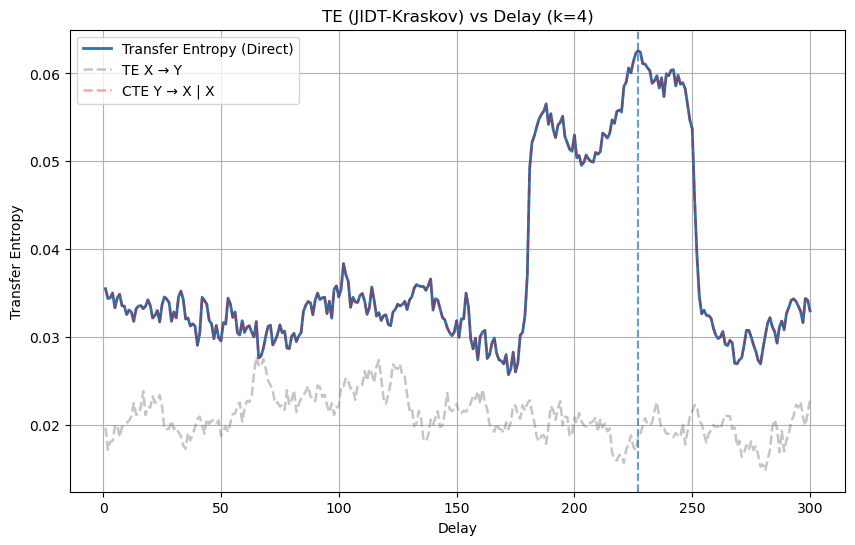

El delay óptimo para k=4 es: 227.000 ms


In [33]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=70, contexto_c=100, factor_bool= False, plot=True, inverse=True, conditional=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

TE X → Y: 100%|██████████| 300/300 [08:10<00:00,  1.64s/tau]
CTE Y → X | X: 100%|██████████| 300/300 [17:54<00:00,  3.58s/tau]


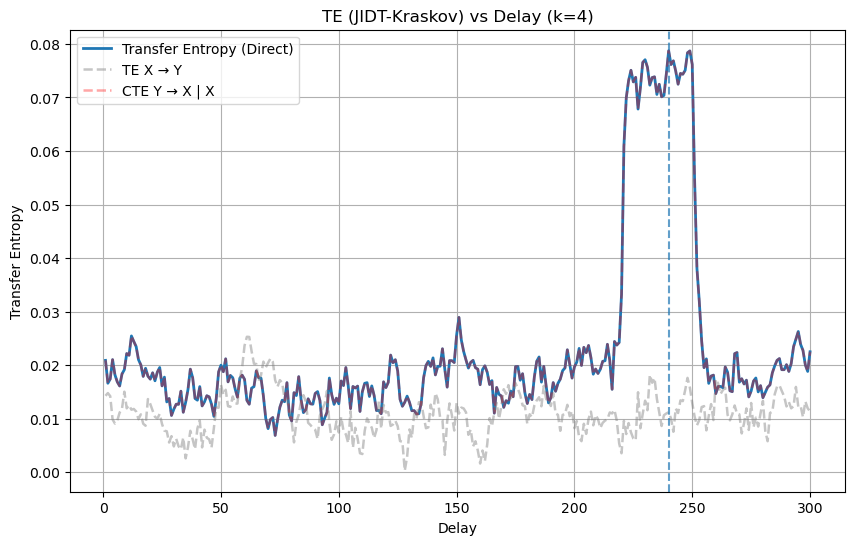

El delay óptimo para k=4 es: 240.000 ms


In [34]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=30, contexto_c=100, factor_bool= False, plot=True, inverse=True, conditional=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

TE V2 → V1: 100%|██████████| 300/300 [01:09<00:00,  4.31tau/s]


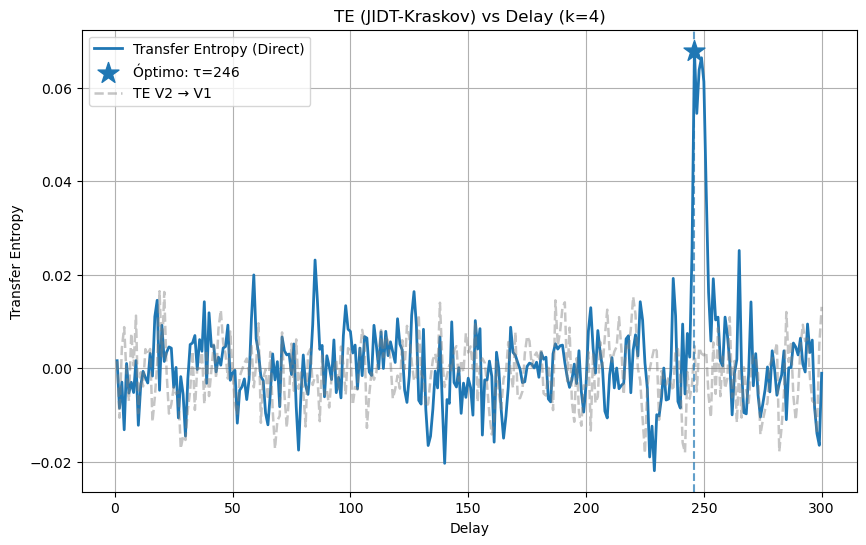

El delay óptimo para k=4 es: 246.000 ms


In [51]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=5, factor_bool= False, plot=True, inverse=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

TE V2 → V1: 100%|██████████| 300/300 [03:10<00:00,  1.57tau/s]


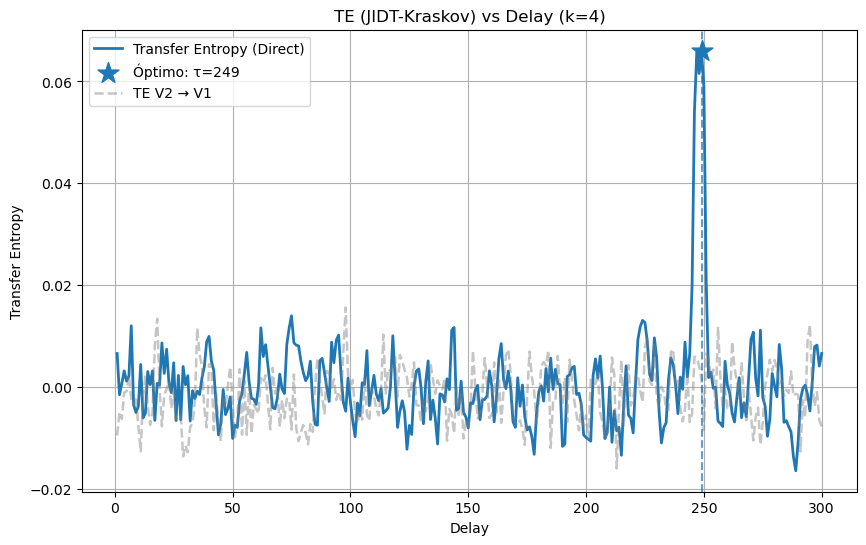

El delay óptimo para k=4 es: 249.000 ms


In [52]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=5, contexto_l=5, factor_bool= False, plot=True, inverse=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

TE X → Y: 100%|██████████| 300/300 [00:51<00:00,  5.82tau/s]
CTE Y → X | X: 100%|██████████| 300/300 [02:02<00:00,  2.44tau/s]


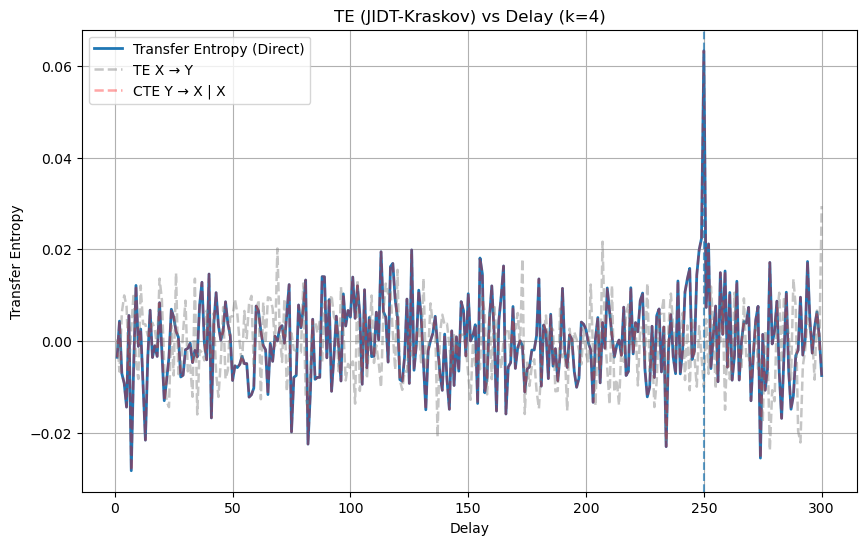

El delay óptimo para k=4 es: 250.000 ms


In [32]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=1, factor_bool= False, plot=True, inverse=True, conditional=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

TE V2 → V1: 100%|██████████| 300/300 [15:45<00:00,  3.15s/tau]
CTE V2 → V1 | V1: 100%|██████████| 300/300 [15:52<00:00,  3.17s/tau]


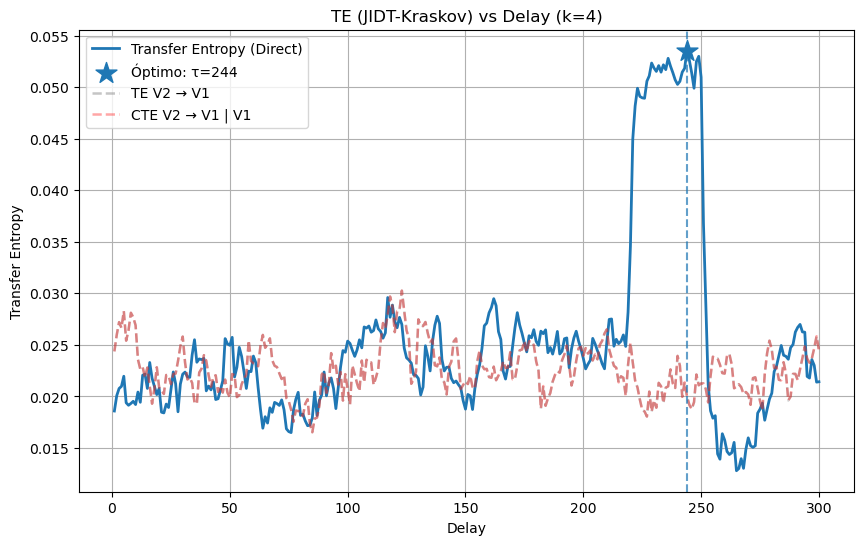

El delay óptimo para k=4 es: 244.000 ms


In [85]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=30, contexto_l=30, contexto_c=100, factor_bool= False, plot=True, inverse=True, conditional=True)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Identificamos patrones de comportamiento claros. En primer lugar, el contexto sobre la señal de origen (`contexto_l`) tiene un efecto determinista en la longuitud de la zona de alta intensidad de TE que se asocia al flujo de información real. En particular, se detecta de manera evidente que la meseta generada comienza en $\tau -$ `contexto_l` y llega hasta $\tau$, y en ese instante la curva vuelve a caer al nivel basal.

Por otro lado, el contexto sobre la señal de destino (`contexto_k`) tiene un efecto de amortiguación y suavizado del ruido cuando toma valores más grandes, pero su influencia es aparéntemente muchos menos determinante en la gráfica final.

Más dimensiones (contexto) --> más falsos positivos (se nencistn más datos para resultados robustos).

A continuación se demuestra el efecto que tiene el parámetro $c$ del sistema autorregrsivo que modela el acomplamiento de la variable de origen $Y$ con su propio pasado.
Valores altos de $c$ pueden probocar la aparición de Transfer Entropy espuria.

Se fija $c=0.1$.

TE V2 → V1: 100%|██████████| 300/300 [01:57<00:00,  2.55tau/s]


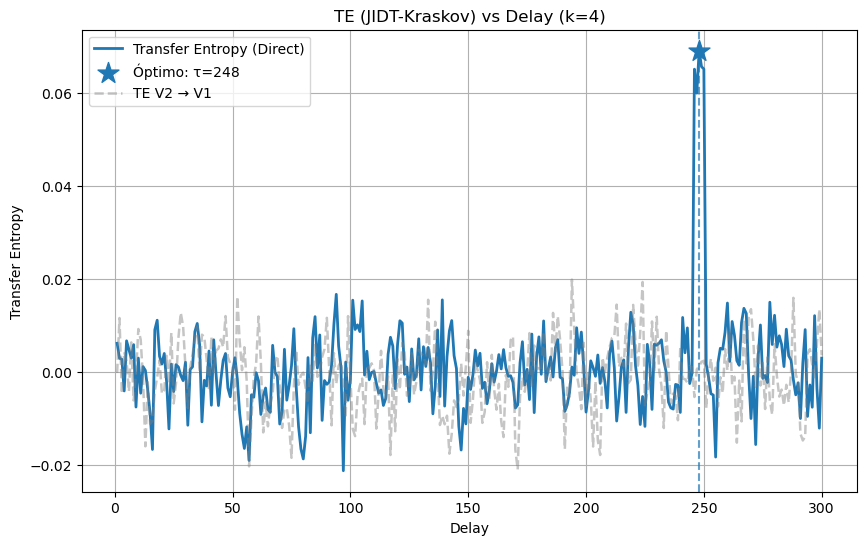

El delay óptimo para k=4 es: 248.000 ms


In [103]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.1
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=5, factor_bool= False, plot=True, inverse=True, conditional=False)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Y ahora aumentamos el parámetro $c$ a $1.0$.

TE V2 → V1: 100%|██████████| 300/300 [01:06<00:00,  4.52tau/s]


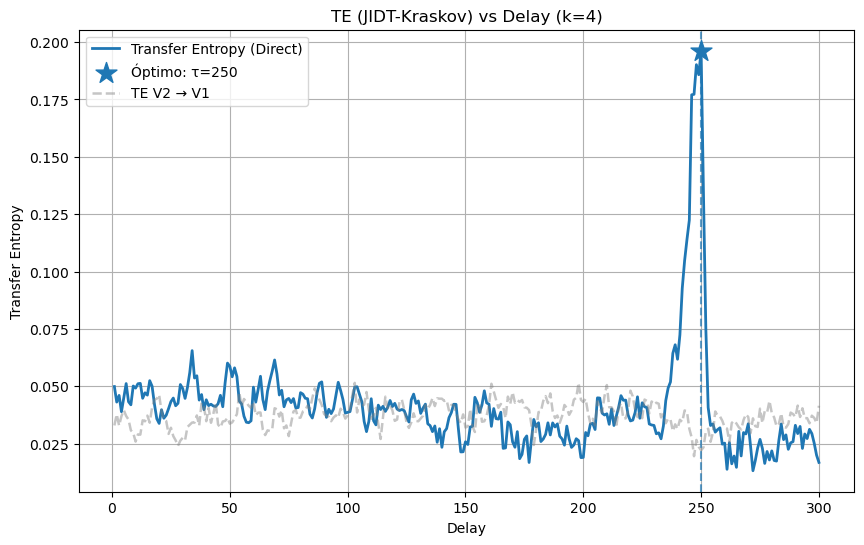

El delay óptimo para k=4 es: 250.000 ms


In [104]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 1.0
sig_x2, sig_y2 = 1.0, 1.0
tau = 250

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=300, contexto_k=1, contexto_l=5, factor_bool= False, plot=True, inverse=True, conditional=False)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Sigiendo con el modelo Autorregresivo a modo de ground truth, veamos el impacto que puede tener el cálculo de TE cuando el DELAY aplicado no es el óptimo.

Los datos continuarán siguiendo el sistema: 
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$
para valor de $\tau=250$. A continuación se muestran diferentes combianciones del DELAY artificuial aplicado (en muchos casos no coincidirá exactamente con el valor de retardo causal real del sistema) para analizar la dependencia del estimador al mismo. 

- Delay --> 200
- contexto destino --> 1
- contexto origen --> 70

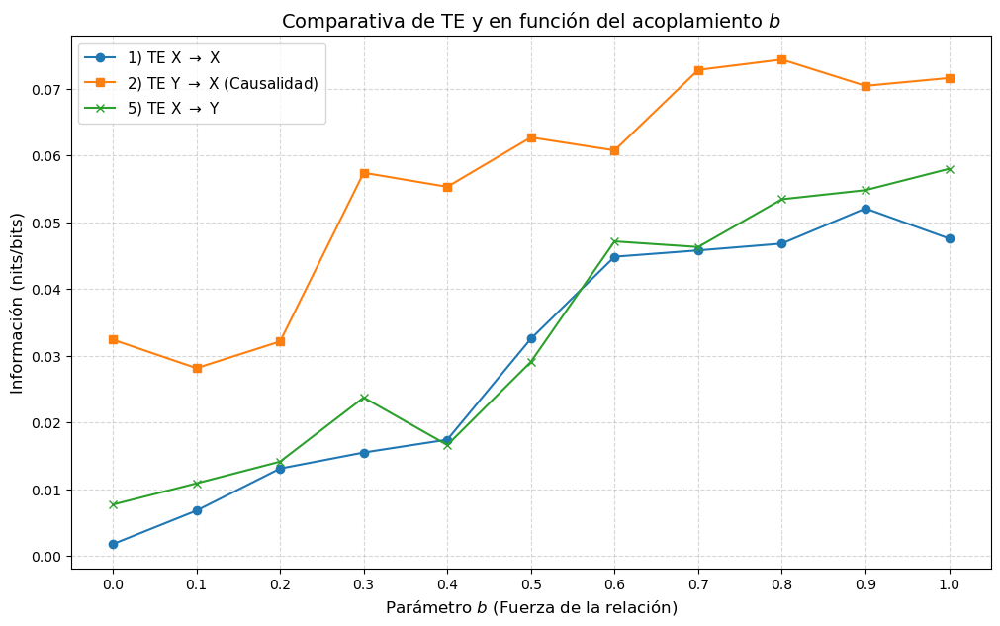

In [7]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 3 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 3 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE y en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

Al estudiar el valor de TE sobre un DELAY corto, pero superior a $\tau - l_{HISTORY}$, se detecta correctamente la dirección causal pero ambos sentidos están sobreestimados. El parámetro $c$ regula en gran medida esa sobreestimación.

$c=0.1$ en vez de $c=0.7$:

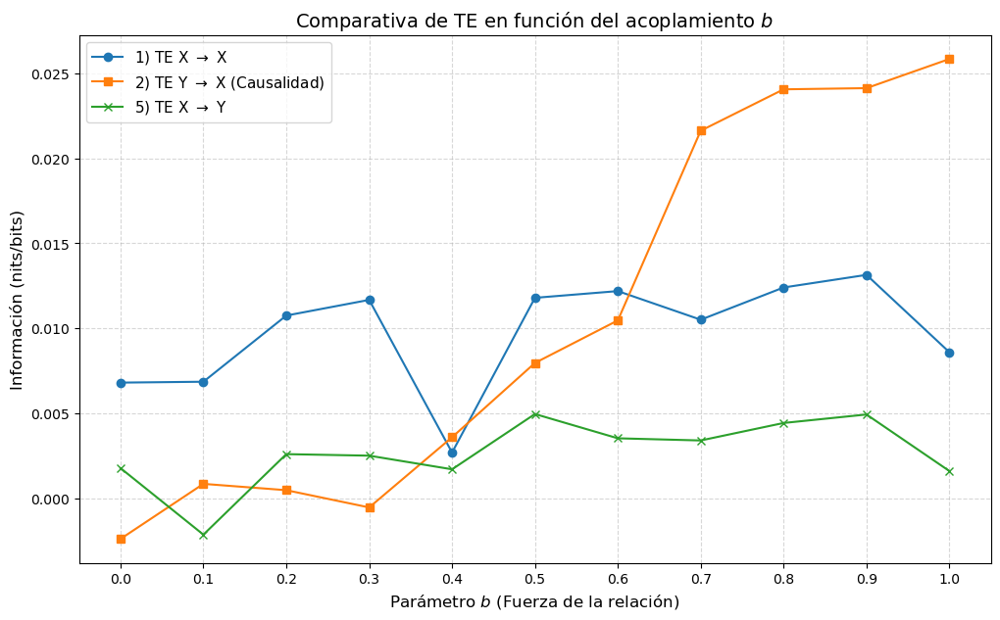

In [8]:
# Parámetros fijos
a, c = 0.5, 0.1
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 3 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 3 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

$a=0.2$ en vez de $a=0.5$:

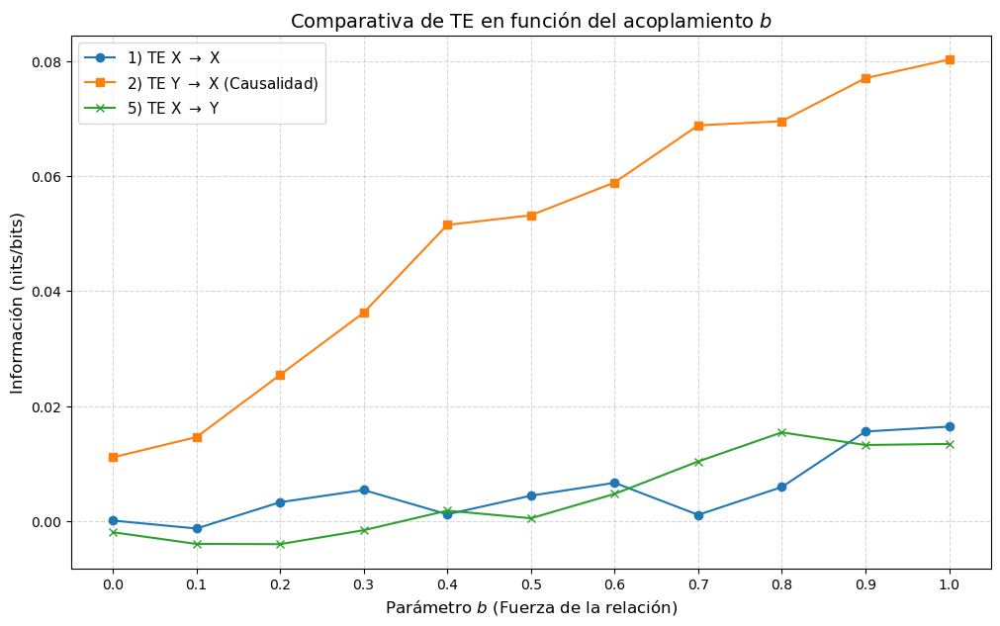

In [18]:
# Parámetros fijos
a, c = 0.2, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 3 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 3 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

Al no eliminar adecuadamente la auto-información residual que $Y$ comparte con su propio pasado, esa persistencia temporal "se filtra" y el estimador se la atribuye erróneamente a $X$. Lo mismo ocure con el parámetro $a$ que regula la información que vuleve a $X$ sobre ella misma. Pero además, en este segundo caso, observamos que en la dirección causal real la TE se detecta mucho mejor.

- Delay --> 200
- contexto destino --> 50
- contexto origen --> 70

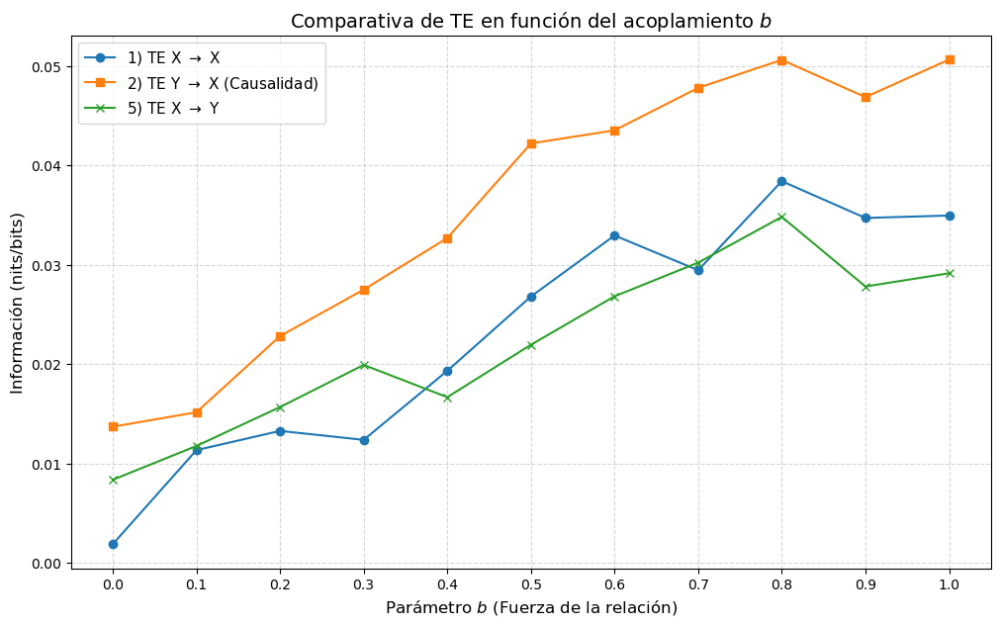

In [19]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "50")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "50")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "50")
    teCalc.setProperty("l_HISTORY", "70")
    teCalc.setProperty("DELAY", "200") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

La presencia de más contexto del necesario en el destino provoca la aparición de TE espuria.

Cuando el DELAY está fuera del margen $\tau - l_{HISTORY}$ entonces la estimación es mala:

- Delay --> 194
- contexto destino --> 5
- contexto origen --> 5

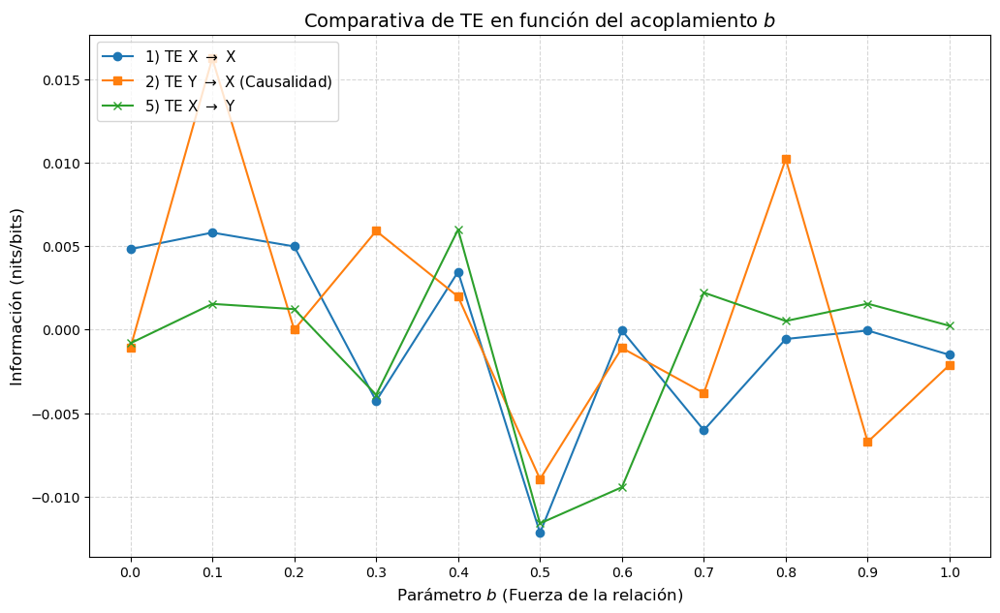

In [11]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "194") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "194") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())

    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "194") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

La única manera de obtener resultados realmente válidos sin presencia de espuriedad es identificando correctamente el retardo causal:

- Delay --> 250
- contexto destino --> 5
- contexto origen --> 5

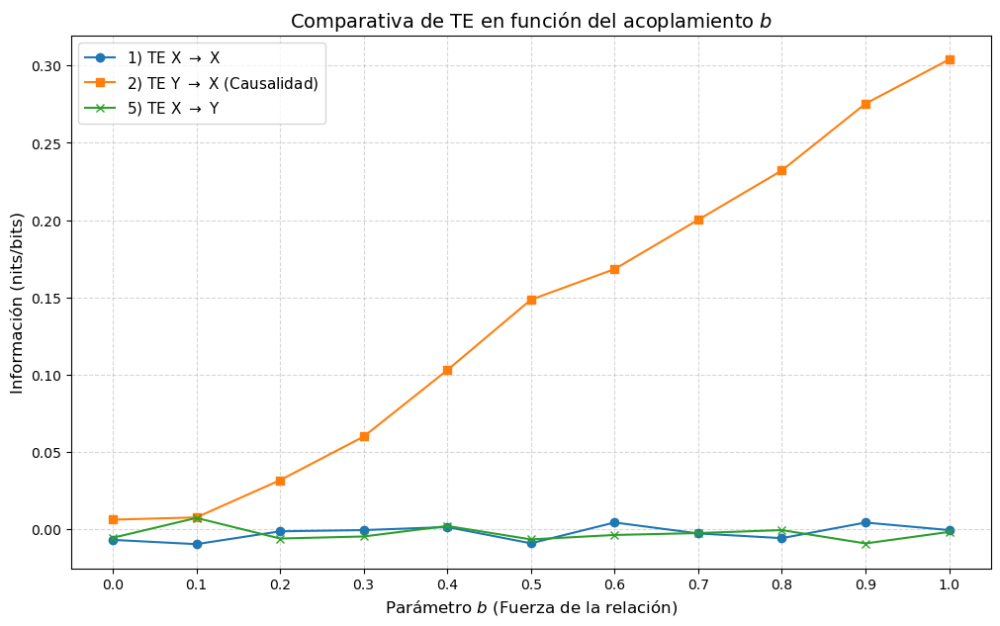

In [12]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]

    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

- Delay --> 250
- contexto destino --> 1
- contexto origen --> 1

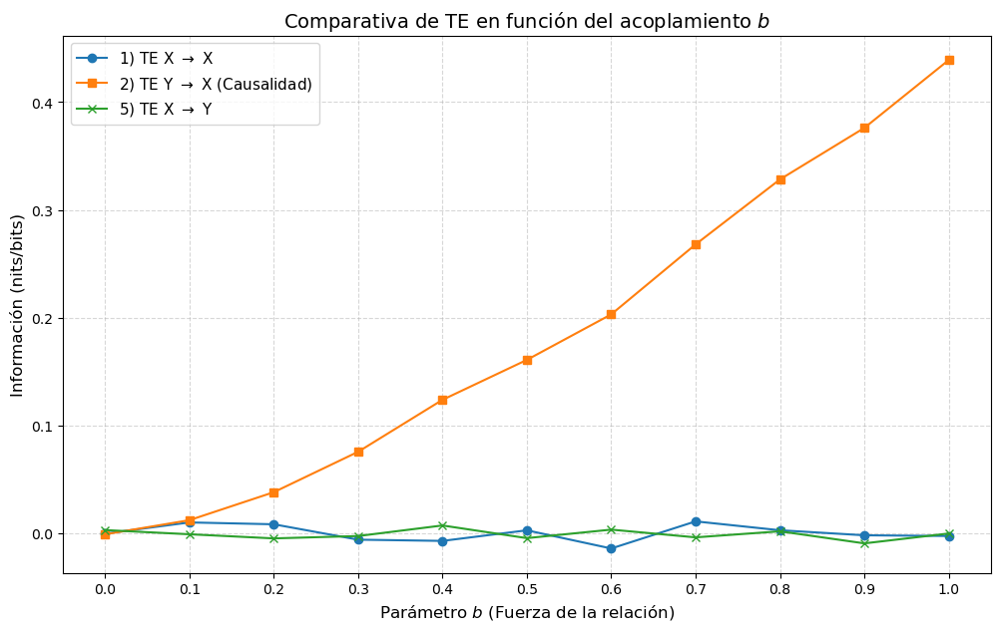

In [13]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]

    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "1")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "1")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "1")
    teCalc.setProperty("DELAY", "250") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

Y en ese caso, de atinar con el verdadero retardo causal, al fijar un espacio de menor dimensión, se detecta más intensidad de TE en el sentido correcto.

Observar la diferencia de salir del margen $\tau - l_{HISTORY}$:

- Delay --> 230
- contexto destino --> 1
- contexto origen --> 21

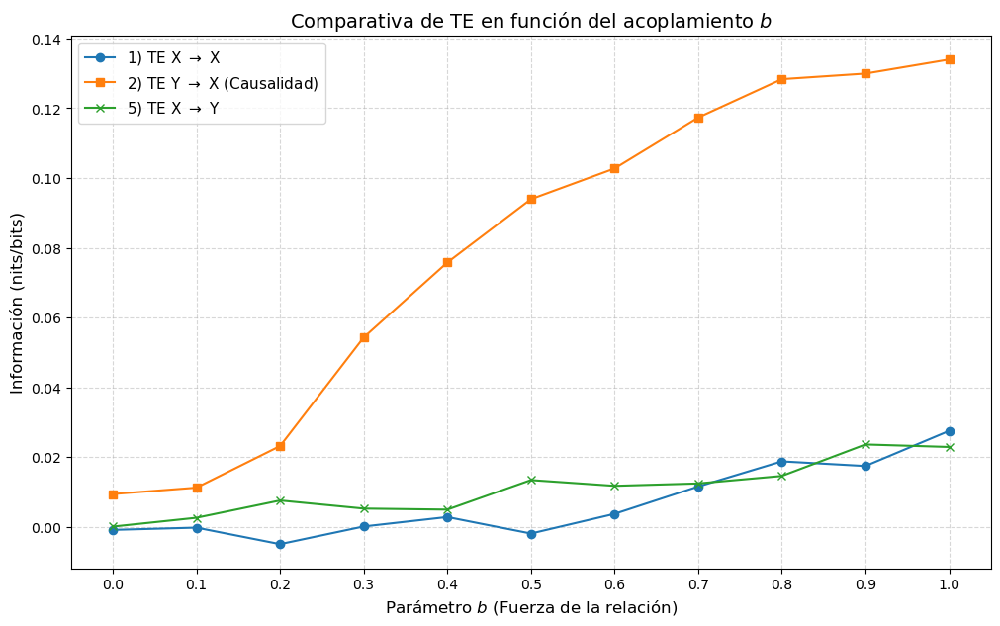

In [15]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]

    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "21")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "21")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "21")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

- Delay --> 230

- contexto destino --> 1

- contexto origen --> 19

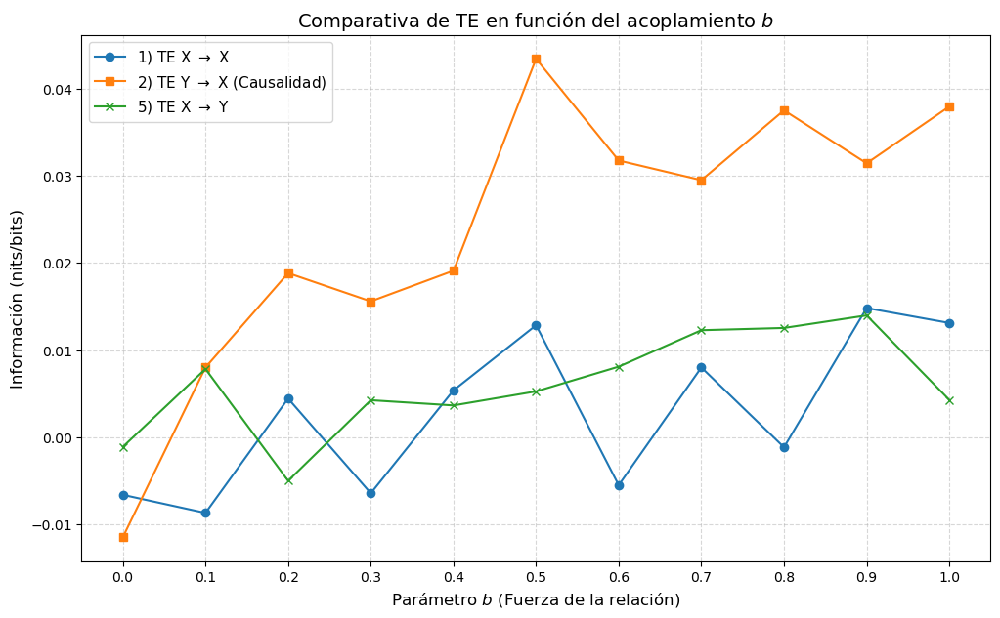

In [20]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]

    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "19")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "19")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "1")
    teCalc.setProperty("l_HISTORY", "19")
    teCalc.setProperty("DELAY", "230") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

Cuando el DELAY fijado es mayor que el real, la estimación no es buena:

- Delay --> 256
- contexto destino --> 10
- contexto origen --> 10

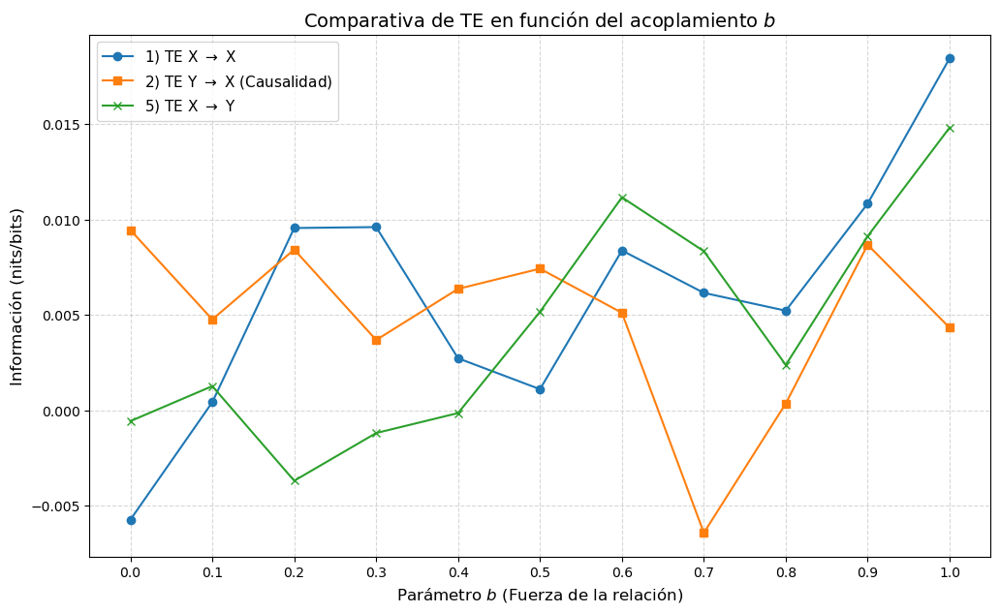

In [16]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]

    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "10")
    teCalc.setProperty("l_HISTORY", "10")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "10")
    teCalc.setProperty("l_HISTORY", "10")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "10")
    teCalc.setProperty("l_HISTORY", "10")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

- Delay --> 256
- contexto destino --> 5
- contexto origen --> 5

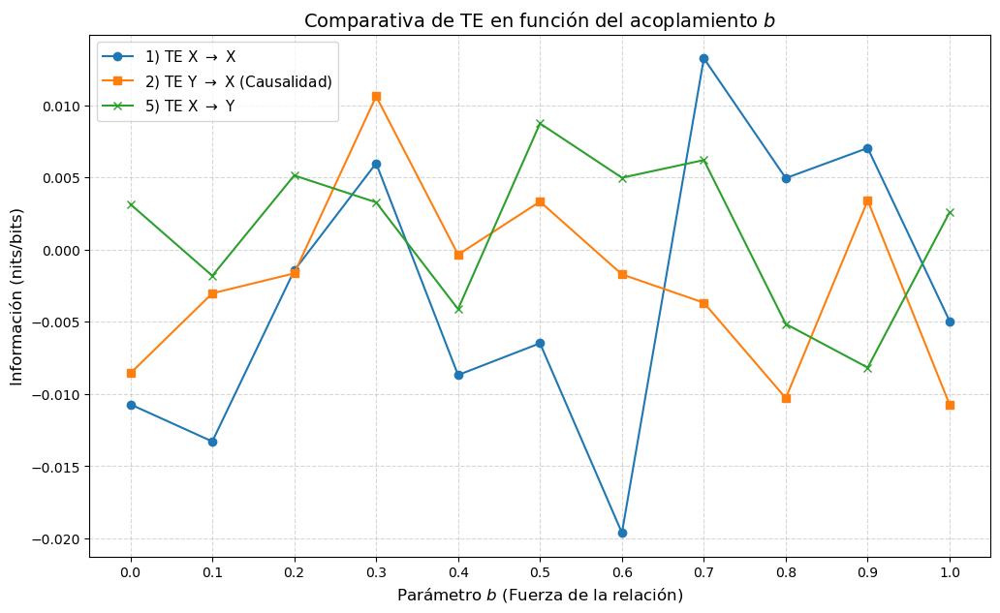

In [17]:
# Parámetros fijos
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 250
T = 5250

# Rango de valores para b
valores_b = np.arange(0.0, 1.1, 0.1)

# Listas para guardar las 5 métricas
lista_te_11 = []  # TE X -> X
lista_te_21 = []  # TE Y -> X
lista_te_12 = []  # TE X -> Y

# Bucle para barrer los valores de b
for b in valores_b:
    ex = np.random.normal(0, np.sqrt(sig_x2), T)
    ey = np.random.normal(0, np.sqrt(sig_y2), T)
    
    Z = np.zeros((T, 2))
    for t in range(0, T):
        Z[t, 1] = c * Z[t-1, 1] + ey[t]                  # Y (V2)
        Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t] # X (V1)
    
    X = Z[:, 0]
    Y = Z[:, 1]
    X = X[tau:]
    Y = Y[tau:]
    
    # --- Cálculos ---
    # 1) TE X -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(X, X)
    lista_te_11.append(teCalc.computeAverageLocalOfObservations())
    
    # 2) TE Y -> X
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(Y, X)
    lista_te_21.append(teCalc.computeAverageLocalOfObservations())
    
    # 5) TE X -> Y
    teCalc.setProperty("k", "4")
    teCalc.setProperty("k_HISTORY", "5")
    teCalc.setProperty("l_HISTORY", "5")
    teCalc.setProperty("DELAY", "256") 
    teCalc.initialise()
    teCalc.setObservations(X, Y)
    lista_te_12.append(teCalc.computeAverageLocalOfObservations())

# --- Gráfica de los resultados ---
plt.figure(figsize=(12, 7))

# Graficar las 5 curvas con diferentes colores y estilos
plt.plot(valores_b, lista_te_11,  marker='o', linestyle='-',  label='1) TE X $\\rightarrow$ X')
plt.plot(valores_b, lista_te_21,  marker='s', linestyle='-',  label='2) TE Y $\\rightarrow$ X (Causalidad)')
plt.plot(valores_b, lista_te_12,  marker='x', linestyle='-',  label='5) TE X $\\rightarrow$ Y')

plt.title('Comparativa de TE en función del acoplamiento $b$', fontsize=14)
plt.xlabel('Parámetro $b$ (Fuerza de la relación)', fontsize=12)
plt.ylabel('Información (nits/bits)', fontsize=12)
plt.xticks(valores_b)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()

La anterior batería de pruebas hace visible la fragilidad del estimador ante los parámetros que lo determinan, y todo eso en el modelo Autorregresivo donde las condiciciones están controladas. Parece inhebitable la búsqueda de métodos alternativos para explicar de forma rigurosa el comportamiento detectado, que se puedan trasladar a escenarios donde no hay un conocimiento previo de la estructura concreta del flujo de información (como las dinámicas neuronales).
Además de explicar el ruido basal, deberíamos ser capaces de conseguir un modelo de estimación que no dependa de los parámetros `k_HISTORY`, `l_HISTORY` y su interacción con el retardo causal estructural. Hemos detectado que en muchos casos los espacios de contexto son demasido amplios y las estimaciones no son robustas por la escasez de datos.


Recurrimos a la generación de datos surrogados. De ese modo demostraremos como los valores de TE espuria son fruto de correlaciones internas e inhercias provocadas por estacionariedades de las series temporales. Esta parte se desarrolla más alante en este notebook.

Hasta ahora solo se ha tratado con el sistema concreto
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$

![VAR($\tau$)](imagenes/imagen1.png)



### Transfer Entropy Multivariante y la herramienta IDTxl

Sin entrar todavía en el terreno de datos sintéticos neuronales, los propios modelos Autorregresivos permiten generar situaciones interesantes para el análisis. Ese será un paso intermedio antes de intentar explicar el comportamiento en datos neuronales.

Modificamos el valor de $Y$ que le afecta a si mismo: de  $Y_{t-1}$ a $Y_{t-10}$:
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-10} + \varepsilon_t^y 
\end{cases}
$$

![VAR($\tau$)](imagenes/imagen2.png)

La dinámica interna de la variable $Y$ cada $10$ unidades se filtra en el flujo general del sistema probocando la aparición de nuevos picos: 

Análisis de Tau: 100%|██████████| 200/200 [01:25<00:00,  2.33tau/s]
CTE V1 → V2 | V2: 100%|██████████| 200/200 [02:42<00:00,  1.23tau/s]


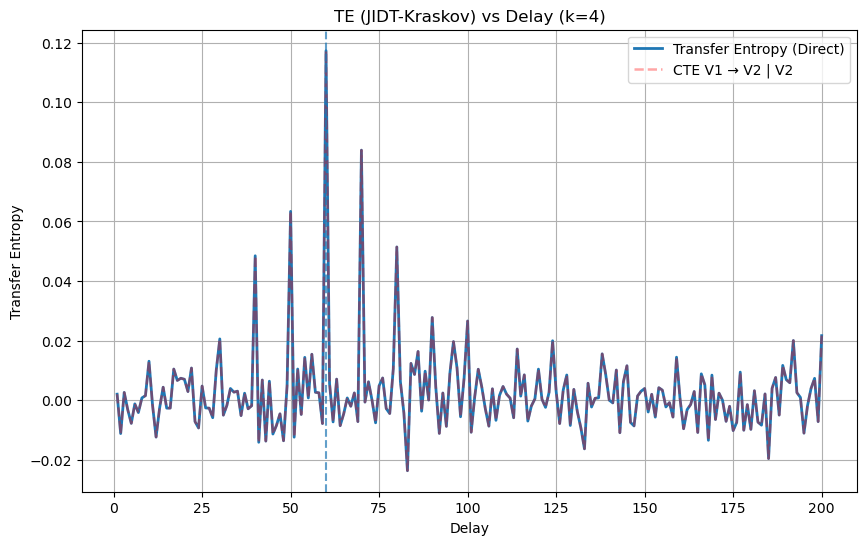

El delay óptimo para k=4 es: 60.000 ms


In [38]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 60

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=True)
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

IDTxl implementa el algoritmo de selección iterativa de padres descrito por Wibral, Lizier, Faes y Novelli, utilizando los estimadores de JIDT como motor de cálculo de la TE.

Comenzamos utilizando el anterior sistema Autorregresivo para validar la herramienta IDTxl. Se utiliza de antemano la batería de comprobaciones sobre la generación de datos surrogados que se desarrolla al final del notebook.

In [113]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 60

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y
for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]

    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values
serie_original = X[250:]
Y = Y[250:]
X = serie_original.astype(float)
Y = Y.astype(float)
data = np.vstack([Y, serie_original])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 5000 samples, 1 replications
overwriting existing data


#### Comprobación de tipo de surrogates

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : -0.001185
Media de las medias surrogate: -0.000138

Varianza original              : 1.702665
Media de las varianzas surrogate: 0.850949

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.09264
p-valor medio                : 0.00000


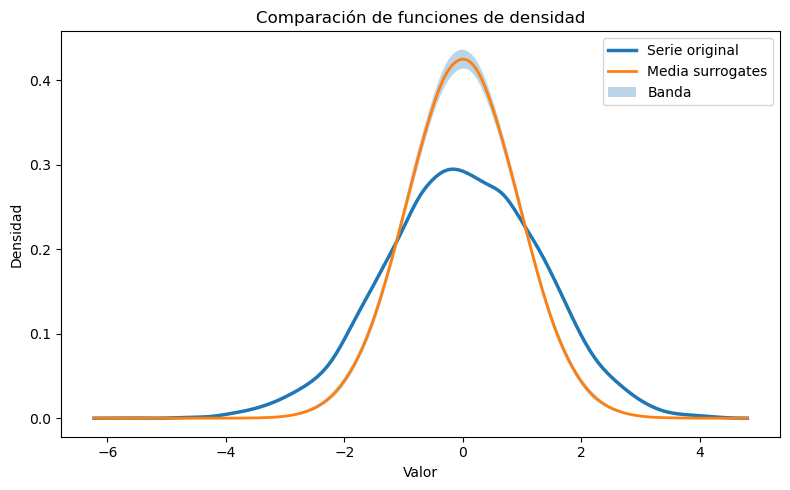


========== PSD ==========
Error relativo medio PSD: 50.336 %

========== Autocorrelación ==========
Error absoluto medio: 0.002033


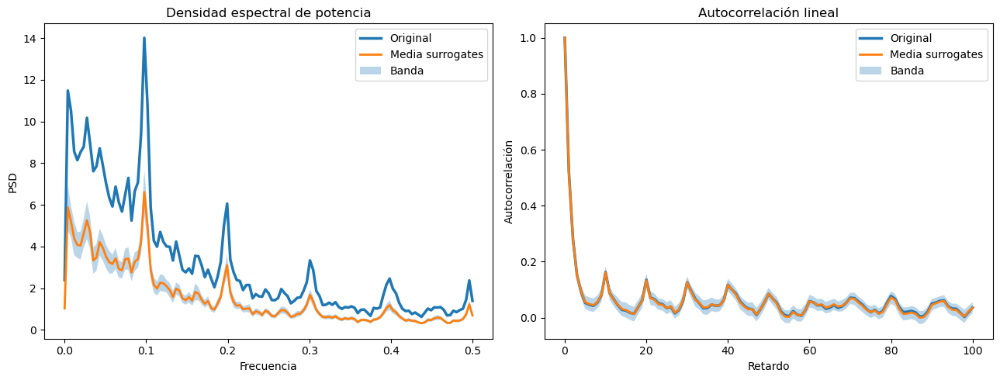


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.007030
Retardos dentro de la banda : 63.00%


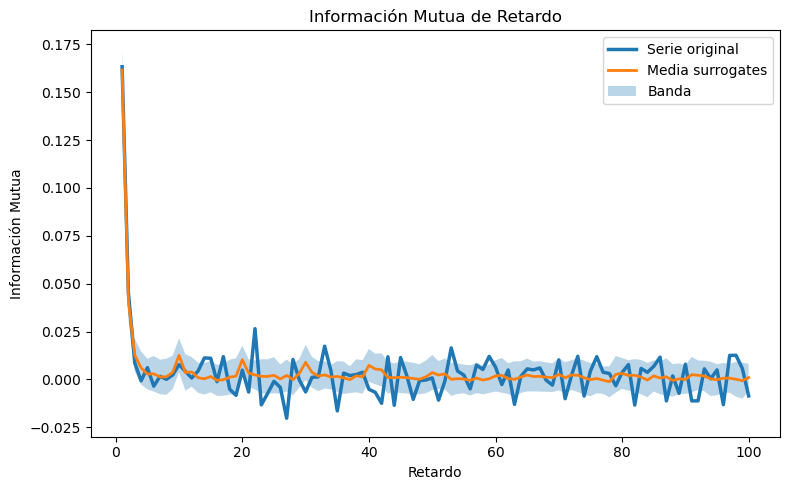

In [69]:
res_fft = validacion_surrogado(fft_surrogate, serie_original, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : -0.001185
Media de las medias surrogate: -0.001185

Varianza original              : 1.702665
Media de las varianzas surrogate: 1.702665

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


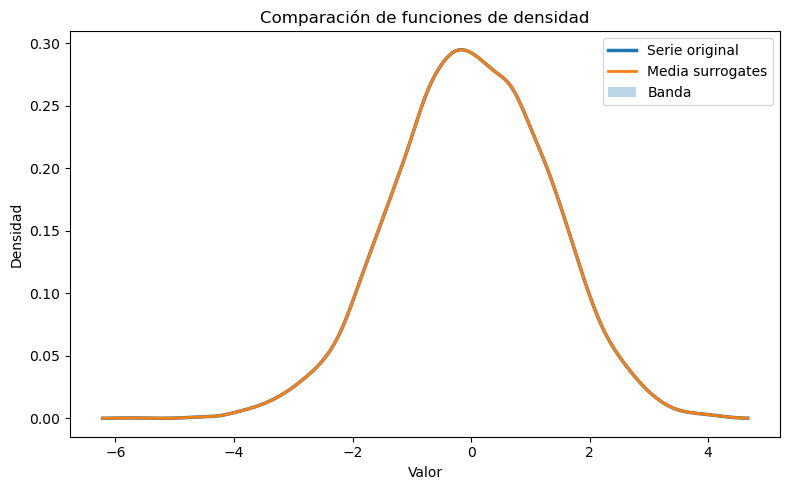


========== PSD ==========
Error relativo medio PSD: 4.136 %

========== Autocorrelación ==========
Error absoluto medio: 0.001135


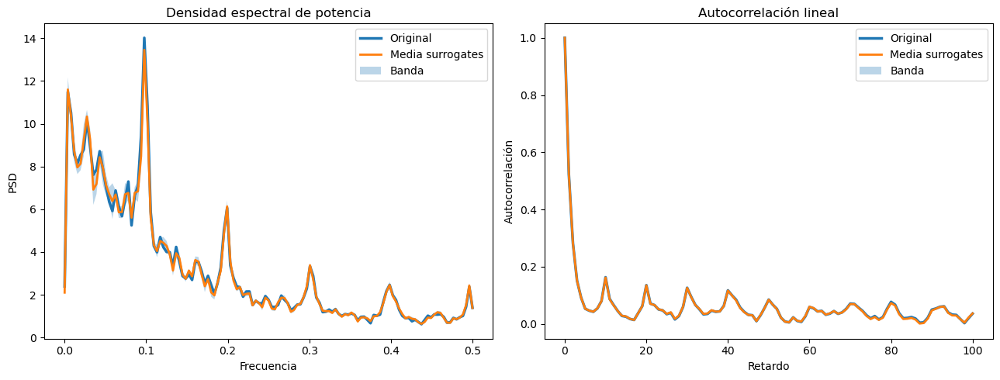


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.001153
Retardos dentro de la banda : 63.00%


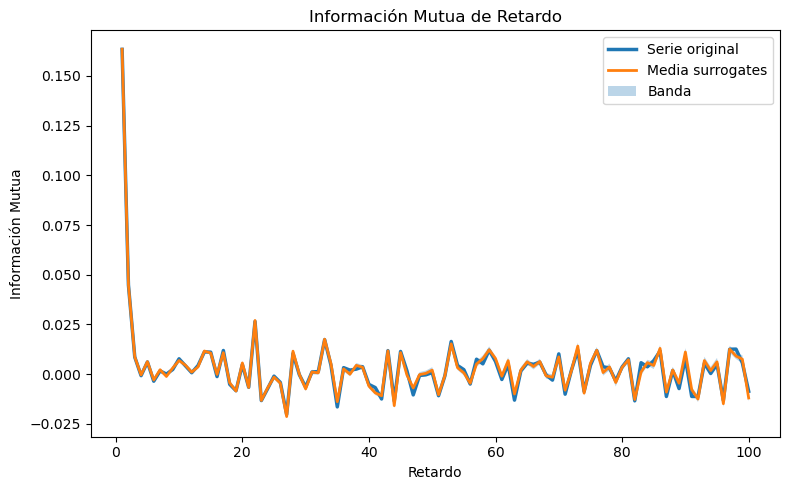

In [ ]:
res_circular = validacion_surrogado(circular_surrogate, serie_original, n_surrogates=100, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : -0.001185
Media de las medias surrogate: 0.001427

Varianza original              : 1.702665
Media de las varianzas surrogate: 1.709062

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 12/100
Porcentaje de rechazos       : 12.00%
Estadístico D medio          : 0.01741
p-valor medio                : 0.52764


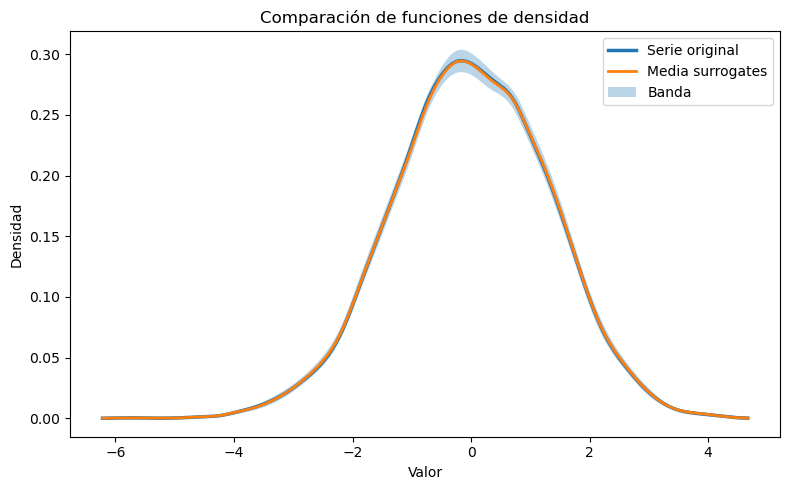


========== PSD ==========
Error relativo medio PSD: 13.465 %

========== Autocorrelación ==========
Error absoluto medio: 0.032474


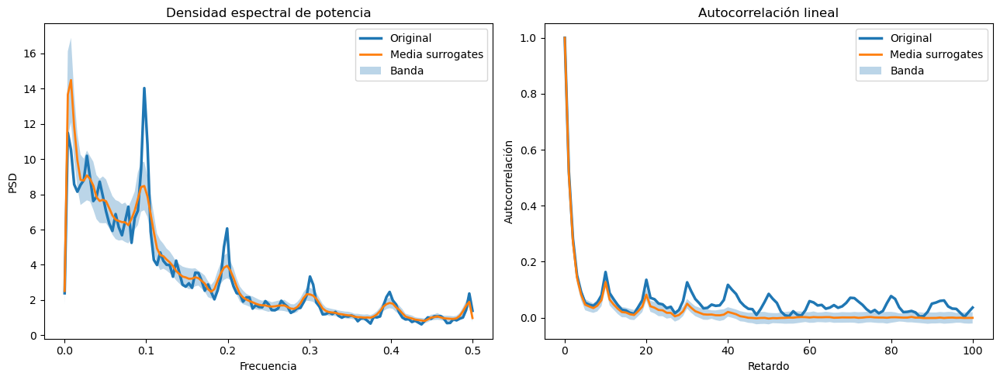


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.047983
Retardos dentro de la banda : 36.00%


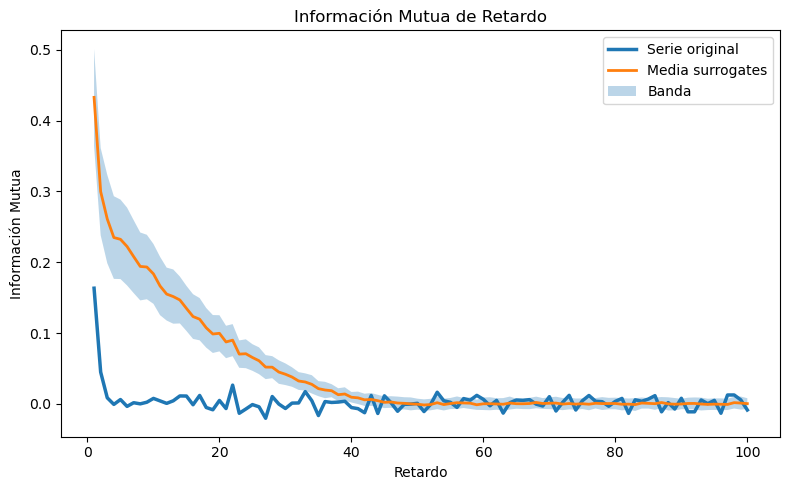

In [ ]:
res_block = validacion_surrogado(block_surrogate, serie_original, n_surrogates=100, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : -0.001185
Media de las medias surrogate: -0.001185

Varianza original              : 1.702665
Media de las varianzas surrogate: 1.702665

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00020
p-valor medio                : 1.00000


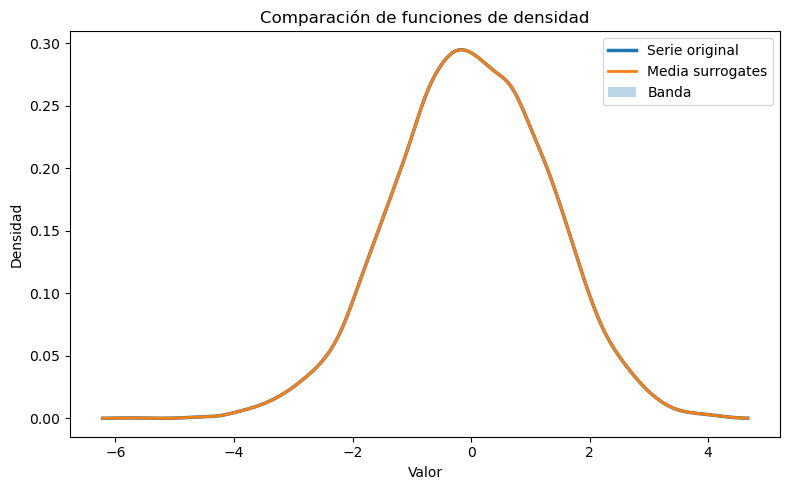


========== PSD ==========
Error relativo medio PSD: 113.247 %

========== Autocorrelación ==========
Error absoluto medio: 0.027895


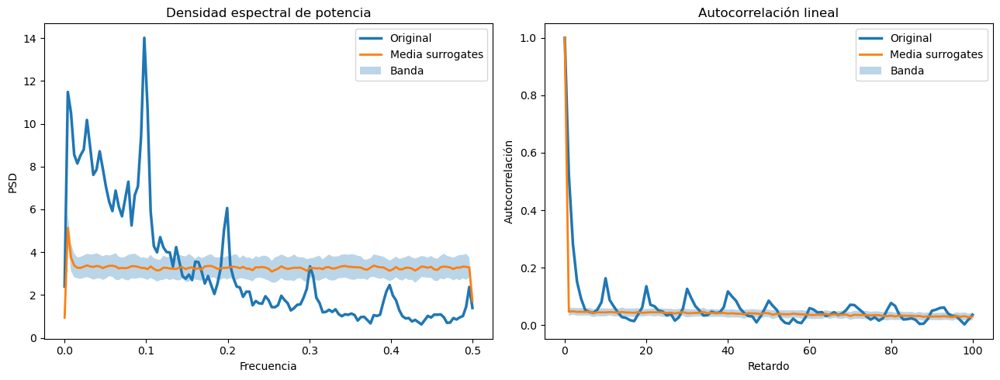


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.008710
Retardos dentro de la banda : 64.00%


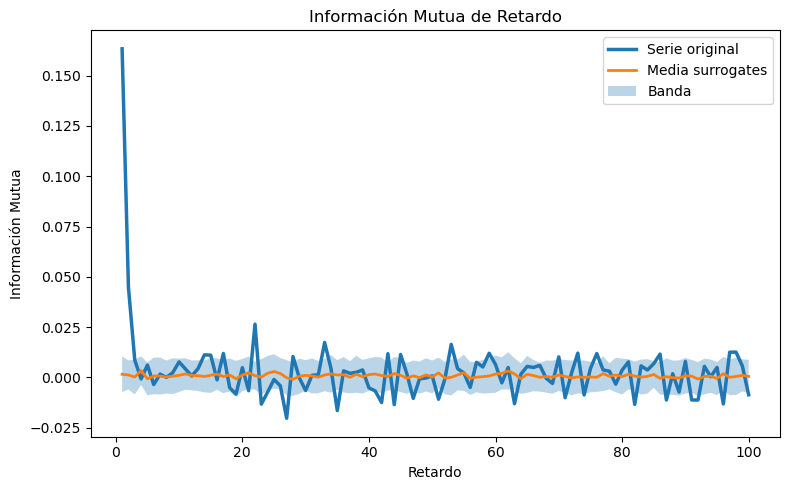

In [ ]:
res_local = validacion_surrogado(local_surrogate, serie_original, n_surrogates=100, perm_range=50)

Random Shuffling (`random`)


========== Estadísticos ==========
Media original              : -0.001185
Media de las medias surrogate: -0.001185

Varianza original              : 1.702665
Media de las varianzas surrogate: 1.702665

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


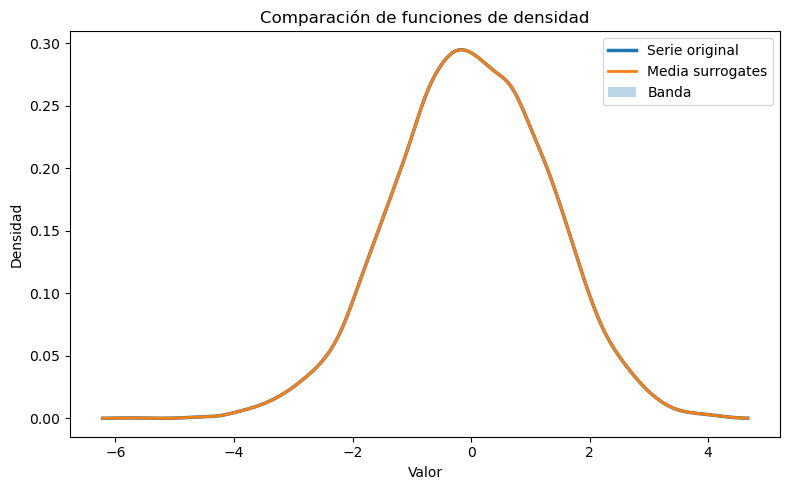


========== PSD ==========
Error relativo medio PSD: 119.657 %

========== Autocorrelación ==========
Error absoluto medio: 0.054094


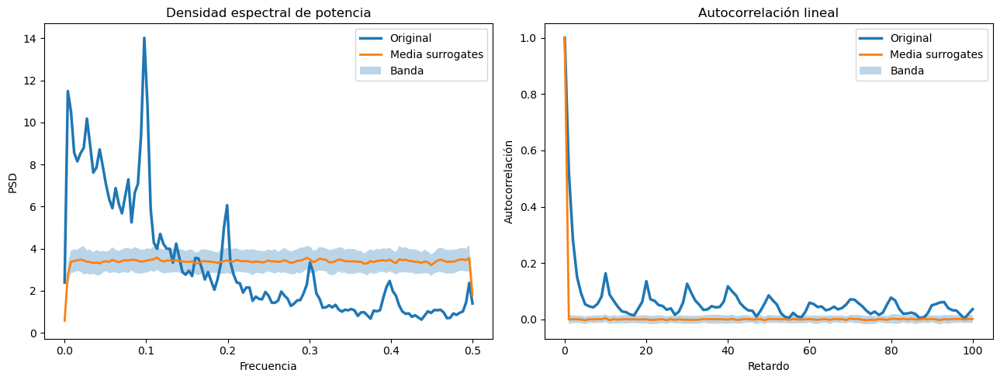


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.008789
Retardos dentro de la banda : 68.00%


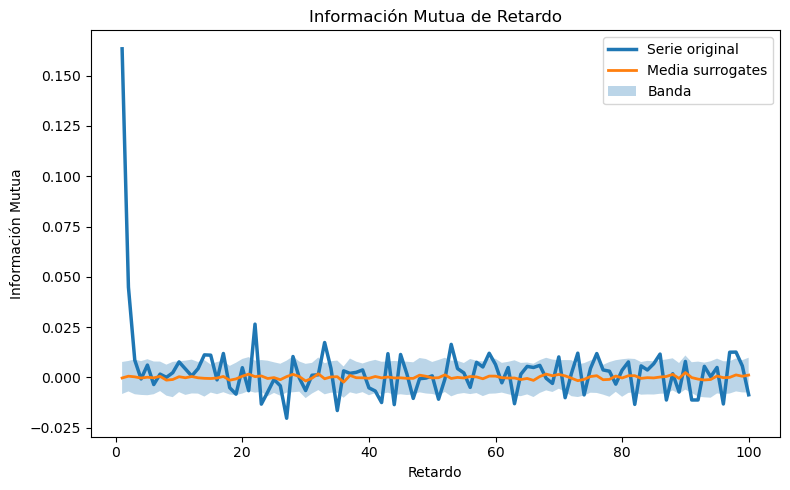

In [ ]:
res_random = validacion_surrogado(random_surrogate, serie_original, n_surrogates=100)

Dadas las comprobaciones, el mejor modelo de surrogate resulta el `circular`. Se mostrará como si se hace con un una surrogación no adecuada, como el método `local` en este caso, los resultados son erróneos. También se analizará el sentido inverso de información para comprobar que IDTxl es capaz de descartar direcciones de no causalidad.

Análisis en el sentido directo:

In [13]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 150,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 5,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results1 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 5) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (0, np.int64(33)), (0, np.int64(34)), (0, 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 60   TE = 0.115616   p = 0.0020

Resumen Ómnibus
   TE total : 0.115626
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


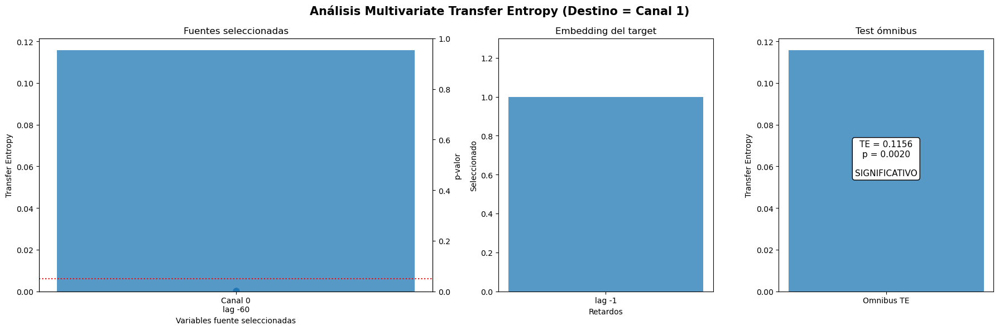

In [18]:
target = 1
res = results1.get_single_target(target=target, fdr=False)

selected_sources = res["selected_vars_sources"]
selected_target = res["selected_vars_target"]

te_values = np.asarray(res["selected_sources_te"])
p_values = np.asarray(res["selected_sources_pval"])

omnibus_te = res["omnibus_te"]
omnibus_p = res["omnibus_pval"]
omnibus_sign = res["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Análisis de Tau: 100%|██████████| 200/200 [00:41<00:00,  4.77tau/s]


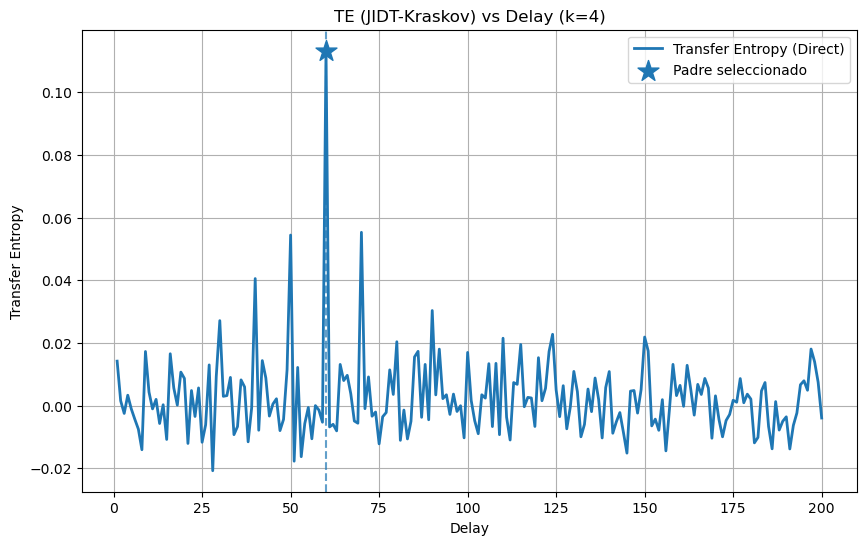

El delay óptimo para k=4 es: 60.000 ms


In [22]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 60

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False, padres_source = [60])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Análisis en el sentido inverso (para comprobar que no hay transpaso de información):

In [49]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 60

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y
for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]

    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values
X = X[250:]
Y = Y[250:]
X = X.astype(float)
Y = Y.astype(float)
data = np.vstack([X, Y])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


In [50]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 150,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 5,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results1_inverse = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 4) maximum statistic, n_perm: 200
 -- not significant

No informative sources in the target's past - adding target sample with lag 1.

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (0, np.int64(33)), 

In [52]:
target = 1
res_inverse = results1_inverse.get_single_target(target=target, fdr=False)

selected_sources = res_inverse["selected_vars_sources"]
selected_target = res_inverse["selected_vars_target"]

te_values = np.asarray(res_inverse["selected_sources_te"])
p_values = np.asarray(res_inverse["selected_sources_pval"])

omnibus_te = res_inverse["omnibus_te"]
omnibus_p = res_inverse["omnibus_pval"]
omnibus_sign = res_inverse["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
if selected_target:
    for lag in selected_target:
        print(f"   Canal {lag[0]}  -> lag -{lag[1]}")
else:
    print("   Ninguna variable del target fue seleccionada.")

print("\nVariables FUENTE seleccionadas:")
if selected_sources:
    for var, te, p in zip(selected_sources, te_values, p_values):
        print(
            f"   Canal {var[0]}  lag -{var[1]:3d}   "
            f"TE = {te:.6f}   p = {p:.4f}"
        )
else:
    print("   Ninguna variable fuente fue seleccionada.")

print("\nResumen Ómnibus")

if omnibus_te is None:
    print("   No se realizó el test ómnibus (no hubo fuentes seleccionadas).")
else:
    print(f"   TE total : {omnibus_te:.6f}")
    print(f"   p-valor  : {omnibus_p:.4f}")
    print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Ninguna variable fuente fue seleccionada.

Resumen Ómnibus
   No se realizó el test ómnibus (no hubo fuentes seleccionadas).


Analisis en el sentido directo pero con modelo de generación de surrogados`local`.

In [110]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI',
    # máximo retardo a explorar
    'max_lag_sources': 50,
    # mínimo retardo
    'min_lag_sources': 1,
    # memoria del destino
    'max_lag_target': 5,
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500,
    'n_perm_max_seq': 500,
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,
    'alpha_omnibus': 0.05,
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'local',                  
    'perm_range': 50,                 # para el modelo local
    'num_threads': 'USE_ALL'
    
}
network_analysis = MultivariateTE()
results1_local = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 4) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (0, np.int64(33)), (0, np.int64(34)), (0, 

In [111]:
target = 1
res1_local = results1_local.get_single_target(target=target, fdr=False)

selected_sources = res1_local["selected_vars_sources"]
selected_target = res1_local["selected_vars_target"]

te_values = np.asarray(res1_local["selected_sources_te"])
p_values = np.asarray(res1_local["selected_sources_pval"])

omnibus_te = res1_local["omnibus_te"]
omnibus_p = res1_local["omnibus_pval"]
omnibus_sign = res1_local["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
if selected_target:
    for lag in selected_target:
        print(f"   Canal {lag[0]}  -> lag -{lag[1]}")
else:
    print("   Ninguna variable del target fue seleccionada.")

print("\nVariables FUENTE seleccionadas:")
if selected_sources:
    for var, te, p in zip(selected_sources, te_values, p_values):
        print(
            f"   Canal {var[0]}  lag -{var[1]:3d}   "
            f"TE = {te:.6f}   p = {p:.4f}"
        )
else:
    print("   Ninguna variable fuente fue seleccionada.")

print("\nResumen Ómnibus")

if omnibus_te is None:
    print("   No se realizó el test ómnibus (no hubo fuentes seleccionadas).")
else:
    print(f"   TE total : {omnibus_te:.6f}")
    print(f"   p-valor  : {omnibus_p:.4f}")
    print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 50   TE = 0.072004   p = 0.0020

Resumen Ómnibus
   TE total : 0.072001
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


Los contratses internos son menos exactos y fiables ya que la los surrogates hacen peor su labor de decosntrucción. Como se ve, el resultado puede ser erróneo.

---

---

Modificamos el valor de $\tau$ para que el transpaso de información $Y_{t-\tau}$ --> $X_t$ sea posterior en el tiempo que el de $Y_{t-1}$ en $Y_{t-20}$:
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-20} + \varepsilon_t^y 
\end{cases}
$$

![VAR($\tau$)](imagenes/imagen3.png)

por ejemplo, $tau=10$.

Análisis de Tau: 100%|██████████| 200/200 [01:12<00:00,  2.74tau/s]
CTE V1 → V2 | V2: 100%|██████████| 200/200 [02:32<00:00,  1.31tau/s]


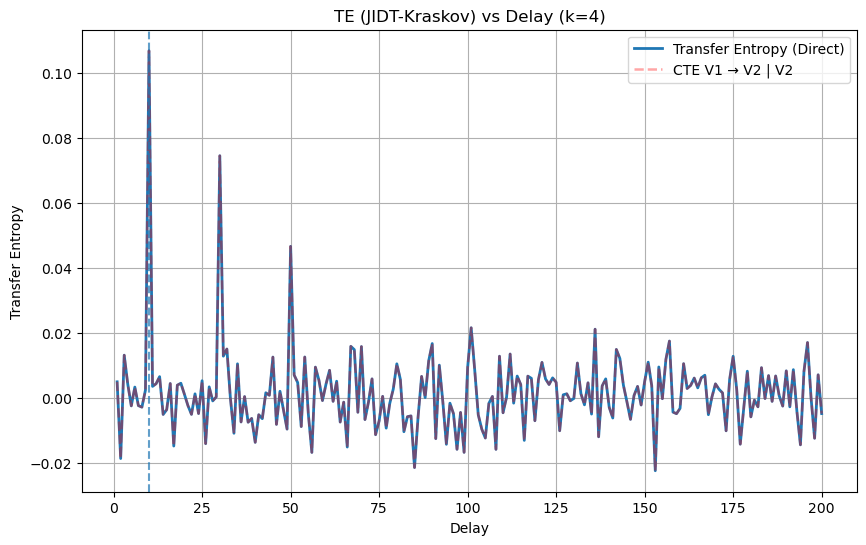

El delay óptimo para k=4 es: 10.000 ms


In [40]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 10

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-20, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=True)
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

In [100]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 10

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-20, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]
X = X.astype(float)
Y = Y.astype(float)
data = np.vstack([Y, X])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


In [54]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 75,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 5,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results2 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 5) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (0, np.int64(33)), (0, np.int64(34)), (0, 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 10   TE = 0.127268   p = 0.0020

Resumen Ómnibus
   TE total : 0.127268
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


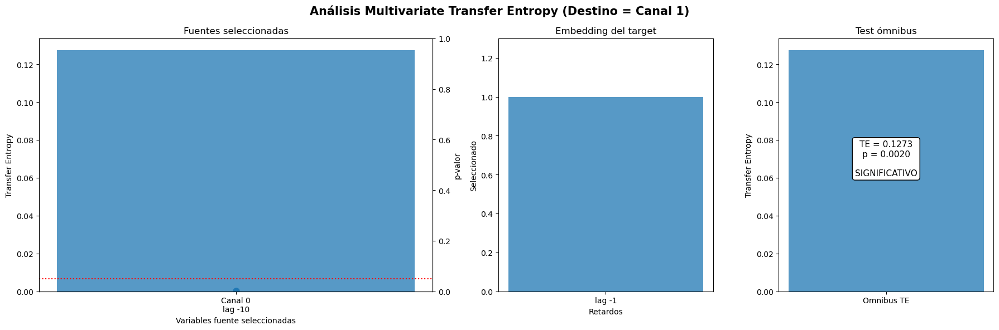

In [55]:
target = 1
res2 = results2.get_single_target(target=target, fdr=False)

selected_sources = res2["selected_vars_sources"]
selected_target = res2["selected_vars_target"]

te_values = np.asarray(res2["selected_sources_te"])
p_values = np.asarray(res2["selected_sources_pval"])

omnibus_te = res2["omnibus_te"]
omnibus_p = res2["omnibus_pval"]
omnibus_sign = res2["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Análisis de Tau: 100%|██████████| 200/200 [00:33<00:00,  5.90tau/s]


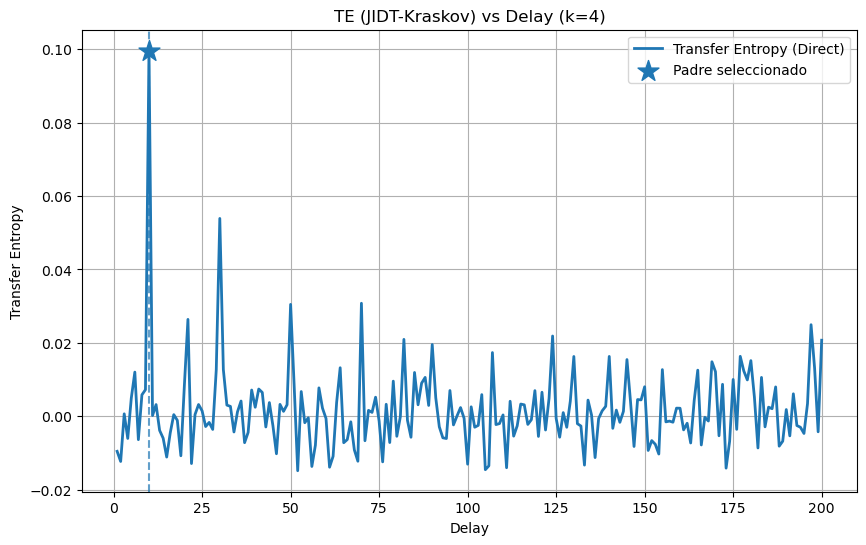

El delay óptimo para k=4 es: 10.000 ms


In [23]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 10

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-20, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False, padres_source = [10])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Observar que la intensidad de TE se percibe menor al usar un modelo de surrogación que no es el óptimo (en este caso `random`).

In [102]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI',
    # máximo retardo a explorar
    'max_lag_sources': 50,
    # mínimo retardo
    'min_lag_sources': 1,
    # memoria del destino
    'max_lag_target': 5,
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500,
    'n_perm_max_seq': 500,
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,
    'alpha_omnibus': 0.05,
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'random' ,                  #  'perm_range': 50     para el modelo local
    'num_threads': 'USE_ALL'
    
}
network_analysis = MultivariateTE()
results2_random = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 3) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (0, np.int64(33)), (0, np.int64(34)), (0, 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 10   TE = 0.085921   p = 0.0020

Resumen Ómnibus
   TE total : 0.085921
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


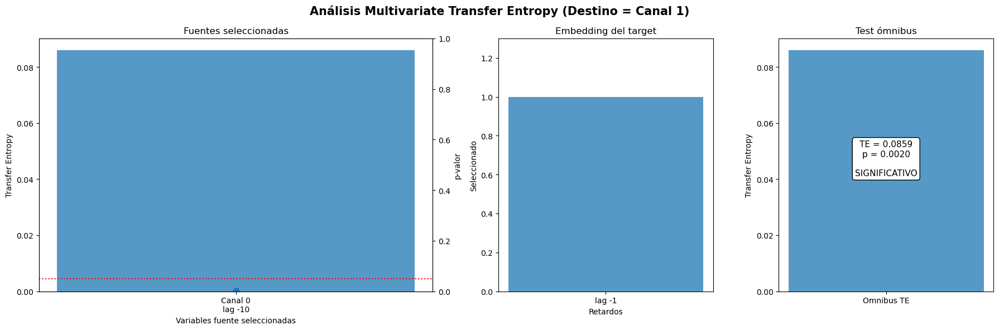

In [ ]:
target = 1
res2_ran = results2_random.get_single_target(target=target, fdr=False)

selected_sources = res2_ran["selected_vars_sources"]
selected_target = res2_ran["selected_vars_target"]

te_values = np.asarray(res2_ran["selected_sources_te"])
p_values = np.asarray(res2_ran["selected_sources_pval"])

omnibus_te = res2_ran["omnibus_te"]
omnibus_p = res2_ran["omnibus_pval"]
omnibus_sign = res2_ran["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

---

---

Analizamos ahora un sistema aún más complejo fijando $Y_{t-\tau}$:
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-\tau} + \varepsilon_t^y 
\end{cases}
$$

![VAR($\tau$)](imagenes/imagen4.png)

$\tau=40$.

Análisis de Tau: 100%|██████████| 200/200 [00:13<00:00, 14.62tau/s]
CTE V1 → V2 | V2: 100%|██████████| 200/200 [00:26<00:00,  7.61tau/s]


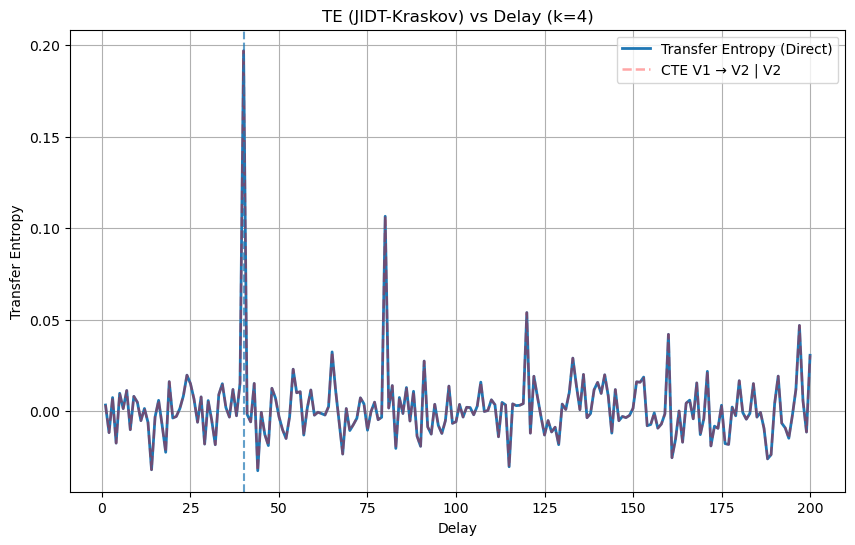

El delay óptimo para k=4 es: 40.000 ms


In [ ]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 40

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-tau, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=True, padres_source = [])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

In [97]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 40

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-tau, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values
X = X[250:]
Y = Y[250:]
X = X.astype(float)
Y = Y.astype(float)
data = np.vstack([Y, X])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


In [98]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 50,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 20,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results3 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 20) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, n

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 40   TE = 0.193782   p = 0.0020

Resumen Ómnibus
   TE total : 0.193780
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


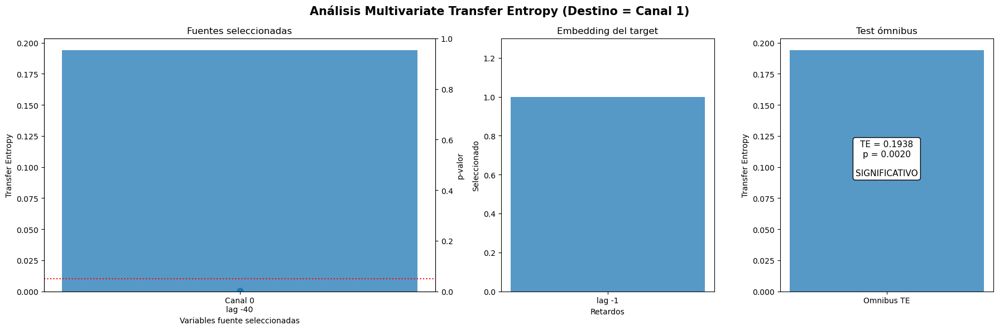

In [ ]:
target = 1
res3 = results3.get_single_target(target=target, fdr=False)

selected_sources = res3["selected_vars_sources"]
selected_target = res3["selected_vars_target"]

te_values = np.asarray(res3["selected_sources_te"])
p_values = np.asarray(res3["selected_sources_pval"])

omnibus_te = res3["omnibus_te"]
omnibus_p = res3["omnibus_pval"]
omnibus_sign = res3["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Análisis de Tau: 100%|██████████| 200/200 [00:14<00:00, 13.99tau/s]


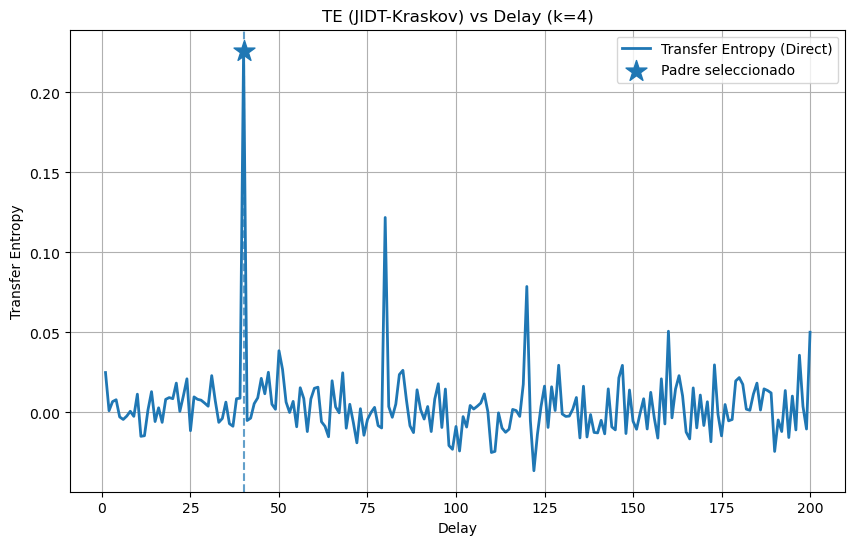

El delay óptimo para k=4 es: 40.000 ms


In [24]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.4, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 40

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-tau, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False, padres_source = [40])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

---

---

La ventaja de este método es que debría ser capaz de detectar varios padres causales:
$$
\begin{cases} 
X_t = a X_{t-1}+ d X_{t-15} + b Y_{t-\tau_1} + e Y_{t-\tau_2} + \varepsilon_t^x \\ 
Y_t = c Y_{t-10} + \varepsilon_t^y 
\end{cases}
$$

por ejemplo, $tau_1=20$ y $tau_2=25$ .

![VAR($\tau$)](imagenes/imagen5.png)


Análisis de Tau: 100%|██████████| 200/200 [00:15<00:00, 13.21tau/s]
CTE V1 → V2 | V2: 100%|██████████| 200/200 [00:24<00:00,  8.02tau/s]


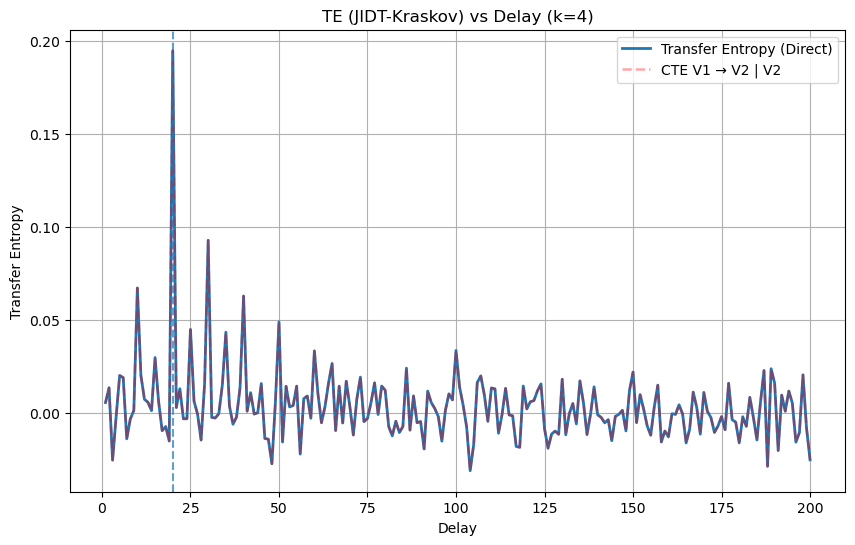

El delay óptimo para k=4 es: 20.000 ms


In [ ]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.6, 0.6, 0.7, 0.3, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=True, padres_source = [])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

In [76]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.6, 0.6, 0.7, 0.3, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

serie_original = X[250:]
Y = Y[250:]
X = serie_original.astype(float)
Y = Y.astype(float)
data = np.vstack([Y, X])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


#### Comprobación de tipo de surrogates

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : 1.228602
Media de las medias surrogate: -0.011266

Varianza original              : 7.053074
Media de las varianzas surrogate: 3.495384

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.25936
p-valor medio                : 0.00001


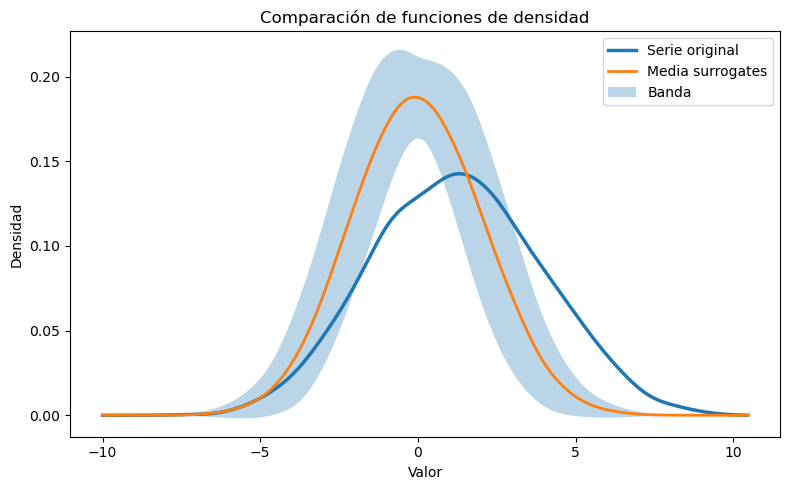


========== PSD ==========
Error relativo medio PSD: 49.300 %

========== Autocorrelación ==========
Error absoluto medio: 0.013365


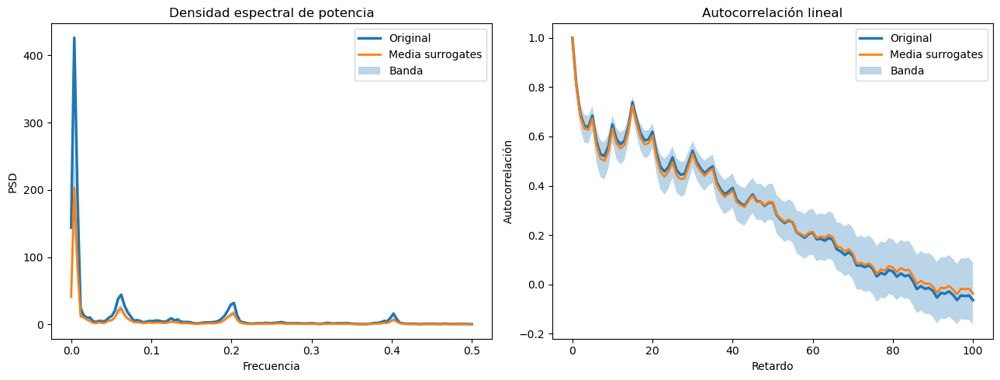


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.015655
Retardos dentro de la banda : 82.00%


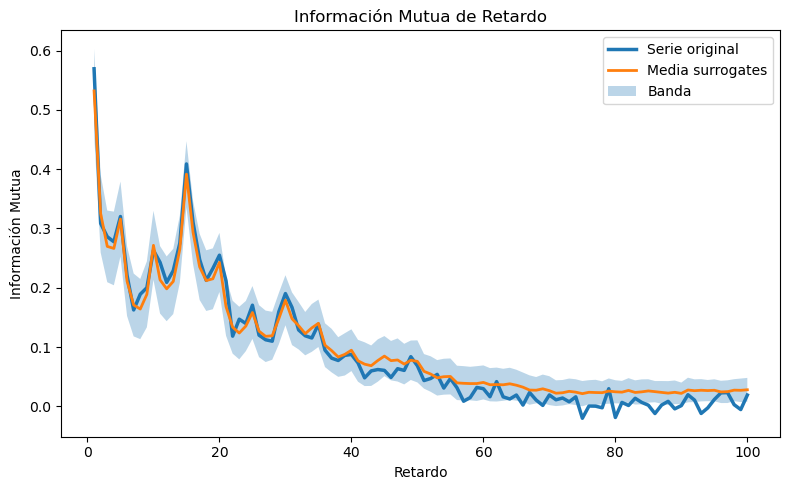

In [77]:
res_fft = validacion_surrogado(fft_surrogate, serie_original, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : 1.228602
Media de las medias surrogate: 1.228602

Varianza original              : 7.053074
Media de las varianzas surrogate: 7.053074

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


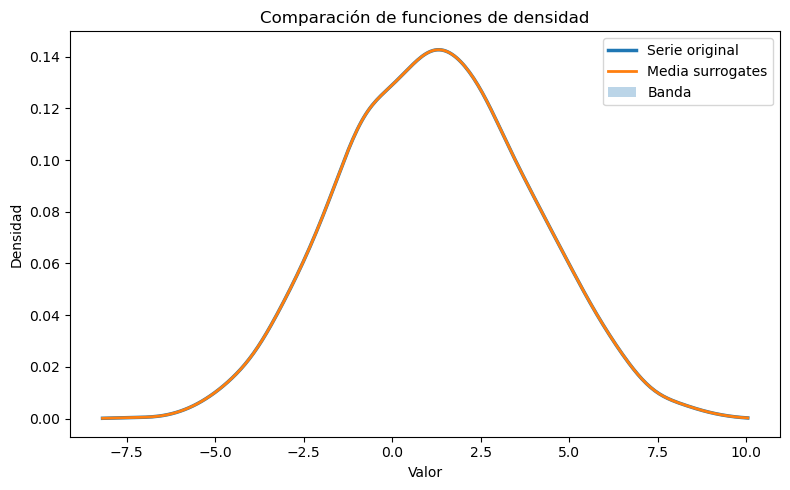


========== PSD ==========
Error relativo medio PSD: 9.788 %

========== Autocorrelación ==========
Error absoluto medio: 0.004527


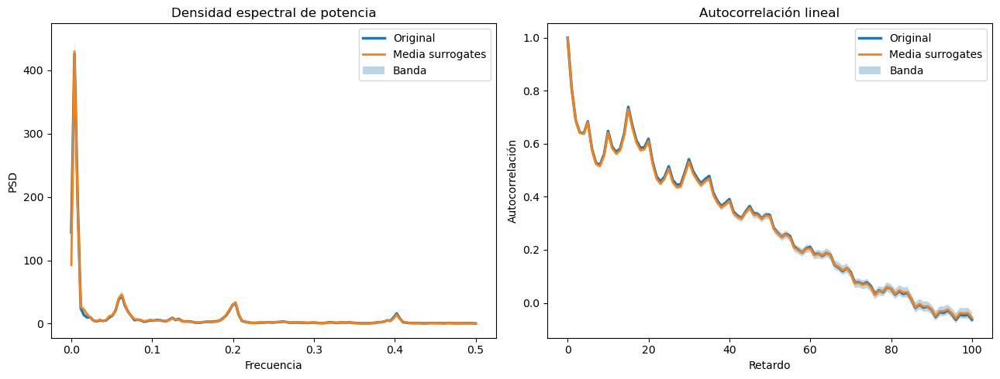


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.003873
Retardos dentro de la banda : 60.00%


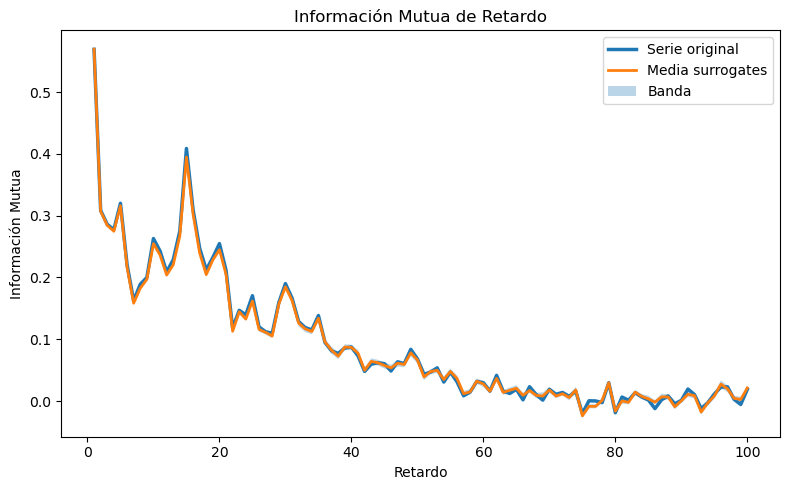

In [78]:
res_circular = validacion_surrogado(circular_surrogate, serie_original, n_surrogates=100, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : 1.228602
Media de las medias surrogate: 1.234682

Varianza original              : 7.053074
Media de las varianzas surrogate: 7.099998

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 63/100
Porcentaje de rechazos       : 63.00%
Estadístico D medio          : 0.05938
p-valor medio                : 0.16018


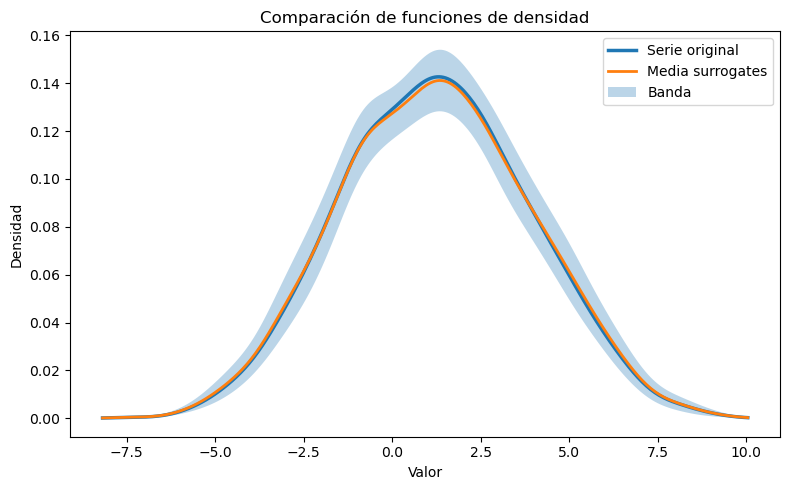


========== PSD ==========
Error relativo medio PSD: 60.684 %

========== Autocorrelación ==========
Error absoluto medio: 0.176416


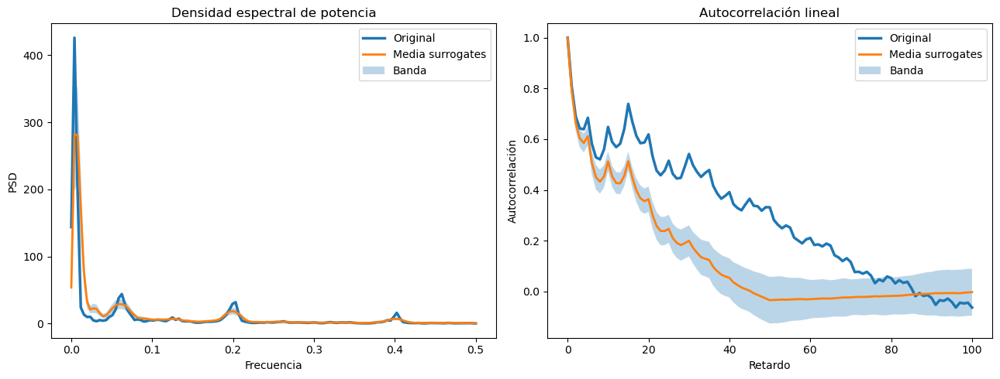


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.043599
Retardos dentro de la banda : 45.00%


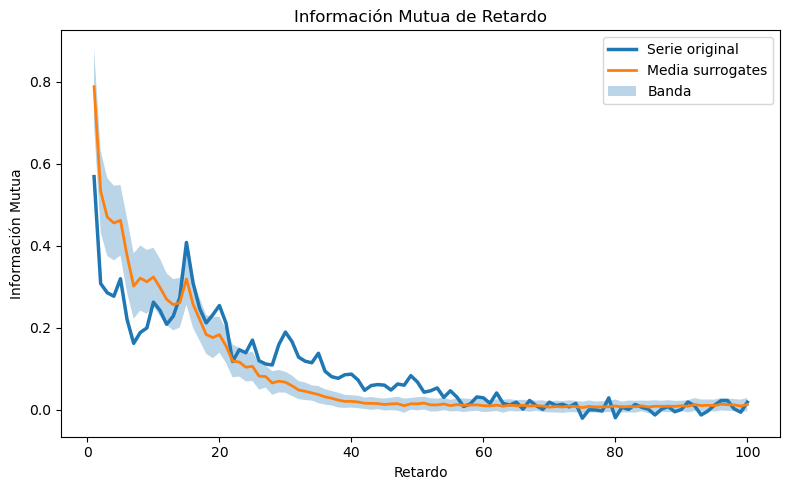

In [79]:
res_block = validacion_surrogado(block_surrogate, serie_original, n_surrogates=100, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : 1.228602
Media de las medias surrogate: 1.228602

Varianza original              : 7.053074
Media de las varianzas surrogate: 7.053074


C:\Users\alons\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)



========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00050
p-valor medio                : 1.00000


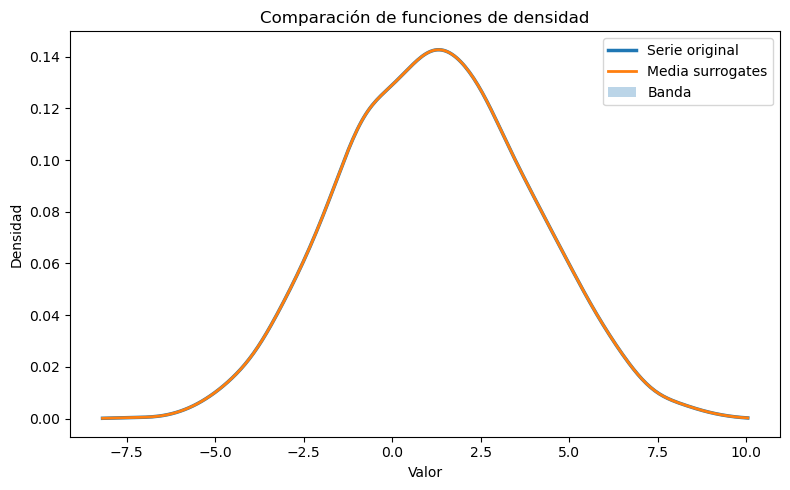


========== PSD ==========
Error relativo medio PSD: 519.073 %

========== Autocorrelación ==========
Error absoluto medio: 0.179599


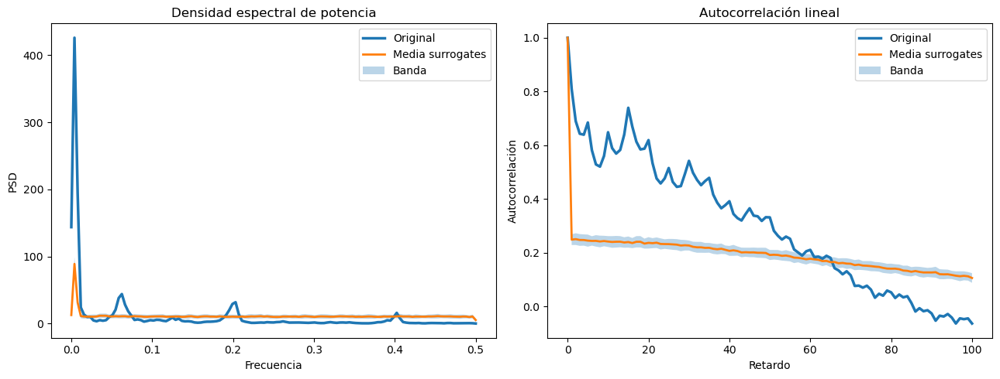


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.077815
Retardos dentro de la banda : 34.00%


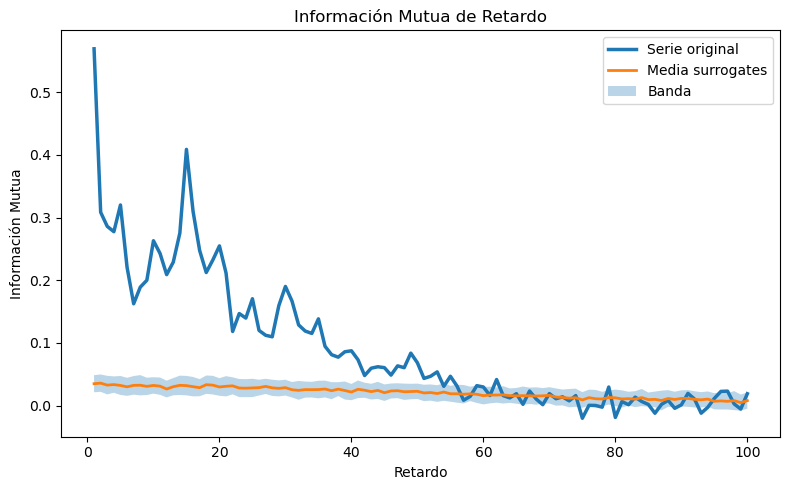

In [80]:
res_local = validacion_surrogado(local_surrogate, serie_original, n_surrogates=100, perm_range=50)

Random Shuffling (`random`)


========== Estadísticos ==========
Media original              : 1.228602
Media de las medias surrogate: 1.228602

Varianza original              : 7.053074
Media de las varianzas surrogate: 7.053074

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


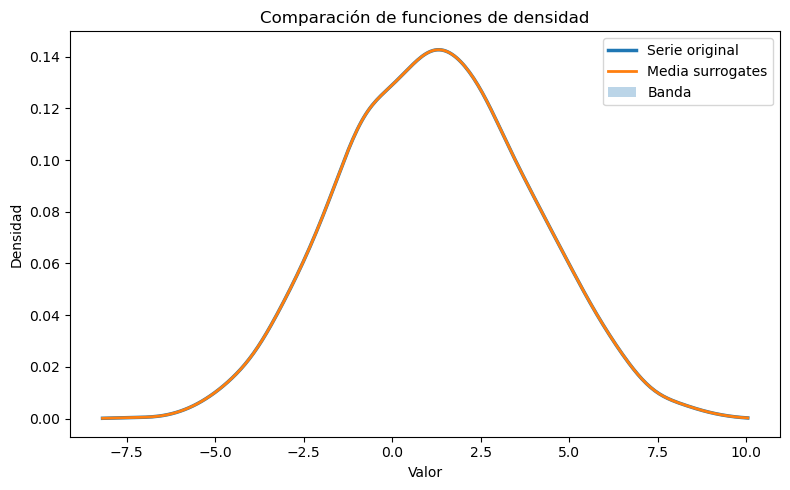


========== PSD ==========
Error relativo medio PSD: 715.024 %

========== Autocorrelación ==========
Error absoluto medio: 0.299173


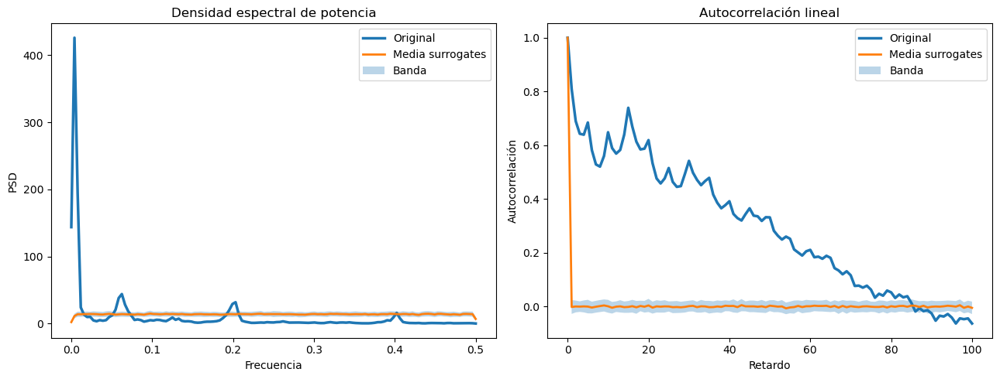


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.094215
Retardos dentro de la banda : 24.00%


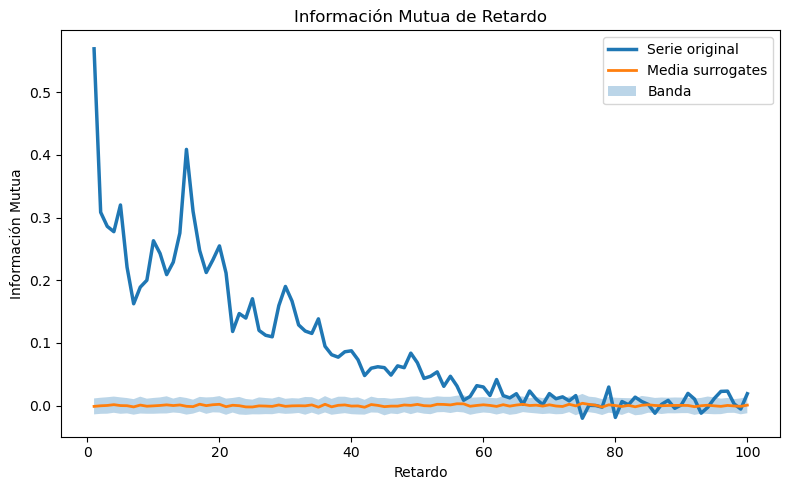

In [81]:
res_random = validacion_surrogado(random_surrogate, serie_original, n_surrogates=100)

El que mejor funciona vuelve a ser el `circular`.

In [61]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 50,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 20,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results4 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 15) maximum statistic, n_perm: 200
testing candidate: (1, 17) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1
   Canal 1  -> lag -15

Variables FUENTE seleccionadas:
   Canal 0  lag - 20   TE = 0.181088   p = 0.0020
   Canal 0  lag - 25   TE = 0.049810   p = 0.0020

Resumen Ómnibus
   TE total : 0.212472
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


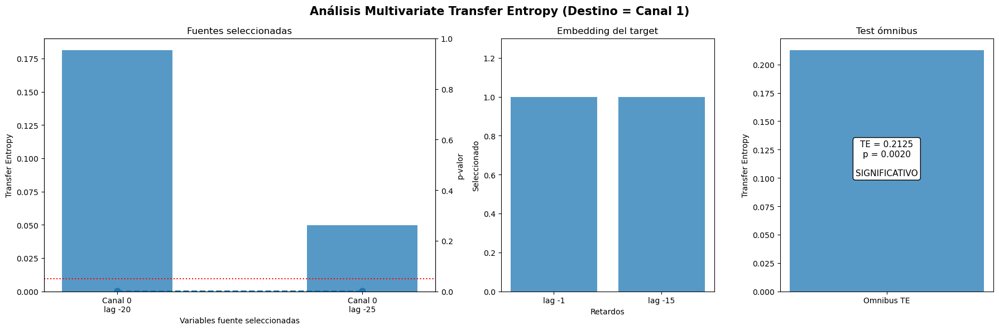

In [ ]:
target = 1
res4 = results4.get_single_target(target=target, fdr=False)

selected_sources = res4["selected_vars_sources"]
selected_target = res4["selected_vars_target"]

te_values = np.asarray(res4["selected_sources_te"])
p_values = np.asarray(res4["selected_sources_pval"])

omnibus_te = res4["omnibus_te"]
omnibus_p = res4["omnibus_pval"]
omnibus_sign = res4["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Análisis de Tau: 100%|██████████| 200/200 [00:13<00:00, 14.44tau/s]


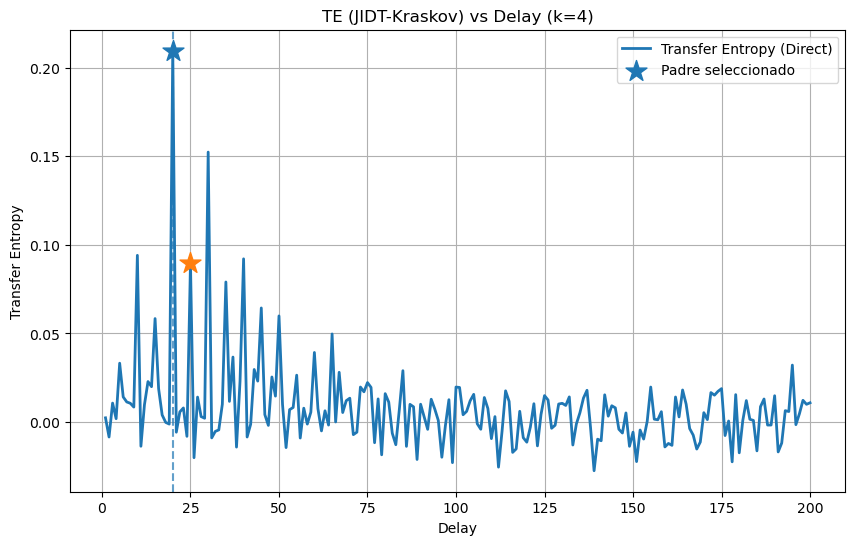

El delay óptimo para k=4 es: 20.000 ms


In [25]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.6, 0.6, 0.7, 0.3, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]

vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=n_vecinos, max_steps=200, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False, padres_source = [20,25])
    
    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Análisis en la dirección inversa:

In [64]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.6, 0.6, 0.7, 0.3, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

X = X[250:]
Y = Y[250:]
X = X.astype(float)
Y = Y.astype(float)
data = np.vstack([X, Y])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


In [65]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 50,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 20,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results4_inverse = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20)]
testing candidate: (1, 10) maximum statistic, n_perm: 200
testing candidate: (1, 6) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, n

In [67]:
target = 1
res4_inv = results4_inverse.get_single_target(target=target, fdr=False)

selected_sources = res4_inv["selected_vars_sources"]
selected_target = res4_inv["selected_vars_target"]

te_values = np.asarray(res4_inv["selected_sources_te"])
p_values = np.asarray(res4_inv["selected_sources_pval"])

omnibus_te = res4_inv["omnibus_te"]
omnibus_p = res4_inv["omnibus_pval"]
omnibus_sign = res4_inv["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
if selected_target:
    for lag in selected_target:
        print(f"   Canal {lag[0]}  -> lag -{lag[1]}")
else:
    print("   Ninguna variable del target fue seleccionada.")

print("\nVariables FUENTE seleccionadas:")
if selected_sources:
    for var, te, p in zip(selected_sources, te_values, p_values):
        print(
            f"   Canal {var[0]}  lag -{var[1]:3d}   "
            f"TE = {te:.6f}   p = {p:.4f}"
        )
else:
    print("   Ninguna variable fuente fue seleccionada.")

print("\nResumen Ómnibus")

if omnibus_te is None:
    print("   No se realizó el test ómnibus (no hubo fuentes seleccionadas).")
else:
    print(f"   TE total : {omnibus_te:.6f}")
    print(f"   p-valor  : {omnibus_p:.4f}")
    print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -10

Variables FUENTE seleccionadas:
   Ninguna variable fuente fue seleccionada.

Resumen Ómnibus
   No se realizó el test ómnibus (no hubo fuentes seleccionadas).


Y con un surrogate que no es el óptimo (`local`):

In [84]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.6, 0.6, 0.7, 0.3, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

serie_original = X[250:]
Y = Y[250:]
X = serie_original.astype(float)
Y = Y.astype(float)
data = np.vstack([Y, X])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 2000 samples, 1 replications
overwriting existing data


In [88]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 50,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 20,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'local',
    'perm_range': 50,     #para el modelo local
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results4_local = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20)]
testing candidate: (1, 1) maximum statistic, n_perm: 200
testing candidate: (1, 15) maximum statistic, n_perm: 200
testing candidate: (1, 5) maximum statistic, n_perm: 200
testing candidate: (1, 12) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1
   Canal 1  -> lag -15
   Canal 1  -> lag -5

Variables FUENTE seleccionadas:
   Canal 0  lag - 20   TE = 0.152310   p = 0.0020
   Canal 0  lag - 25   TE = 0.028453   p = 0.0020

Resumen Ómnibus
   TE total : 0.173102
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


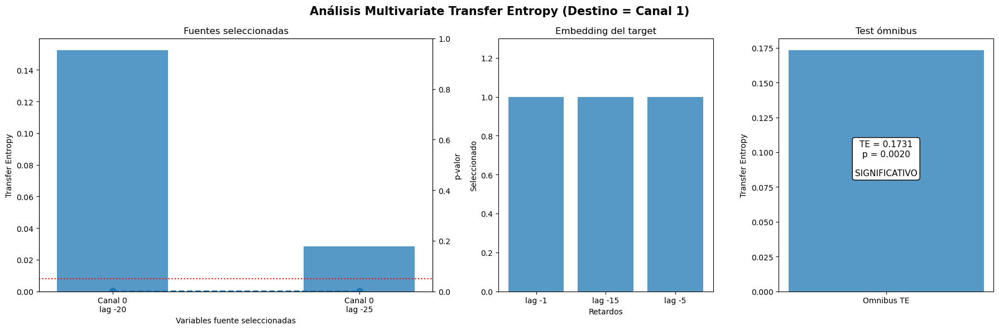

In [ ]:
target = 1
res4_loc = results4_local.get_single_target(target=target, fdr=False)

selected_sources = res4_loc["selected_vars_sources"]
selected_target = res4_loc["selected_vars_target"]

te_values = np.asarray(res4_loc["selected_sources_te"])
p_values = np.asarray(res4_loc["selected_sources_pval"])

omnibus_te = res4_loc["omnibus_te"]
omnibus_p = res4_loc["omnibus_pval"]
omnibus_sign = res4_loc["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Aparece un flujo en retardo $-5$ del TARGET que no está sucediendo en la estructura real del sistema.

---

---

Como último experimento, algo más complejo. Un sistema del tipo X --> Y --> Z.

Queremos comrpbar si IDTxl es capaz de detectar que X --> Z es espurio cuando metemos la variable Y como tercera variable a la herramienta.



El sistema que se va a estudiar el siguiente:
$$
\begin{cases} 
X_t = a X_{t-1} + \varepsilon_t^x \\ 
Y_t = b Y_{t-1} + c X_{t-\tau_1} + \varepsilon_t^y \\
Z_t = d Z_{t-1} + e Y_{t-\tau_2} + \varepsilon_t^z 
\end{cases}
$$

por ejemplo, $tau_1=10$ y $tau_2=15$ .


![VAR($\tau$)](imagenes/imagen6.png)

In [92]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.5, 0.5, 0.7, 0.5, 0.7
sig_x2, sig_y2, sig_z2 = 1.0, 1.0, 1.0
tau_uno = 10
tau_dos = 15

T = 2250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)
ez = np.random.normal(0, np.sqrt(sig_z2), T)

Z = np.zeros((T, 3))  # Z[:, 0] es X, Z[:, 1] es Y, Z[:, 2] es Z

for t in range(0, T):
    # Ecuación para X: Solo depende de su propio pasado inmediato
    Z[t, 0] = a * Z[t-1, 0] + ex[t]
    
    # Ecuación para Y: Depende de su propio pasado inmediato y de X con delay tau_uno
    Z[t, 1] = (b * Z[t-1, 1] + c * Z[t-tau_uno, 0] + ey[t])
    
    # Ecuación para Z: Depende de su propio pasado inmediato y de Y con delay tau_dos
    Z[t, 2] = (d * Z[t-1, 2] + e * Z[t-tau_dos, 1] + ez[t])

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y', 'Z'])
X = data['X'].values
Y = data['Y'].values
Z = data['Z'].values

X = X[250:]
Y = Y[250:]
Z = Z[250:]
X = X.astype(float)
Y = Y.astype(float)
Z = Z.astype(float)
data = np.vstack([X, Y, Z])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 3 processes, 2000 samples, 1 replications
overwriting existing data


Comenzamos comprobando qué es capaz de detectar cuando no añadimos la variable Y como condicionante:

In [93]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 50,             
    # mínimo retardo
    'min_lag_sources': 1, 
    # memoria del destino
    'max_lag_target': 10,           
    # número de permutaciones
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500, 
    'n_perm_max_seq': 500,     
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,  
    'alpha_omnibus': 0.05,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results5 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=2, sources=[0])


Target: 2 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10)]
testing candidate: (2, 1) maximum statistic, n_perm: 200
testing candidate: (2, 9) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(1)), (0, np.int64(2)), (0, np.int64(3)), (0, np.int64(4)), (0, np.int64(5)), (0, np.int64(6)), (0, np.int64(7)), (0, np.int64(8)), (0, np.int64(9)), (0, np.int64(10)), (0, np.int64(11)), (0, np.int64(12)), (0, np.int64(13)), (0, np.int64(14)), (0, np.int64(15)), (0, np.int64(16)), (0, np.int64(17)), (0, np.int64(18)), (0, np.int64(19)), (0, np.int64(20)), (0, np.int64(21)), (0, np.int64(22)), (0, np.int64(23)), (0, np.int64(24)), (0, np.int64(25)), (0, np.int64(26)), (0, np.int64(27)), (0, np.int64(28)), (0, np.int64(29)), (0, np.int64(30)), (0, np.int64(31)), (0, np.int64(32)), (

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 2

Variables del TARGET utilizadas como embedding:
   Canal 2  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 25   TE = 0.104304   p = 0.0020

Resumen Ómnibus
   TE total : 0.104312
   p-valor  : 0.0020
   Resultado: SIGNIFICATIVO


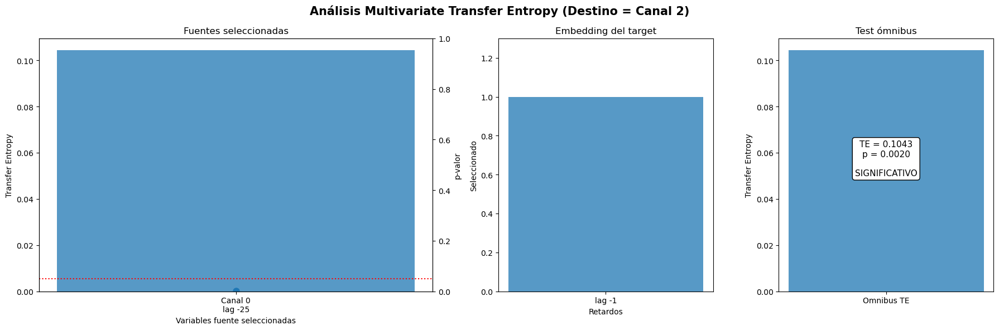

In [95]:
target = 2
res5 = results5.get_single_target(target=target, fdr=False)

selected_sources = res5["selected_vars_sources"]
selected_target = res5["selected_vars_target"]

te_values = np.asarray(res5["selected_sources_te"])
p_values = np.asarray(res5["selected_sources_pval"])

omnibus_te = res5["omnibus_te"]
omnibus_p = res5["omnibus_pval"]
omnibus_sign = res5["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Ahora añadimos la variable Y como serie condicionante. Con eso, se debería detectar que no hay transpaso de información de X --> Z.

In [96]:
settings_XZ_condY = {
    # Estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI',
    'max_lag_sources': 40,
    'min_lag_sources': 1,
    'max_lag_target': 5,
    # condicionantes
    'add_conditionals': [(1, 15)],
    'n_perm_max_stat': 200,
    'n_perm_min_stat': 200,
    'n_perm_omnibus': 500,
    'n_perm_max_seq': 500,
    'alpha_max_stat': 0.05,
    'alpha_min_stat': 0.05,
    'alpha_omnibus': 0.05,
    'permute_in_time': True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'verbose': True,
    'num_threads': 'USE_ALL'
}

network_analysis = MultivariateTE()
results_XZ_condY = network_analysis.analyse_single_target(settings=settings_XZ_condY, data=dataset, target=2, sources=[0])


Target: 2 - testing sources [0]
Adding the following variables to the conditioning set: [(1, 15)].

---------------------------- (1) include target candidates
candidate set: [(2, 4), (2, 1), (2, 5), (2, 2), (2, 3)]
testing candidate: (2, 1) maximum statistic, n_perm: 200
testing candidate: (2, 3) maximum statistic, n_perm: 200
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(10)), (0, np.int64(4)), (0, np.int64(1)), (0, np.int64(38)), (0, np.int64(35)), (0, np.int64(32)), (0, np.int64(26)), (0, np.int64(29)), (0, np.int64(23)), (0, np.int64(17)), (0, np.int64(20)), (0, np.int64(14)), (0, np.int64(11)), (0, np.int64(5)), (0, np.int64(8)), (0, np.int64(2)), (0, np.int64(39)), (0, np.int64(33)), (0, np.int64(36)), (0, np.int64(30)), (0, np.int64(24)), (0, np.int64(27)), (0, np.int64(21)), (0, np.int64(18)), (0, np.int64(12)), (0, np.int64(15)), (0, np.int64(9)), (0, np.int64(6)), (0, np.int64(3)), (0, np.int64(40)), (0, np.int64

El resultado es justamente el esperado. Cuando condicionamos por $Y_{t-15}$ el sistema detecta que no hay transpaso de información X --> Z.

La validación de la herramienta nos hace concluir que el funcionamiento es robusto

---

---

### Uso de datos surrogados

A continuación, la función `TE_surrogates`realiza un análisis completo de significancia en las dos direcciones:

* Dirección causal esperada: **Y → X**

* Dirección inversa: **X → Y**

In [35]:
def TE_surrogates(
    source,
    target,
    n_vecinos=4,
    max_steps=300,
    contexto_k=1,
    contexto_l=30,
    n_surrogates=10
):

    # =====================
    # TE REAL
    # =====================

    taus, TE_real, _ = find_optimal_tau_TE_JIDT(source, target, n_vecinos=n_vecinos, max_steps=max_steps, contexto_k=contexto_k, contexto_l=contexto_l, factor_bool=False, plot=False)

    # =====================
    # SURROGATES
    # =====================

    TE_surr_all=[]

    for i in tqdm(range(n_surrogates),desc="Surrogates"):

        source_surr = circular_surrogate(source)
        _, TE_surr, _ = find_optimal_tau_TE_JIDT(source_surr, target, n_vecinos=n_vecinos, max_steps=max_steps, contexto_k=contexto_k, contexto_l=contexto_l, factor_bool=False, plot=False)
        TE_surr_all.append(TE_surr)

    TE_surr_all=np.array(TE_surr_all)
    mean_surr=np.mean(TE_surr_all, axis=0)
    std_surr=np.std( TE_surr_all, axis=0)

    Z=(TE_real-mean_surr)/(std_surr+1e-12)

    return (taus, TE_real, mean_surr, std_surr, Z)

$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$

$\tau = 250$, `contexto_l=50`

In [36]:
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau_real = 250
T = 5250

np.random.seed(42)
ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) 

for t in range(0, T):
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau_real, 1] + ex[t]

X = Z[:, 0]
Y = Z[:, 1]

# Recorte inicial para remover transitorios genéricos
X = X[250:]
Y = Y[250:]


(taus,TE_YX,mean_YX,std_YX,Z_YX) = TE_surrogates(Y, X, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=50, n_surrogates=3)

(taus,TE_XY,mean_XY,std_XY,Z_XY) = TE_surrogates(X, Y, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=50, n_surrogates=3)

Surrogates: 100%|██████████| 3/3 [51:35<00:00, 1031.69s/it]


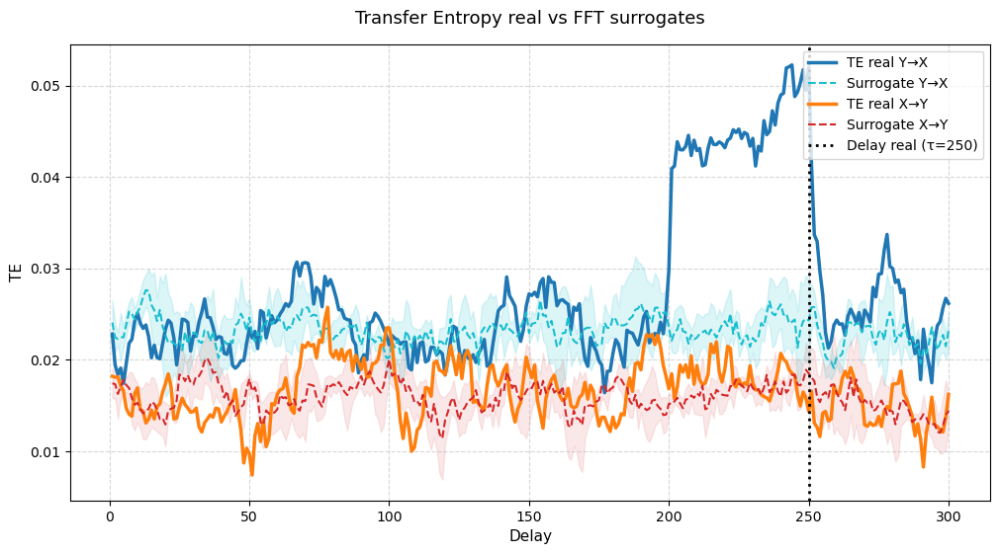

In [37]:
plt.figure(figsize=(12, 6))

# --- DIRECCIÓN Y → X (Gama de Azules/Teal) ---
plt.plot(taus, TE_YX, lw=2.5, color="#1f77b4", label="TE real Y→X")
plt.plot(taus, mean_YX, linestyle="--", lw=1.5, color="#17becf", label="Surrogate Y→X")
plt.fill_between(taus, mean_YX - std_YX, mean_YX + std_YX, color="#17becf", alpha=0.15)

# --- DIRECCIÓN X → Y (Gama de Naranjas/Rojos) ---
plt.plot(taus, TE_XY, lw=2.5, color="#ff7f0e", label="TE real X→Y")
plt.plot(taus, mean_XY, linestyle="--", lw=1.5, color="#d62728", label="Surrogate X→Y")
plt.fill_between(taus, mean_XY - std_XY, mean_XY + std_XY, color="#d62728", alpha=0.1)

# --- ELEMENTOS DE LA GRÁFICA ---
plt.axvline(tau, linestyle=":", color="black", lw=2, label=f"Delay real (τ={tau})")

plt.xlabel("Delay", fontsize=11)
plt.ylabel("TE", fontsize=11)
plt.title("Transfer Entropy real vs circular surrogates", fontsize=13, pad=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10, loc="upper right")
plt.show()

$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1}+ d Y_{t-10} + \varepsilon_t^y 
\end{cases}
$$

$\tau = 250$, `contexto_l=1`.

In [38]:
a, b, c, d = 0.5, 0.3, 0.4, 0.4
sig_x2, sig_y2 = 1.0, 1.0
tau_real = 250
T = 5250

np.random.seed(42)
ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    Z[t, 1] = c * Z[t-1, 1] + d * Z[t-10, 1] + ey[t]
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau_real, 1] + ex[t]

X = Z[:, 0]
Y = Z[:, 1]

# Recorte inicial para remover transitorios genéricos
X = X[250:]
Y = Y[250:]


(taus,TE_YX,mean_YX,std_YX,Z_YX) = TE_surrogates(Y, X, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, n_surrogates=3)

(taus,TE_XY,mean_XY,std_XY,Z_XY) = TE_surrogates(X, Y, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, n_surrogates=3)

Surrogates: 100%|██████████| 3/3 [01:18<00:00, 26.07s/it]


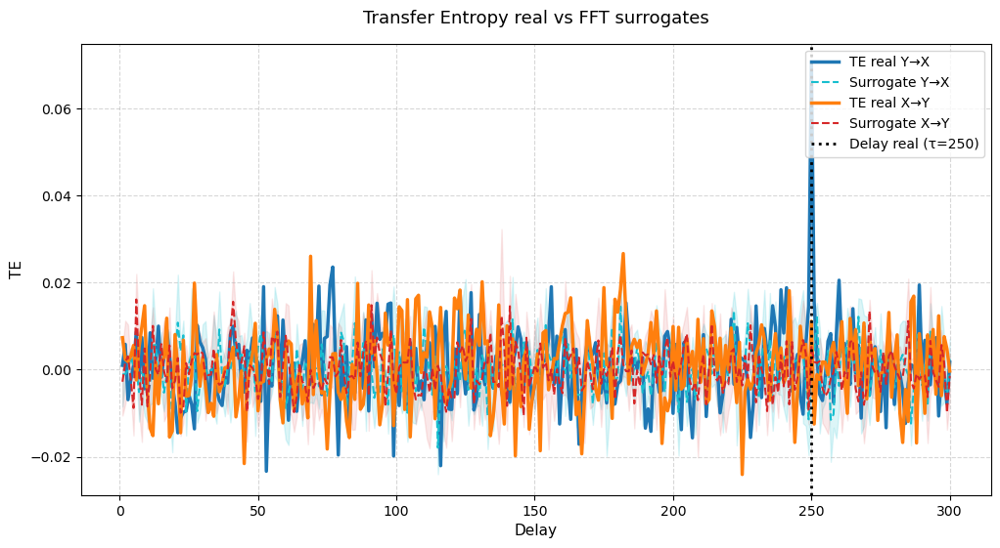

In [39]:
plt.figure(figsize=(12, 6))

# --- DIRECCIÓN Y → X (Gama de Azules/Teal) ---
plt.plot(taus, TE_YX, lw=2.5, color="#1f77b4", label="TE real Y→X")
plt.plot(taus, mean_YX, linestyle="--", lw=1.5, color="#17becf", label="Surrogate Y→X")
plt.fill_between(taus, mean_YX - std_YX, mean_YX + std_YX, color="#17becf", alpha=0.15)

# --- DIRECCIÓN X → Y (Gama de Naranjas/Rojos) ---
plt.plot(taus, TE_XY, lw=2.5, color="#ff7f0e", label="TE real X→Y")
plt.plot(taus, mean_XY, linestyle="--", lw=1.5, color="#d62728", label="Surrogate X→Y")
plt.fill_between(taus, mean_XY - std_XY, mean_XY + std_XY, color="#d62728", alpha=0.1)

# --- ELEMENTOS DE LA GRÁFICA ---
plt.axvline(tau, linestyle=":", color="black", lw=2, label=f"Delay real (τ={tau})")

plt.xlabel("Delay", fontsize=11)
plt.ylabel("TE", fontsize=11)
plt.title("Transfer Entropy real vs surrogates", fontsize=13, pad=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10, loc="upper right")
plt.show()

Definitivamente, mediante los datos surrogados somos capaces de explicar el ruido basal que mencionábamos al comienzo de este notebook. Ese ruido se encuentra al nivel de la curva que resulta de estimar la TE sobre los datos surrogados.

### Validación de método de surrogación

Es imprescindible para la utilidad que tiene trabajar con datos surrogados, que estos mantengan las propiedades estadísticas de las series y únicamente eliminen la parte del flujo de información estructural (lo cual es algo contradictorio ya de por si, pues se quiere eliminar únicamente precisamente la parte que se quiere calcular). El objetivo es destruir específicamente la estructura causal o de dependencia manteniendo intactas todas las propiedades dinámicas intrínsecas de cada serie por separado. Si se altera la distribución, el espectro de frecuencias o la auto-correlación no lineal propia de la señal, se romperá la hipótesis nula y el test dará falsos positivos (la hipotesis nula es que la distribución calculada con los datos surrogados es igual a la de los datos reales). 

Los modelos de generación de surrogados que se tratarán son los siguientes:

- Modelo de Phase Randomization (FFT): conserva la amplitud del espectro de Fourier (y por tanto la función de autocorrelación lineal) pero aleatoriza las fases --> no está en IDTxl.

Modelos de Permutación en tiempo (`permute_in_time=True`en IDTxl):

- Circular Shuffling (`circular`): Deplaza la serie circularmente, toda en bloque, sin cortes --> el más cuidadosos con la dinámica temporal.
- Block Shuffling (`block`): Divide la serie en bloques de tamaño fijo (`block_size`) y baraja aleatoriamente el orden de esos bloques --> conserva las dinámicas de corta escala.
- Local Shuffling (`local`): Permuta los valores de la serie únicamente dentro de una ventana o vecindad temporal restringida (`perm_range`) --> preserva las tendencias lentas y altera el ruido.
- Random Shuffling (`random`): Baraja de forma completamente aleatoria cada muestra temporal de la serie --> destruye completamente la estructura temporal.

A continuación se definen funciones que generan datos surrogados mendiante las 5 técnicas anteriores. En los modelos de Permutación en tiempo, el código está basado en la metodología interna de IDTxl aunque con algunas simplificaciones.

In [8]:
def fft_surrogate(x):
    Xf = np.fft.fft(x)
    amplitude = np.abs(Xf)
    random_phase = np.random.uniform(0,2*np.pi,len(x))
    X_surr = amplitude * np.exp(1j * random_phase)
    return np.real(np.fft.ifft(X_surr))


def circular_surrogate(x, min = 1, max = 1):
    """
    Desplaza la serie temporal circularmente en bloque un número aleatorio de pasos.
    """
    n = len(x)
    shift = np.random.randint(min, n - max) 
    return np.roll(x, shift)


def block_surrogate(x, block_size):
    """
    Selecciona bloques de tamaño fijo con inicios aleatorios para reconstruir la serie
    y añade micro-jitter para evitar empates en estimadores KSG.
    """
    n = len(x)
    x_surr = np.empty(n)
    
    # Rellenamos la nueva serie bloque a bloque
    for i in range(0, n, block_size):
        max_start_idx = n - block_size    # Asegurar que el bloque no se salga del final de la serie original
        if max_start_idx <= 0:
            raise ValueError("El 'block_size' no puede ser mayor que la longitud de la serie.")
            
        start_idx = np.random.randint(0, max_start_idx + 1)
        end_idx = start_idx + block_size
        
        if i + block_size > n:         # Si es el último bloque y sobrepasa n, se recorta lo que falte
            remaining = n - i
            x_surr[i:] = x[start_idx : start_idx + remaining]
        else:
            x_surr[i : i + block_size] = x[start_idx : end_idx]
            
    jitter = np.random.normal(0, 1e-10, size=n)      # en IDTxl se añade ruido infinitesimal (jitter) para romper empates analíticos
    return x_surr + jitter

def local_surrogate(x, perm_range):
    """
    Estrecha los intercambios estrictamente dentro de una ventana acotada por 'perm_range' y añade micro-jitter final.
    """
    n = len(x)
    indices = np.arange(n)
    
    step = max(1, perm_range // 2)      # recorrer la serie en pasos y barajar localmente
    for i in range(0, n, step):
        # Definimos los límites de la ventana local actual
        low = max(0, i - perm_range)
        high = min(n, i + perm_range + 1)
        
        np.random.shuffle(indices[low:high])     # Barajar los índices dentro de esta vecindad
        
    x_surr = x[indices]          # Reconstruir la serie usando los índices localmente permutados
    
    jitter = np.random.normal(0, 1e-10, size=n)
    return x_surr + jitter


def random_surrogate(x):
    """
    Baraja completamente al azar cada muestra temporal de la serie.
    """
    x_surr = x.copy()
    np.random.shuffle(x_surr)
    return x_surr

Para comprobar si el surrogate es suficientemente cuidadoso con la serie temporal, se pueden hacer diferentes comprobaciones como:

* **Distribución (con media y varianza)**

* **Autocorrelación lineal y espectro de potencia**

* **Autocorrelación no lineal --> Información Mutua de Retardo**

A continuación se define una función para cada comprobación anterior. La entrada de las funciones es una muestra de la serie real y una matriz con todos los surrogados calculados desde esa muestra original. La salida es una evidencia gráfica y/o numérica que permita decidir si los datos surrgoados mantienen la propiedad que se está evaluando en cada caso. 

**Distribución (con media y varianza)**

In [9]:
def distribucion_testKS(
    serie_original,
    surrogates,
    n_points=300,
    alpha=0.05,
    bandas="std",          # "std" o "percentil"
    plot=True
):
    """
    Compara la distribución de una serie original con un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like
        Serie temporal original.

    surrogates : ndarray (n_surrogates, N)
        Cada fila corresponde a un surrogate.

    n_points : int
        Número de puntos para estimar la KDE.

    alpha : float
        Nivel de significación para el test KS (se hace uno para cada surrogate).

    bandas : str
        "std"       -> media ± desviación típica.
        "percentil" -> intervalo 2.5%-97.5%.

    plot : bool
        Si True dibuja las densidades.

    Devuelve
    --------
    resultados : dict
        Diccionario con estadísticas y resultados del test KS.
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz (n_surrogates, N).")
    n_surrogates = surrogates.shape[0]

    # ==========================================================
    # Estadísticos básicos

    media_original = np.mean(serie_original)
    var_original = np.var(serie_original)
    medias_surrogates = np.mean(surrogates, axis=1)
    vars_surrogates = np.var(surrogates, axis=1)
    print("\n========== Estadísticos ==========")
    print(f"Media original              : {media_original:.6f}")
    print(f"Media de las medias surrogate: {np.mean(medias_surrogates):.6f}")
    print()
    print(f"Varianza original              : {var_original:.6f}")
    print(f"Media de las varianzas surrogate: {np.mean(vars_surrogates):.6f}")

    # ==========================================================
    # Estimación de densidades

    xmin = min(np.min(serie_original), np.min(surrogates))
    xmax = max(np.max(serie_original), np.max(surrogates))
    margen = 0.05 * (xmax - xmin)
    x = np.linspace(xmin - margen, xmax + margen, n_points)
    kde_original = gaussian_kde(serie_original)
    dens_original = kde_original(x)
    dens_surrogates = np.zeros((n_surrogates, n_points))

    for i in range(n_surrogates):
        kde = gaussian_kde(surrogates[i])
        dens_surrogates[i] = kde(x)
    media_dens = np.mean(dens_surrogates, axis=0)

    if bandas == "std":
        banda_inf = media_dens - np.std(dens_surrogates, axis=0)
        banda_sup = media_dens + np.std(dens_surrogates, axis=0)
    elif bandas == "percentil":
        banda_inf = np.percentile(dens_surrogates, 2.5, axis=0)
        banda_sup = np.percentile(dens_surrogates, 97.5, axis=0)

    # ==========================================================
    # Test KS

    estadisticos = []
    pvalues = []

    for s in surrogates:
        D, p = ks_2samp(serie_original, s)
        estadisticos.append(D)
        pvalues.append(p)

    estadisticos = np.array(estadisticos)
    pvalues = np.array(pvalues)
    rechazados = pvalues < alpha

    print("\n========== Test Kolmogorov-Smirnov ==========")
    print(f"Número de surrogates          : {n_surrogates}")
    print(f"Nivel de significación        : {alpha}")
    print(f"Rechazos de H0               : {np.sum(rechazados)}/{n_surrogates}")
    print(f"Porcentaje de rechazos       : {100*np.mean(rechazados):.2f}%")
    print(f"Estadístico D medio          : {np.mean(estadisticos):.5f}")
    print(f"p-valor medio                : {np.mean(pvalues):.5f}")

    # ==========================================================
    # Gráfica

    if plot:
        plt.figure(figsize=(8,5))
        plt.plot(x, dens_original, lw=2.5, label="Serie original")
        plt.plot(x, media_dens, lw=2, label="Media surrogates")
        plt.fill_between(x, banda_inf, banda_sup, alpha=0.3, label="Banda")
        plt.xlabel("Valor")
        plt.ylabel("Densidad")
        plt.title("Comparación de funciones de densidad")
        plt.legend()
        plt.tight_layout()
        plt.show()

    resultados = {
        "media_original": media_original,
        "var_original": var_original,
        "media_surrogates": np.mean(medias_surrogates),
        "var_surrogates": np.mean(vars_surrogates),
        "ks_D": estadisticos,
        "ks_pvalue": pvalues,
        "rechazados": rechazados,
        "porcentaje_rechazo": 100*np.mean(rechazados)
    }

    return resultados

In [57]:
a, b, c, d = 0.5, 0.3, 0.4, 0.4
sig_x2, sig_y2 = 1.0, 1.0
tau_real = 250
T = 5250

np.random.seed(42)
ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    Z[t, 1] = c * Z[t-1, 1] + d * Z[t-10, 1] + ey[t]
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau_real, 1] + ex[t]
    
X = Z[:, 0]
Y = Z[:, 1]

X = X[250:]
Y = Y[250:]


========== Estadísticos ==========
Media original              : -0.025981
Media de las medias surrogate: -0.025981

Varianza original              : 1.598589
Media de las varianzas surrogate: 1.598589

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 20
Nivel de significación        : 0.05
Rechazos de H0               : 0/20
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00020
p-valor medio                : 1.00000


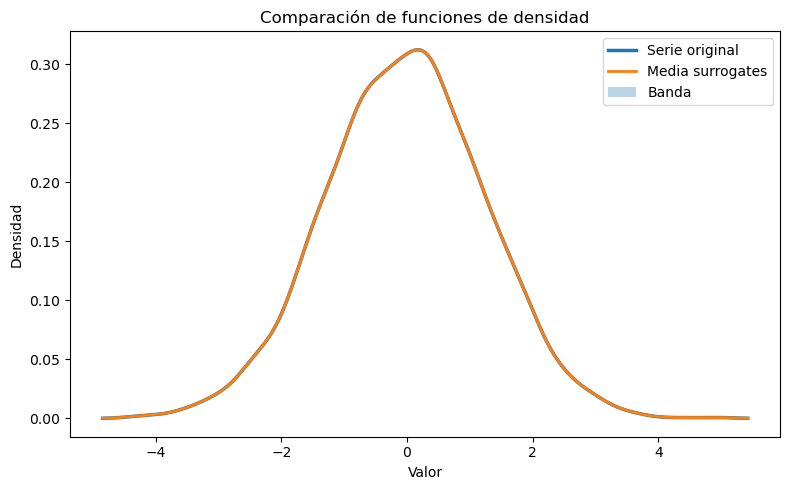

In [58]:
# Elegimos X como la serie original
serie_analizar = X 

n_surrogates = 20
perm_range_val = 50  # Tamaño de la ventana local de permutación
N = len(serie_analizar)

surrogates_matrix = np.zeros((n_surrogates, N))

for i in range(n_surrogates):
    surrogates_matrix[i, :] = local_surrogate(serie_analizar, perm_range=perm_range_val)

resultados = distribucion_testKS(serie_original=serie_analizar, surrogates=surrogates_matrix, n_points=300, alpha=0.05, bandas="std", plot=True)

**Autocorrelación lineal y espectro de potencia (PSD)**

In [10]:
def PSD_autocorrelacion(
    serie_original,
    surrogates,
    fs=1.0,
    max_lag=100,
    nperseg=None,
    bandas="std",
    plot=True,
):
    """
    Compara la PSD y la autocorrelación lineal entre una serie original y un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like

    surrogates : ndarray (n_surrogates, N)

    fs : float
        Frecuencia de muestreo para Welch.

    max_lag : int
        Máximo retardo para la autocorrelación.

    nperseg : int o None
        Parámetro de scipy.signal.welch.

    bandas : {"std","percentil"}

    plot : bool
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz.")
    n_surrogates = surrogates.shape[0]

    # ==========================================================
    # PSD

    f, psd_original = welch(serie_original, fs=fs, nperseg=nperseg)
    psd_surrogates = []

    for s in surrogates:
        _, psd = welch(s, fs=fs, nperseg=nperseg)
        psd_surrogates.append(psd)
    psd_surrogates = np.asarray(psd_surrogates)
    media_psd = np.mean(psd_surrogates, axis=0)

    if bandas == "std":
        inf_psd = media_psd - np.std(psd_surrogates, axis=0)
        sup_psd = media_psd + np.std(psd_surrogates, axis=0)
    else:
        inf_psd = np.percentile(psd_surrogates, 2.5, axis=0)
        sup_psd = np.percentile(psd_surrogates, 97.5, axis=0)

    # ==========================================================
    # AUTOCORRELACIÓN

    def autocorr(x, max_lag):     #autocorrelación normalizada
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode="full")
        ac = ac[ac.size // 2:]
        ac = ac / ac[0]
        return ac[: max_lag + 1]

    ac_original = autocorr(serie_original, max_lag)
    ac_surrogates = np.array([autocorr(s, max_lag)for s in surrogates])
    media_ac = np.mean(ac_surrogates, axis=0)
    if bandas == "std":
        inf_ac = media_ac - np.std(ac_surrogates, axis=0)
        sup_ac = media_ac + np.std(ac_surrogates, axis=0)
    else:
        inf_ac = np.percentile(ac_surrogates, 2.5, axis=0)
        sup_ac = np.percentile(ac_surrogates, 97.5, axis=0)

    # ==========================================================
    # MÉTRICAS

    error_psd = np.mean(np.abs(psd_original - media_psd) / np.maximum(psd_original, 1e-12))
    error_ac = np.mean(np.abs(ac_original - media_ac))

    print("\n========== PSD ==========")
    print(f"Error relativo medio PSD: {100*error_psd:.3f} %")
    print("\n========== Autocorrelación ==========")
    print(f"Error absoluto medio: {error_ac:.6f}")

    # ==========================================================
    # FIGURAS

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13,5))
        ax[0].plot(f, psd_original, lw=2.5, label="Original")
        ax[0].plot(f, media_psd, lw=2, label="Media surrogates")
        ax[0].fill_between(f, inf_psd, sup_psd, alpha=0.3, label="Banda")
        ax[0].set_xlabel("Frecuencia")
        ax[0].set_ylabel("PSD")
        ax[0].set_title("Densidad espectral de potencia")
        ax[0].legend()
        lags = np.arange(max_lag + 1)
        ax[1].plot(lags, ac_original, lw=2.5, label="Original")
        ax[1].plot(lags, media_ac, lw=2, label="Media surrogates")
        ax[1].fill_between(lags, inf_ac, sup_ac, alpha=0.3, label="Banda")
        ax[1].set_xlabel("Retardo")
        ax[1].set_ylabel("Autocorrelación")
        ax[1].set_title("Autocorrelación lineal")
        ax[1].legend()
        plt.tight_layout()
        plt.show()

    return {
        "frecuencias": f,
        "psd_original": psd_original,
        "psd_media": media_psd,
        "psd_surrogates": psd_surrogates,
        "autocorrelacion_original": ac_original,
        "autocorrelacion_media": media_ac,
        "autocorrelacion_surrogates": ac_surrogates,
        "error_psd": error_psd,
        "error_autocorrelacion": error_ac,
    }


========== PSD ==========
Error relativo medio PSD: 50.301 %

========== Autocorrelación ==========
Error absoluto medio: 0.003960


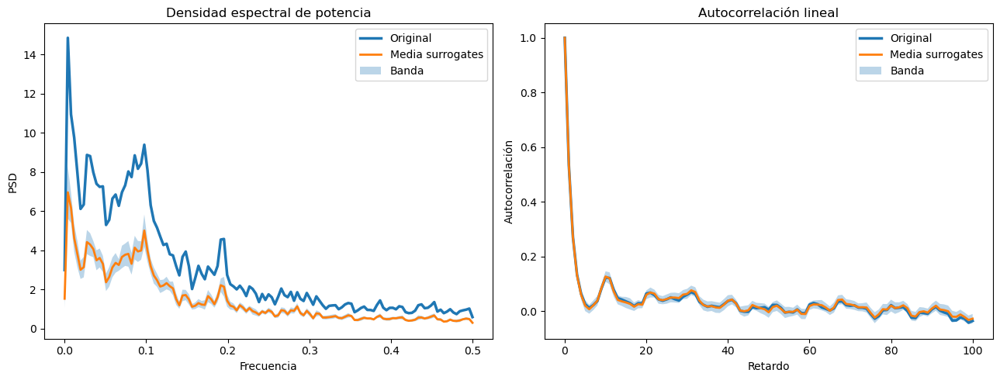

In [62]:
# Elegimos X como la serie original
serie_analizar = X 

n_surrogates = 20
N = len(serie_analizar)

surrogates_matrix = np.zeros((n_surrogates, N))

for i in range(n_surrogates):
    surrogates_matrix[i, :] = fft_surrogate(serie_analizar)

resultados = PSD_autocorrelacion(serie_original=serie_analizar, surrogates=surrogates_matrix, fs=1.0, max_lag=100, nperseg=None, bandas="std", plot=True)

**Autocorrelación no lineal --> Información Mutua de Retardo**

Se usa el estimador KSG de JIDT para estimar la Información Mutua (en vez de `mutual_info_regression`). Como en estos estudios estoy usando JIDT e IDTxl, es más coherente seguir con la misma metodología de estimación.

In [37]:
MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()
miCalc.initialise()

In [11]:
def dMI(
    serie_original,
    surrogates,
    max_lag=100,
    n_neighbors=5,
    random_state=0,
    bandas="std",
    plot=True,
):
    """
    Compara la Información Mutua de Retardo (TDMI) entre una serie original y un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like

    surrogates : ndarray (n_surrogates, N)

    max_lag : int

    n_neighbors : int
        Número de vecinos para el estimador kNN.

    random_state : int

    bandas : {"std", "percentil"}

    plot : bool
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz.")

    def tdmi(x):
        mi = np.zeros(max_lag)
        miCalc = MIClass()
        miCalc.setProperty("k", str(n_neighbors))
        for tau in range(1, max_lag + 1):
            X = x[:-tau]
            Y = x[tau:]
            miCalc.initialise()
            miCalc.setObservations(X.astype(np.float64), Y.astype(np.float64))
            mi[tau - 1] = miCalc.computeAverageLocalOfObservations()
        return mi

    # Serie original
    mi_original = tdmi(serie_original)

    # Surrogates
    mi_surrogates = np.array([tdmi(s) for s in surrogates])
    media_mi = np.mean(mi_surrogates, axis=0)
    if bandas == "std":
        inf = media_mi - np.std(mi_surrogates, axis=0)
        sup = media_mi + np.std(mi_surrogates, axis=0)
    elif bandas == "percentil":
        inf = np.percentile(mi_surrogates, 2.5, axis=0)
        sup = np.percentile(mi_surrogates, 97.5, axis=0)

    # ==========================================================
    # Error medio

    error = np.mean(np.abs(mi_original - media_mi))
    print("\n========== Información Mutua de Retardo ==========")
    print(f"Error absoluto medio : {error:.6f}")
    dentro = np.logical_and(mi_original >= inf, mi_original <= sup)
    porcentaje = 100 * np.mean(dentro)
    print(f"Retardos dentro de la banda : {porcentaje:.2f}%")

    # ==========================================================
    # Figura

    if plot:
        lags = np.arange(1, max_lag + 1)
        plt.figure(figsize=(8,5))
        plt.plot(lags, mi_original, lw=2.5, label="Serie original")
        plt.plot(lags, media_mi, lw=2, label="Media surrogates")
        plt.fill_between(lags, inf, sup, alpha=0.3, label="Banda")
        plt.xlabel("Retardo")
        plt.ylabel("Información Mutua")
        plt.title("Información Mutua de Retardo")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "mi_original": mi_original,
        "mi_media": media_mi,
        "mi_surrogates": mi_surrogates,
        "error": error,
        "porcentaje_dentro": porcentaje,
        "banda_inferior": inf,
        "banda_superior": sup,
    }


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.006990
Retardos dentro de la banda : 62.00%


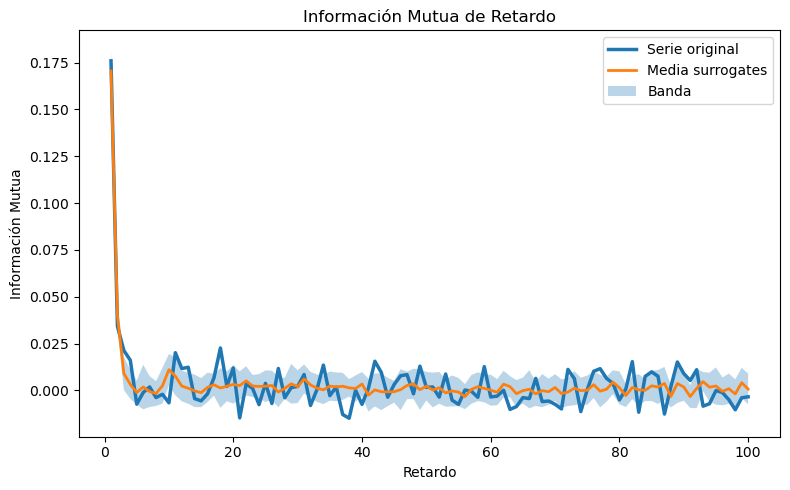

In [71]:
# Elegimos X como la serie original
serie_analizar = X 

n_surrogates = 20
N = len(serie_analizar)

surrogates_matrix = np.zeros((n_surrogates, N))

for i in range(n_surrogates):
    surrogates_matrix[i, :] = fft_surrogate(serie_analizar)

resultados = dMI(serie_original=serie_analizar, surrogates=surrogates_matrix, max_lag=100, n_neighbors=5, random_state=0, bandas="std", plot=True)

Usando las tres medidas anteriores, validamos los 5 modelos para generar surrogados que se comentaron anteriormente. La siguiente función `validacion_surrogado`, espera como entrada un modelo para generar datos surrogados y una serie original, y devuelve los resultados de los tres modelos de comparación anteriores (función de densidad con test K-S, Autocorrelación lineal y espectro de potencia (PSD) y TDMI).

In [12]:
def validacion_surrogado(
    surrogate_function,
    serie_original,
    n_surrogates=100,
    **kwargs
):
    """
    Genera un conjunto de surrogates a partir de una serie original y ejecuta las tres pruebas de validación.

    Parámetros
    ----------
    surrogate_function : callable
        Función que genera un surrogate a partir de una serie.

    serie_original : ndarray

    n_surrogates : int
        Número de surrogates a generar.

    **kwargs
        Parámetros adicionales que necesite surrogate_function
        (por ejemplo block_size, min, max...).

    Devuelve
    --------
    resultados : dict
        Diccionario con los resultados de las tres validaciones.
    """

    serie_original = np.asarray(serie_original)

    surrogates_matrix = np.array([surrogate_function(serie_original, **kwargs) for _ in range(n_surrogates)])


    # Validación de la distribución
    resultados_distribucion = distribucion_testKS(serie_original=serie_original, surrogates=surrogates_matrix, n_points=300, alpha=0.05, bandas="std", plot=True)

    # Validación de la PSD y autocorrelación
    resultados_psd = PSD_autocorrelacion(serie_original=serie_original, surrogates=surrogates_matrix, fs=1.0, max_lag=100, nperseg=None, bandas="std", plot=True)

    # Validación mediante información mutua de retardo
    resultados_dmi = dMI(serie_original=serie_original, surrogates=surrogates_matrix, max_lag=100, n_neighbors=5, random_state=0, bandas="std", plot=True)

    return {
        "surrogates": surrogates_matrix,
        "distribucion": resultados_distribucion,
        "PSD_autocorrelacion": resultados_psd,
        "dMI": resultados_dmi,
    }

### Comprobaciones con un autorregresivo básico (sobre la fuente Y):
$$
\begin{cases} 
X_t = a X_{t-1}+ b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$

por ejemplo $\tau = 10$.

![VAR($\tau$)](imagenes/imagen1.png)

In [40]:
# Definición de parámetros teóricos
a, b, c= 0.4, 0.3, 0.8
sig_x2, sig_y2 = 1.0, 1.0
tau = 10

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

serie_original = Y[250:]
X = Y[250:]

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : -0.092708
Media de las medias surrogate: 0.001742

Varianza original              : 2.852171
Media de las varianzas surrogate: 1.422119

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.11000
p-valor medio                : 0.00000


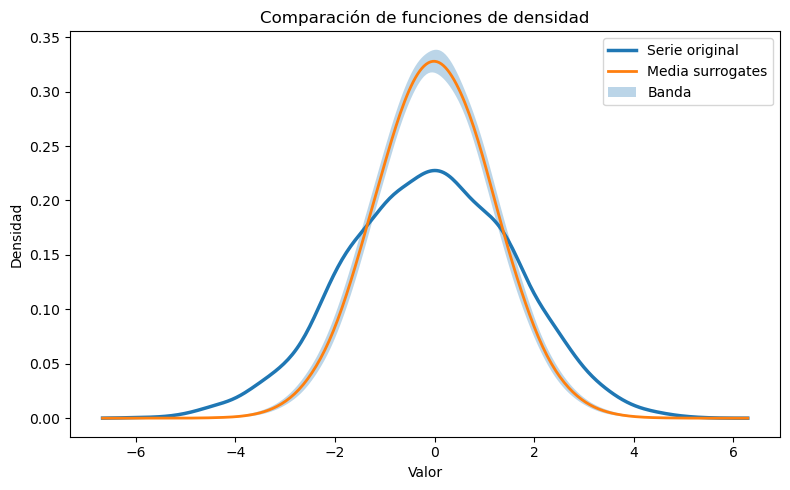


========== PSD ==========
Error relativo medio PSD: 50.169 %

========== Autocorrelación ==========
Error absoluto medio: 0.003875


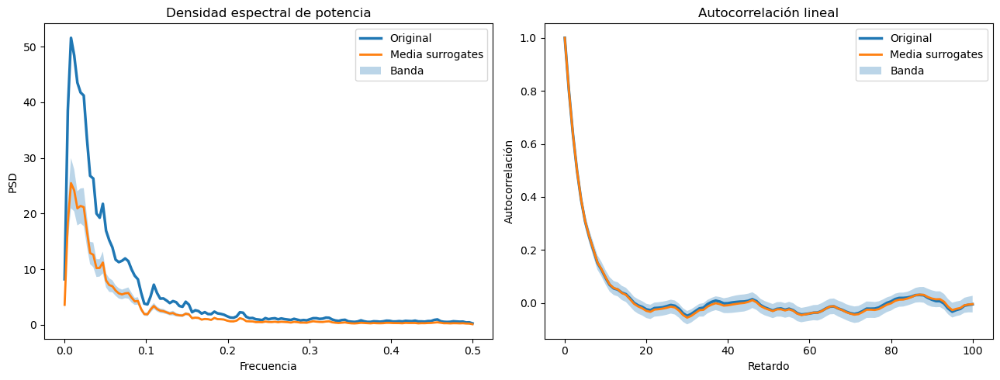


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.006283
Retardos dentro de la banda : 73.00%


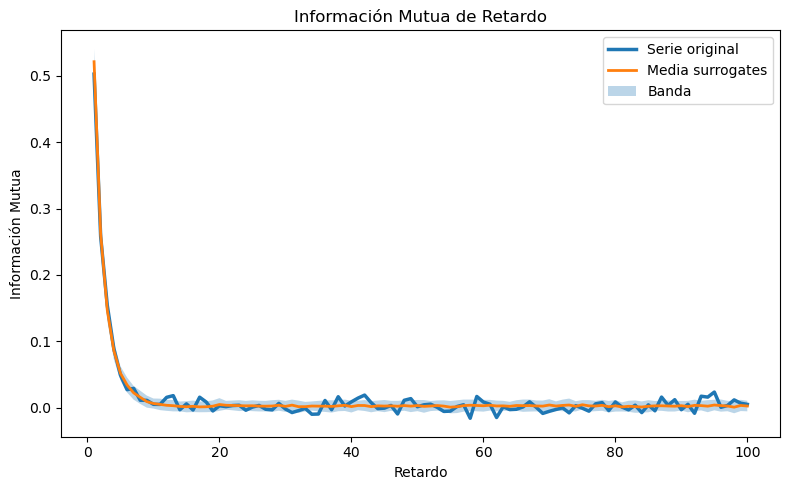

In [41]:
res_fft = validacion_surrogado(fft_surrogate, serie_original, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : -0.092708
Media de las medias surrogate: -0.092708

Varianza original              : 2.852171
Media de las varianzas surrogate: 2.852171

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


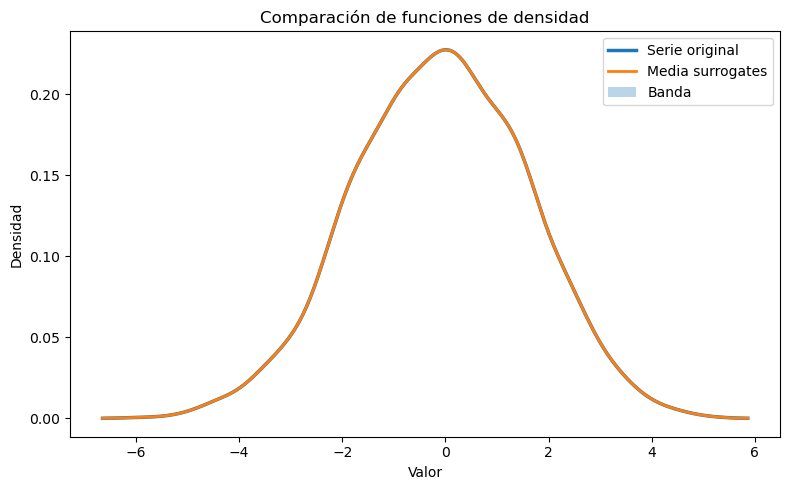


========== PSD ==========
Error relativo medio PSD: 4.060 %

========== Autocorrelación ==========
Error absoluto medio: 0.001915


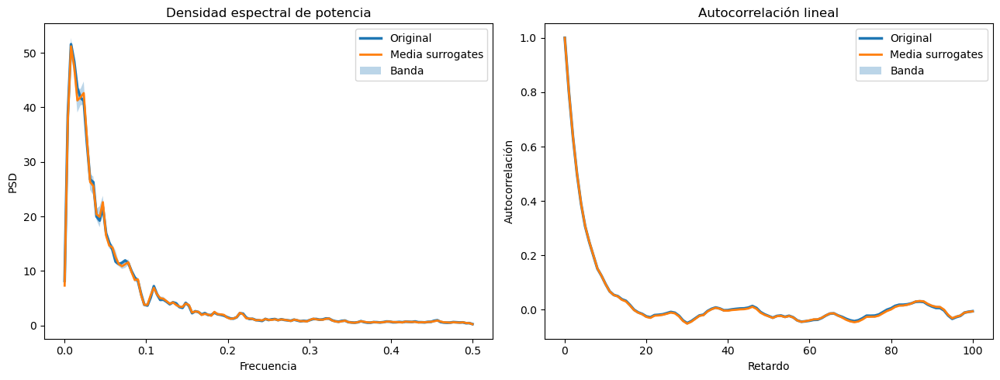


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.001092
Retardos dentro de la banda : 69.00%


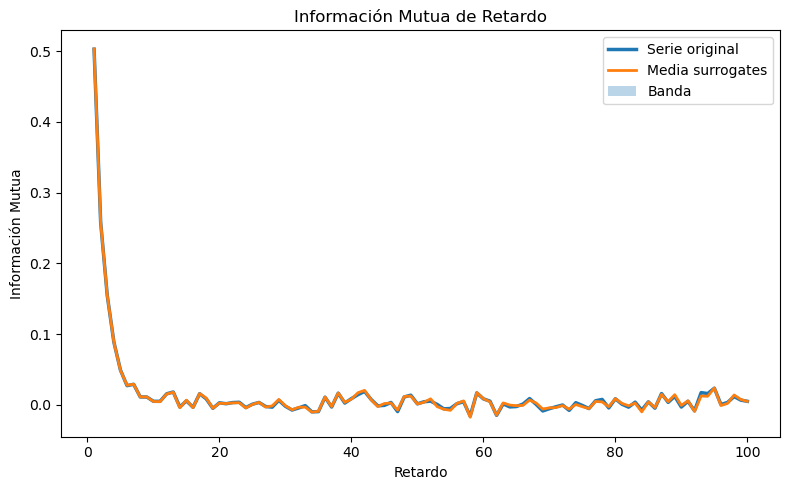

In [42]:
res_circular = validacion_surrogado(circular_surrogate, serie_original, n_surrogates=100, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : -0.092708
Media de las medias surrogate: -0.095232

Varianza original              : 2.852171
Media de las varianzas surrogate: 2.821542

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 20/100
Porcentaje de rechazos       : 20.00%
Estadístico D medio          : 0.01948
p-valor medio                : 0.44421


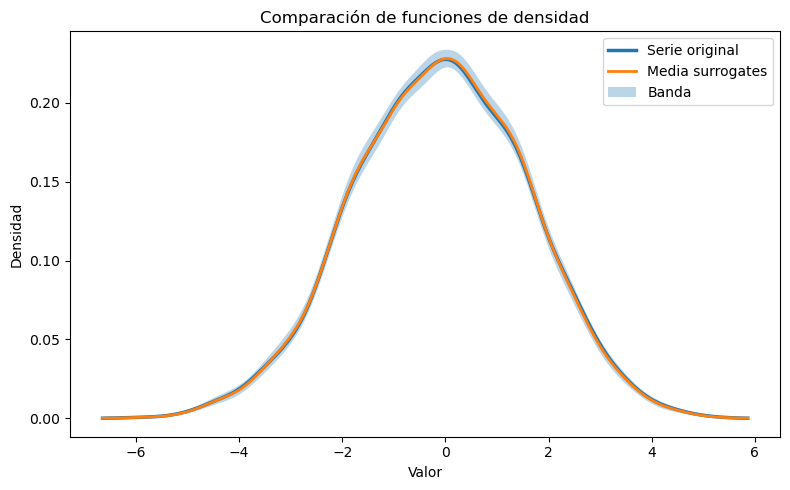


========== PSD ==========
Error relativo medio PSD: 13.778 %

========== Autocorrelación ==========
Error absoluto medio: 0.018139


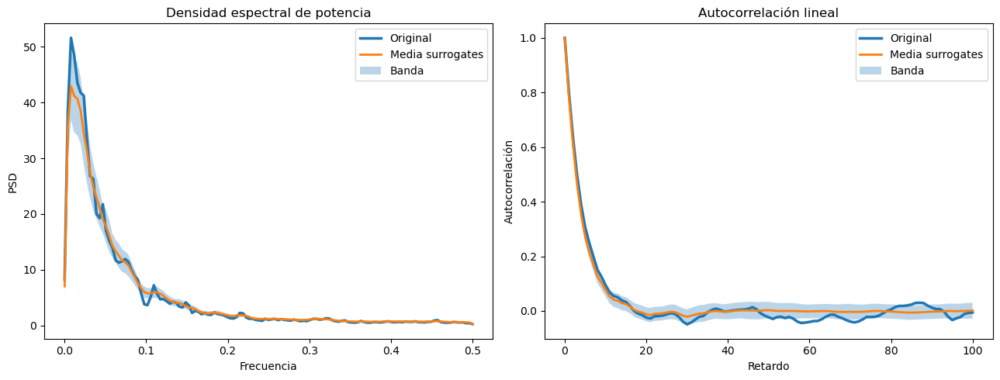


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.045940
Retardos dentro de la banda : 45.00%


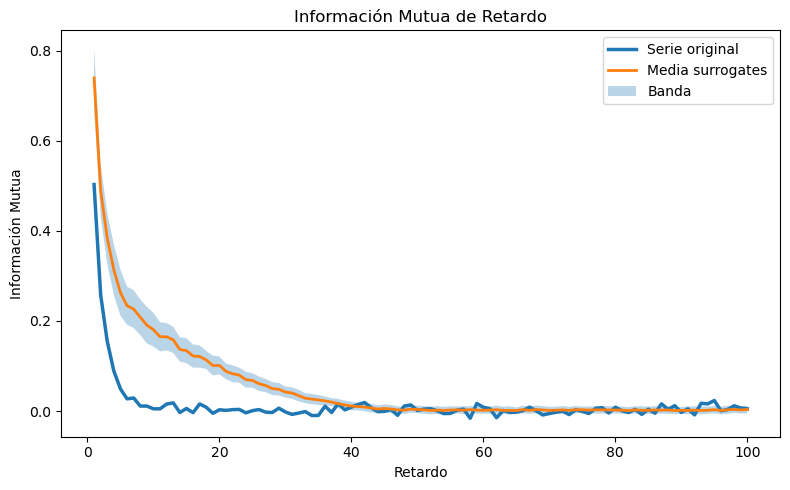

In [43]:
res_block = validacion_surrogado(block_surrogate, serie_original, n_surrogates=100, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : -0.092708
Media de las medias surrogate: -0.092708

Varianza original              : 2.852171
Media de las varianzas surrogate: 2.852171

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00020
p-valor medio                : 1.00000


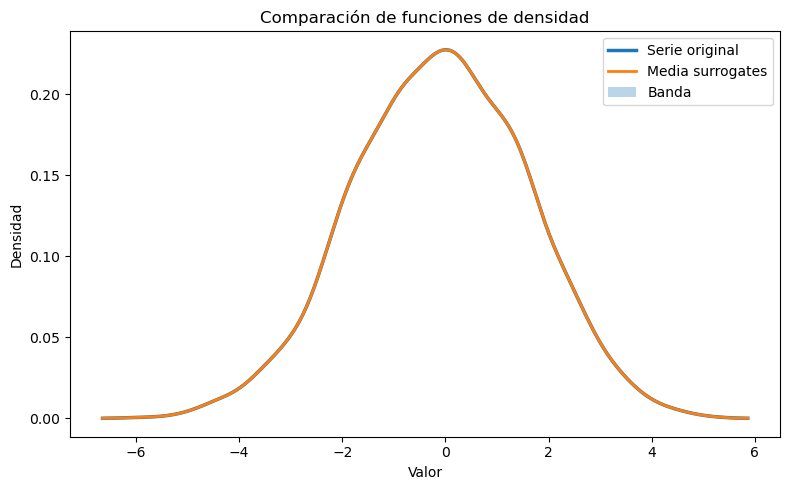


========== PSD ==========
Error relativo medio PSD: 395.878 %

========== Autocorrelación ==========
Error absoluto medio: 0.057154


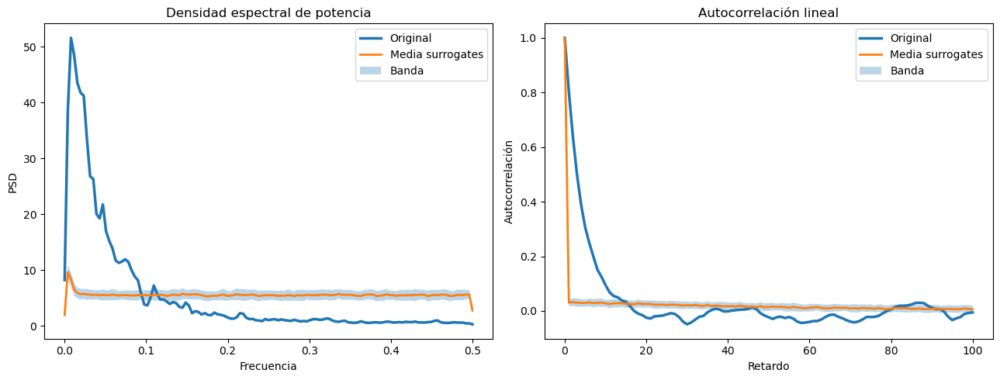


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.017279
Retardos dentro de la banda : 65.00%


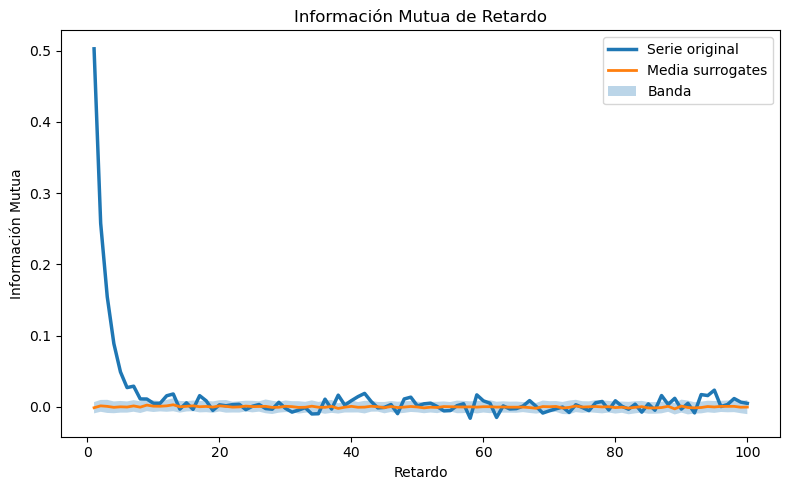

In [44]:
res_local = validacion_surrogado(local_surrogate, serie_original, n_surrogates=100, perm_range=50)

Random Shuffling (`random`)


========== Estadísticos ==========
Media original              : -0.092708
Media de las medias surrogate: -0.092708

Varianza original              : 2.852171
Media de las varianzas surrogate: 2.852171

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


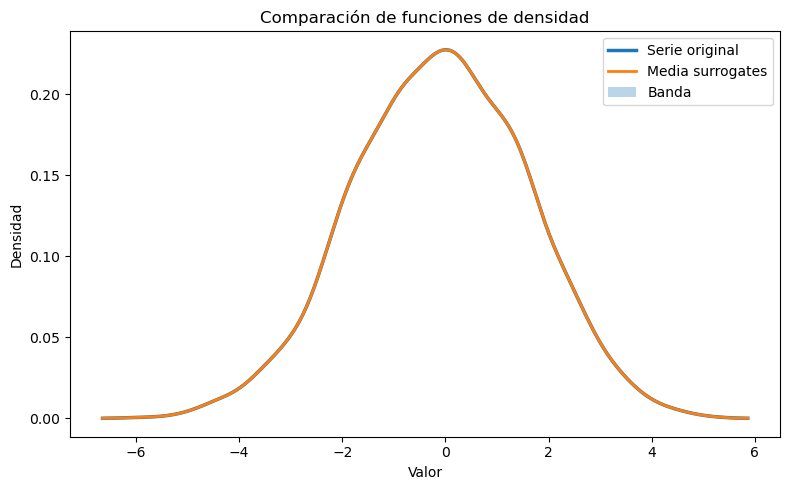


========== PSD ==========
Error relativo medio PSD: 413.582 %

========== Autocorrelación ==========
Error absoluto medio: 0.053240


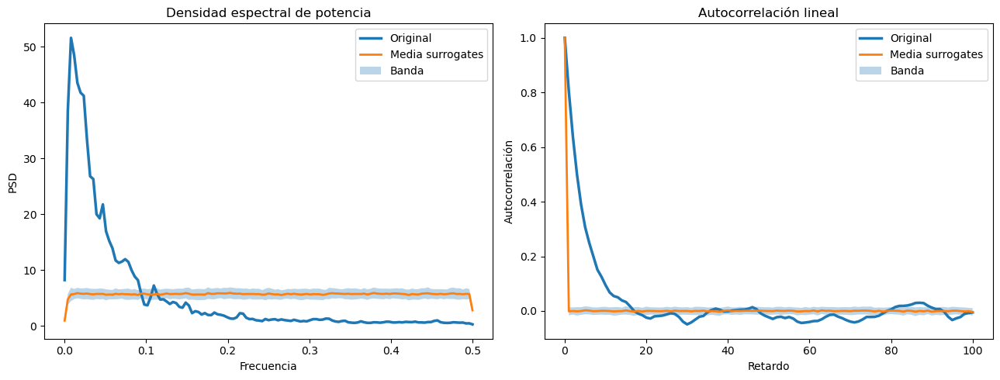


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.017327
Retardos dentro de la banda : 63.00%


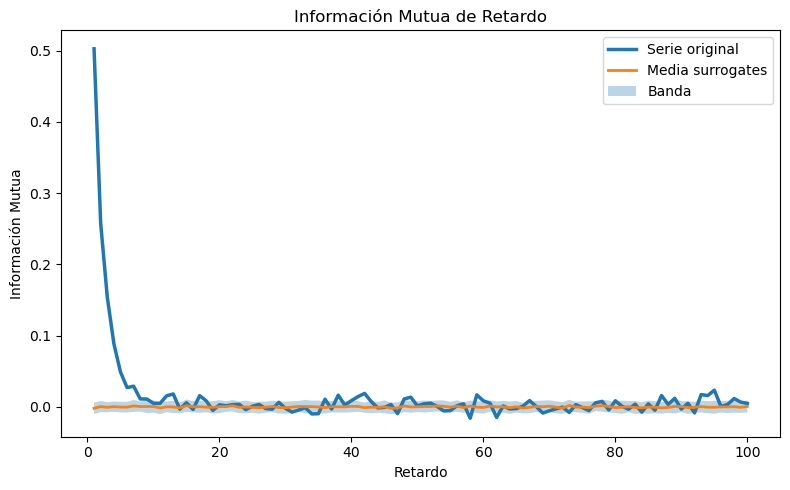

In [45]:
res_random = validacion_surrogado(random_surrogate, serie_original, n_surrogates=100)

### Comprobaciones con un autorregresivo con varios padres causales (sobre el destino X):
$$
\begin{cases} 
X_t = a X_{t-1}+ d X_{t-15} + b Y_{t-\tau_1} + e Y_{t-\tau_2} + \varepsilon_t^x \\ 
Y_t = c Y_{t-10} + \varepsilon_t^y 
\end{cases}
$$

por ejemplo, $tau_1=20$ y $tau_2=25$ .

![VAR($\tau$)](imagenes/imagen5.png)


In [78]:
# Definición de parámetros teóricos
a, b, c, d, e = 0.4, 0.3, 0.8, 0.4, 0.3
sig_x2, sig_y2 = 1.0, 1.0
tau_uno = 20
tau_dos = 25

T = 5250

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(0, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-10, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + d * Z[t-15, 0] + b * Z[t-tau_uno, 1] + e * Z[t-tau_dos, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

serie_original = X[250:]
Y = Y[250:]

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : -0.373578
Media de las medias surrogate: -0.010039

Varianza original              : 3.331444
Media de las varianzas surrogate: 1.651847

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.15468
p-valor medio                : 0.00000


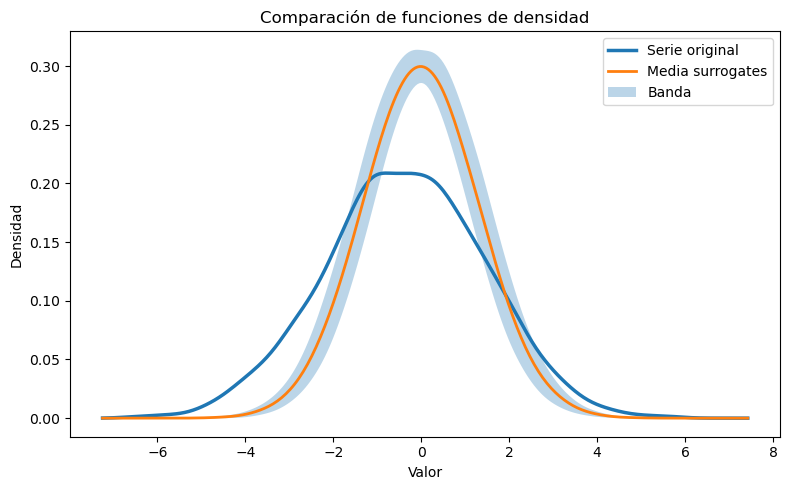


========== PSD ==========
Error relativo medio PSD: 49.156 %

========== Autocorrelación ==========
Error absoluto medio: 0.008198


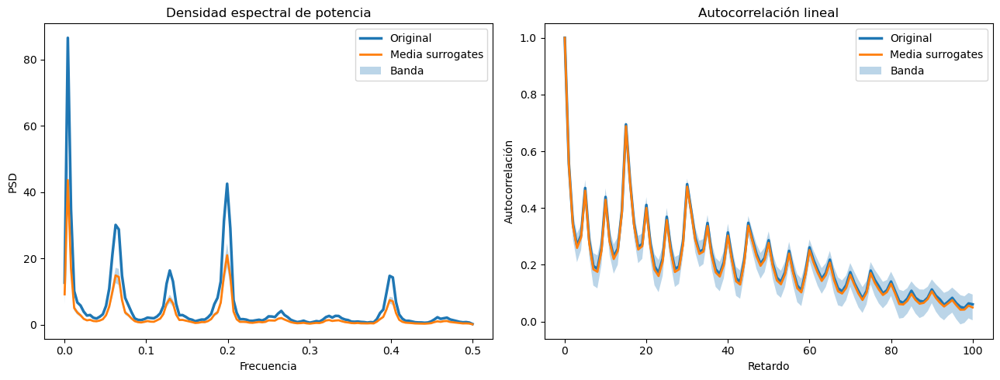


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.007042
Retardos dentro de la banda : 83.00%


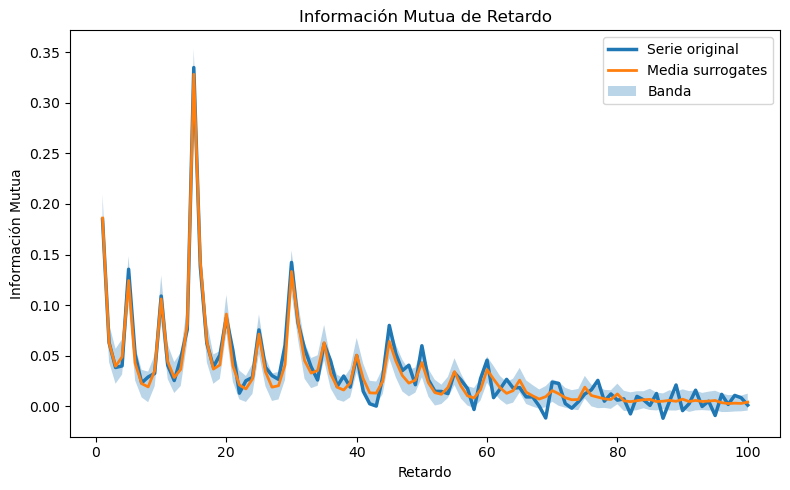

In [79]:
res_fft = validacion_surrogado(fft_surrogate, serie_original, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : -0.373578
Media de las medias surrogate: -0.373578

Varianza original              : 3.331444
Media de las varianzas surrogate: 3.331444

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


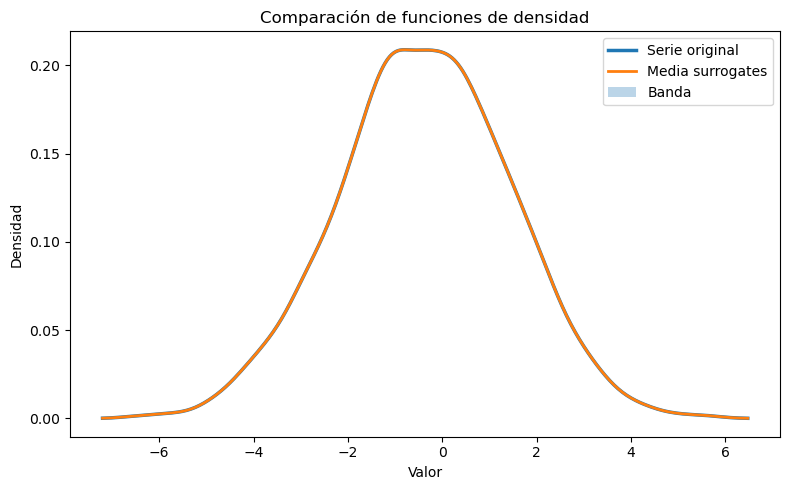


========== PSD ==========
Error relativo medio PSD: 5.035 %

========== Autocorrelación ==========
Error absoluto medio: 0.001949


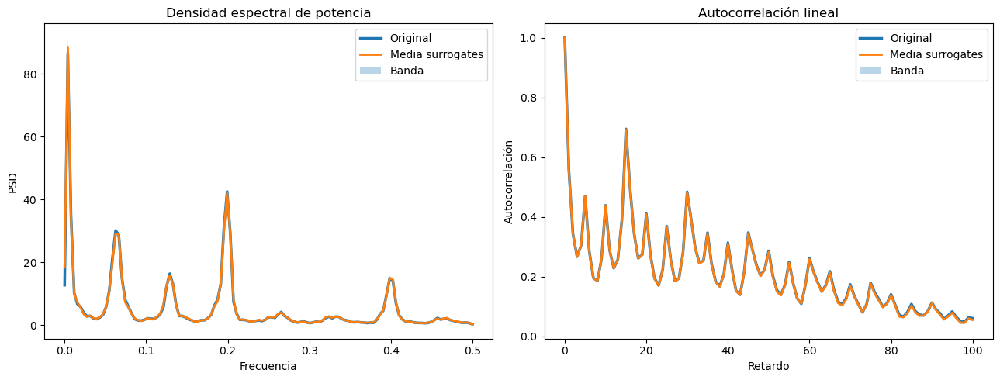


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.001128
Retardos dentro de la banda : 64.00%


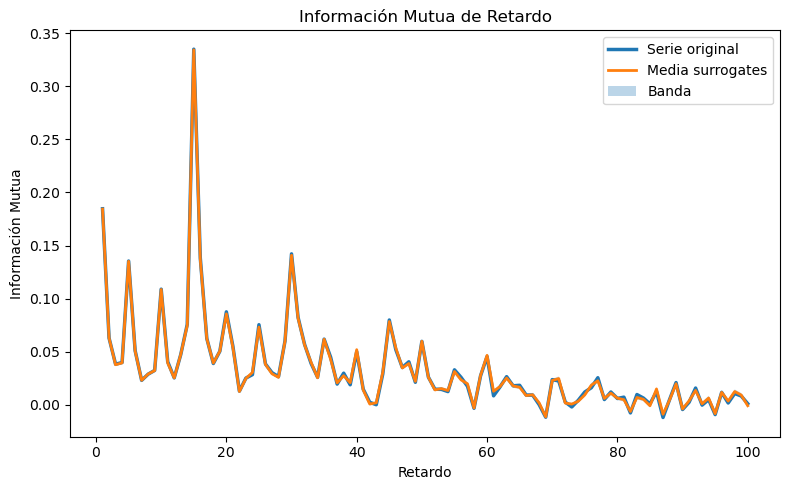

In [80]:
res_circular = validacion_surrogado(circular_surrogate, serie_original, n_surrogates=100, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : -0.373578
Media de las medias surrogate: -0.396228

Varianza original              : 3.331444
Media de las varianzas surrogate: 3.312494

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 40/100
Porcentaje de rechazos       : 40.00%
Estadístico D medio          : 0.02673
p-valor medio                : 0.28821


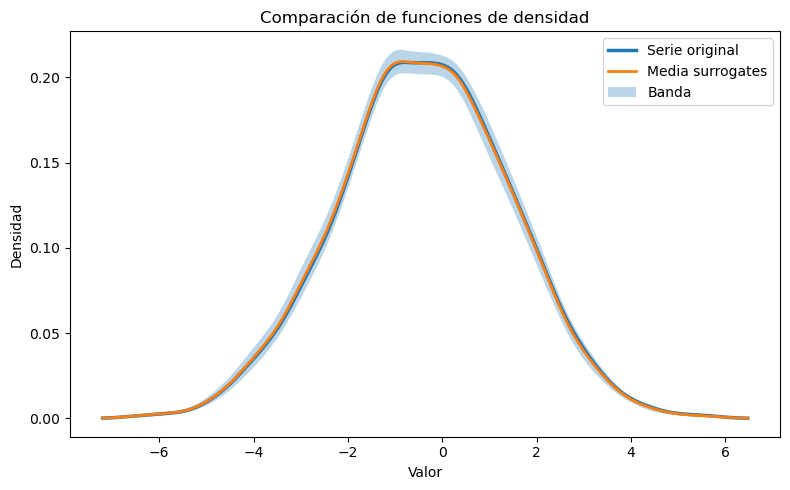


========== PSD ==========
Error relativo medio PSD: 55.082 %

========== Autocorrelación ==========
Error absoluto medio: 0.129449


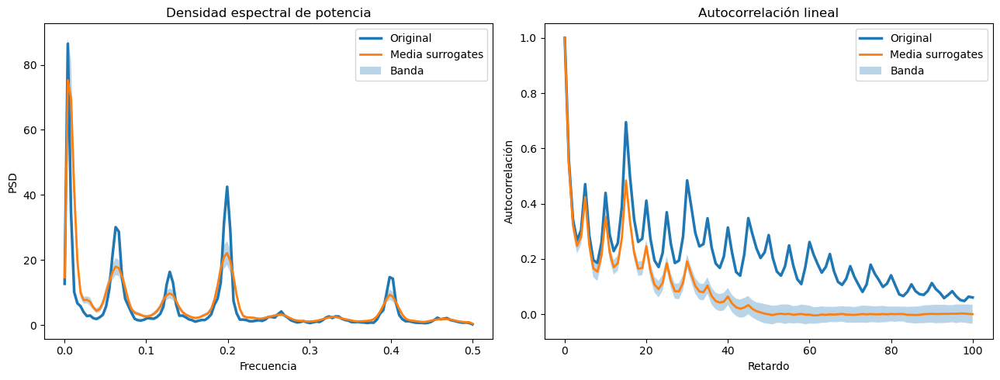


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.044848
Retardos dentro de la banda : 29.00%


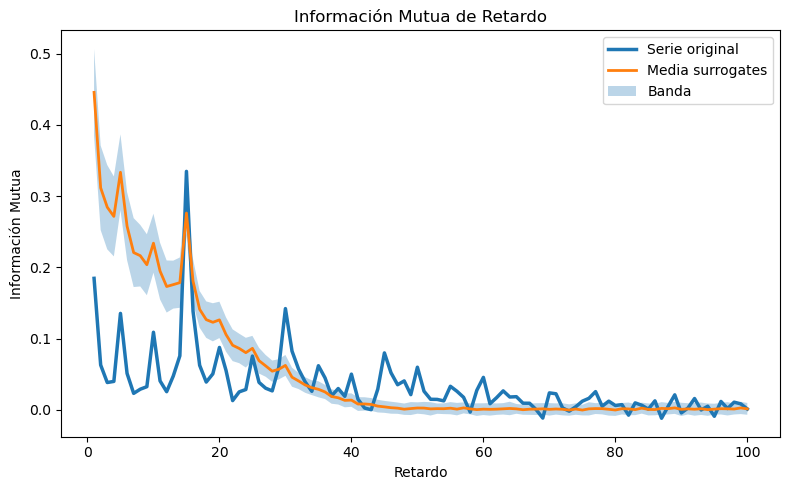

In [81]:
res_block = validacion_surrogado(block_surrogate, serie_original, n_surrogates=100, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : -0.373578
Media de las medias surrogate: -0.373578

Varianza original              : 3.331444
Media de las varianzas surrogate: 3.331444

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00020
p-valor medio                : 1.00000


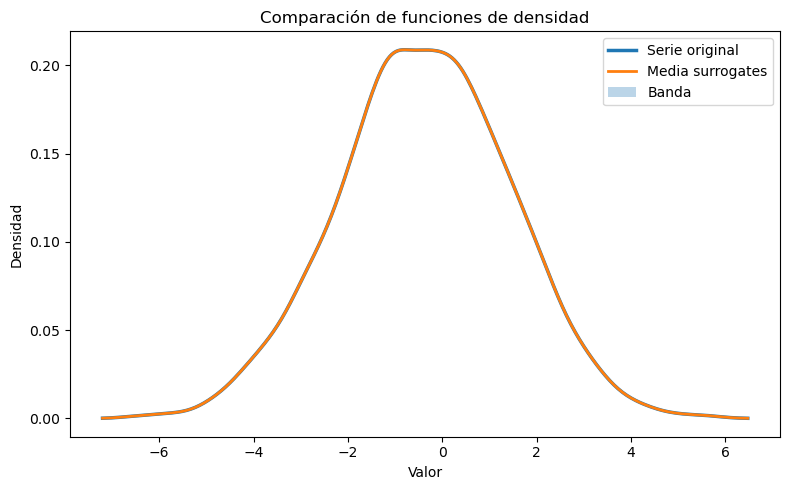


========== PSD ==========
Error relativo medio PSD: 261.919 %

========== Autocorrelación ==========
Error absoluto medio: 0.081869


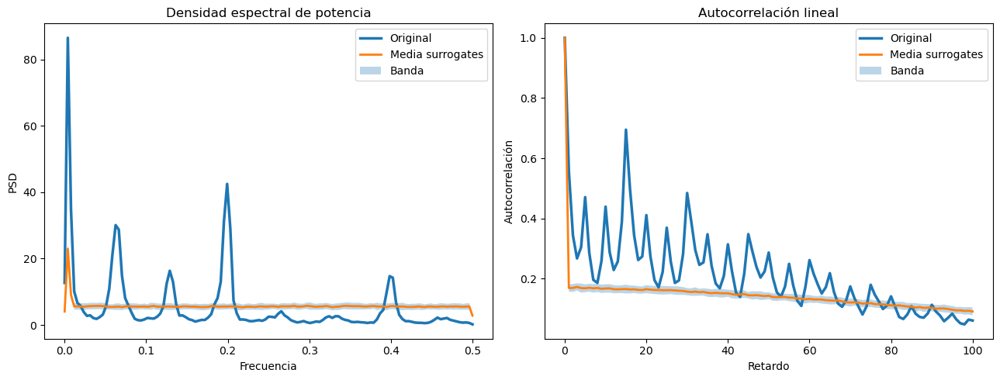


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.026736
Retardos dentro de la banda : 35.00%


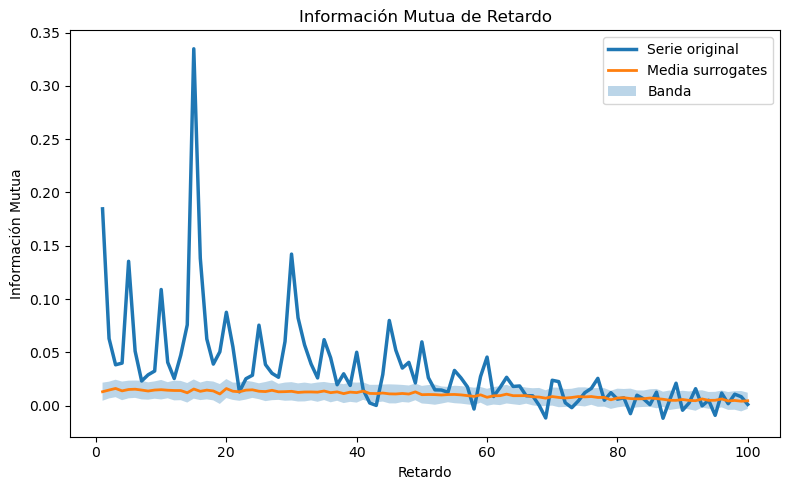

In [82]:
res_local = validacion_surrogado(local_surrogate, serie_original, n_surrogates=100, perm_range=50)

Random Shuffling (`random`)


========== Estadísticos ==========
Media original              : -0.373578
Media de las medias surrogate: -0.373578

Varianza original              : 3.331444
Media de las varianzas surrogate: 3.331444

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


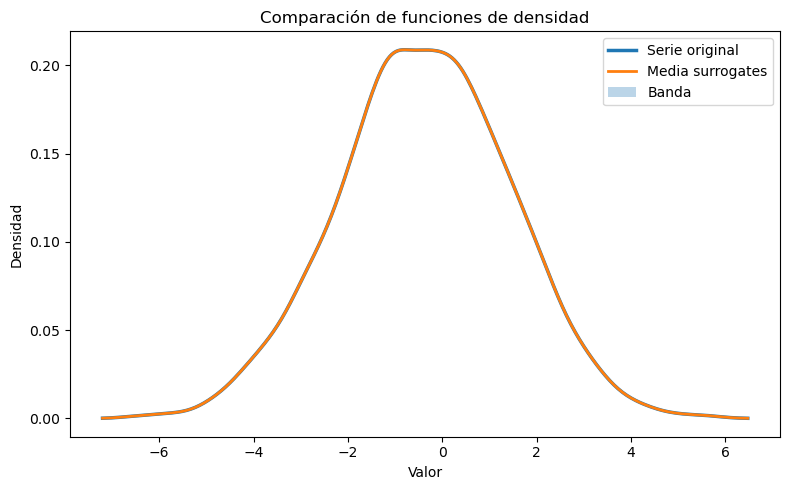


========== PSD ==========
Error relativo medio PSD: 326.513 %

========== Autocorrelación ==========
Error absoluto medio: 0.205104


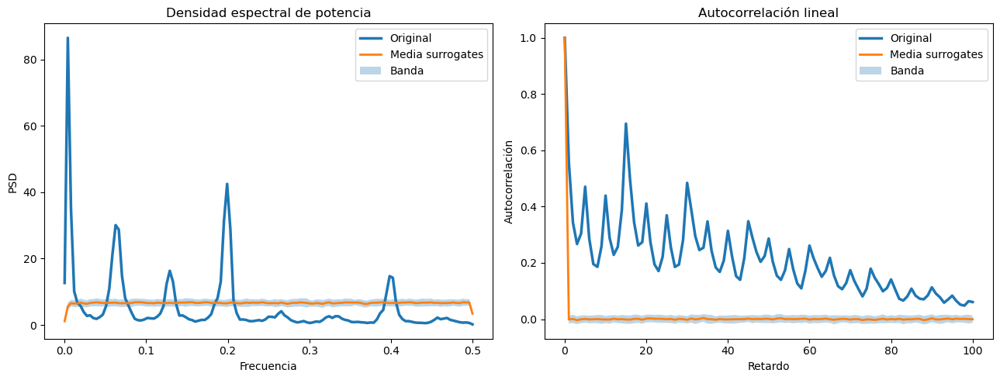


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.034936
Retardos dentro de la banda : 21.00%


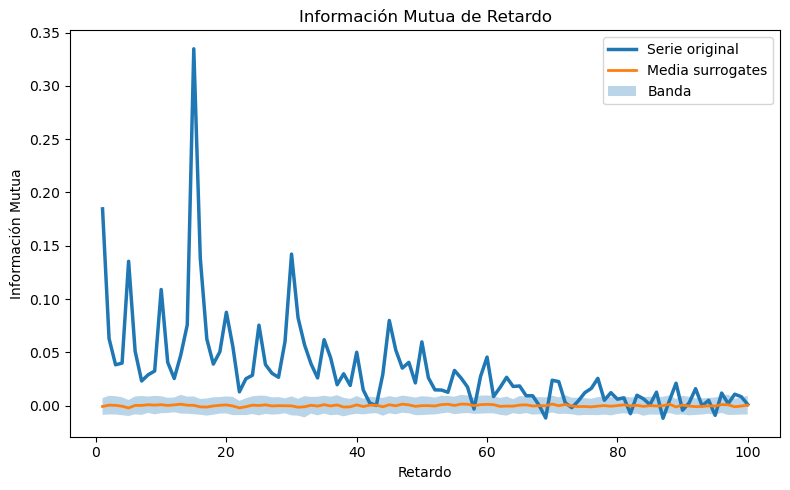

In [83]:
res_random = validacion_surrogado(random_surrogate, serie_original, n_surrogates=100)

---

---

### Comprobaciones con un modelo de neuronas HH (sobre la fuente V1):

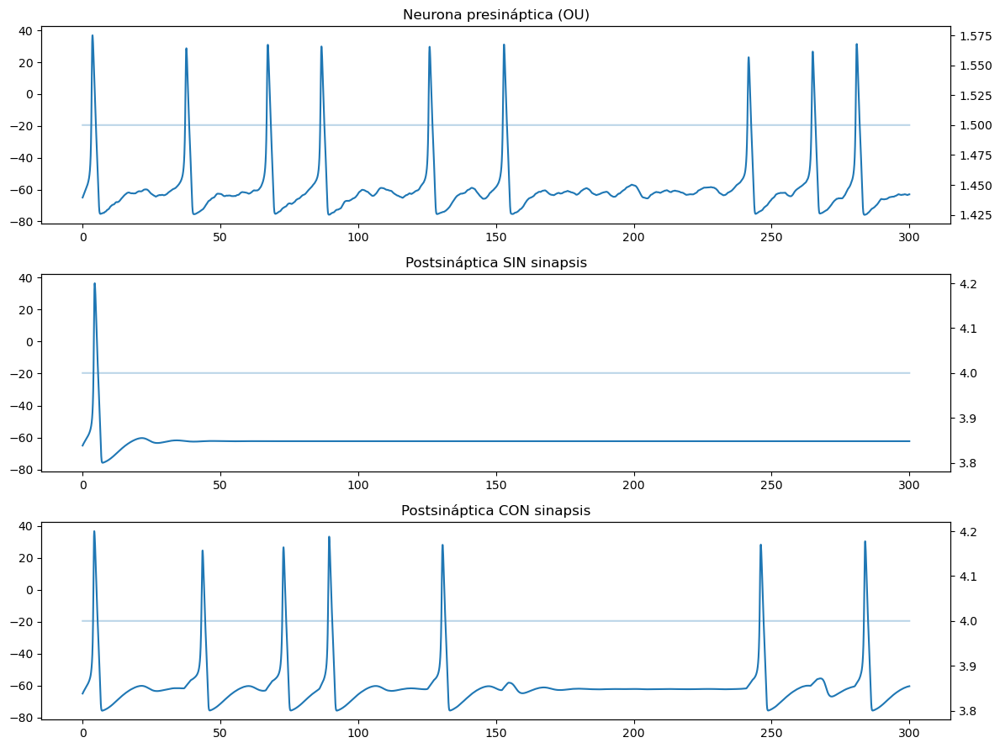

In [14]:
g_syn = 2.5
tau = 0.0

# (activación de la neurona 1 con sinapsis del entorno)
V1, V2 = mn.hh_multirate(T=300, theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=1.5, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=True)

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : -60.876329
Media de las medias surrogate: -5.829773

Varianza original              : 179.390052
Media de las varianzas surrogate: 88.428424

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.82615
p-valor medio                : 0.00000


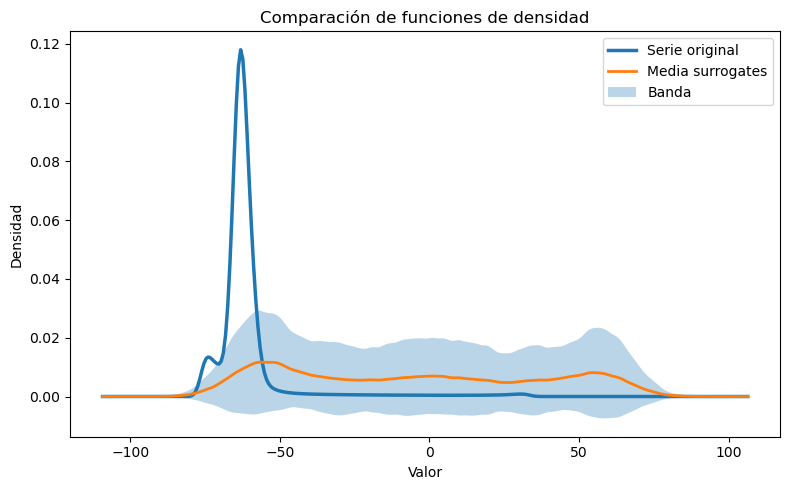


========== PSD ==========
Error relativo medio PSD: 95464.874 %

========== Autocorrelación ==========
Error absoluto medio: 0.002531


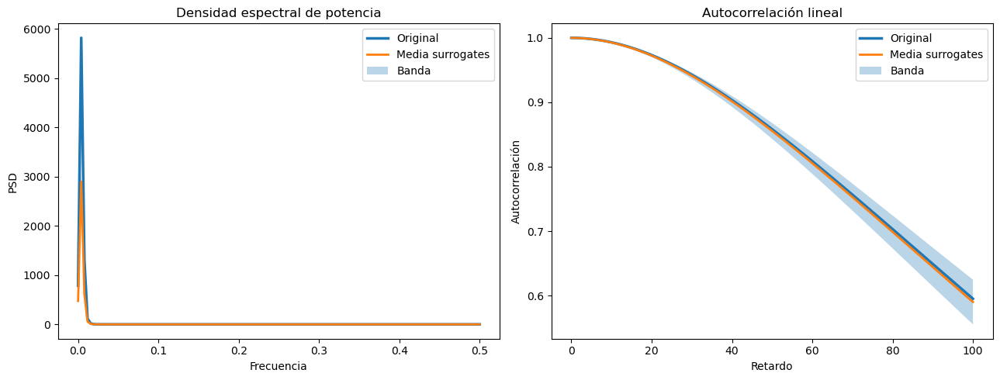


========== Información Mutua de Retardo ==========
Error absoluto medio : 1.559013
Retardos dentro de la banda : 0.00%


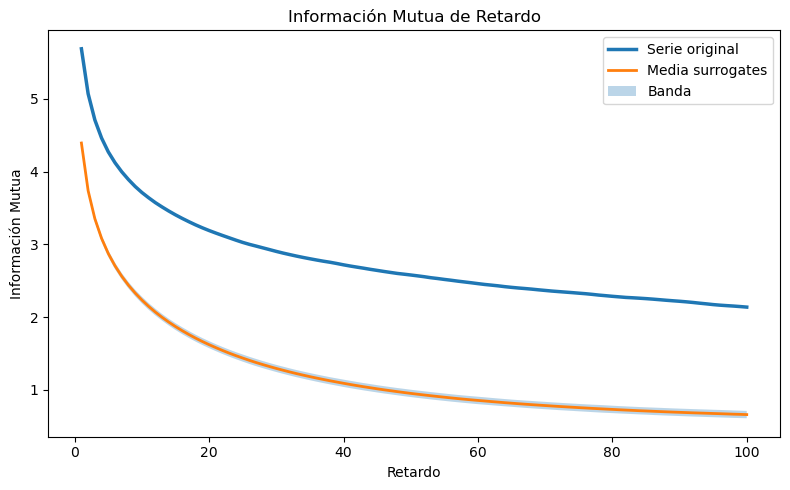

In [15]:
res_fft = validacion_surrogado(fft_surrogate, serie_original, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : -60.876329
Media de las medias surrogate: -60.876329

Varianza original              : 179.390052
Media de las varianzas surrogate: 179.390052

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


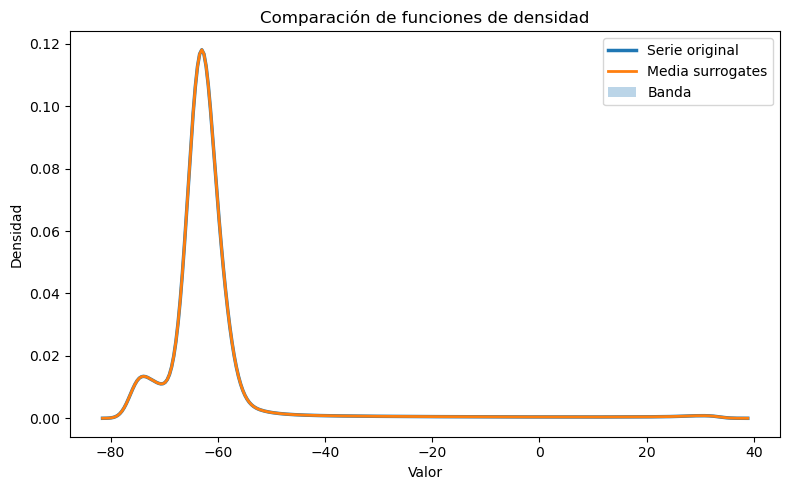


========== PSD ==========
Error relativo medio PSD: 194429.739 %

========== Autocorrelación ==========
Error absoluto medio: 0.001032


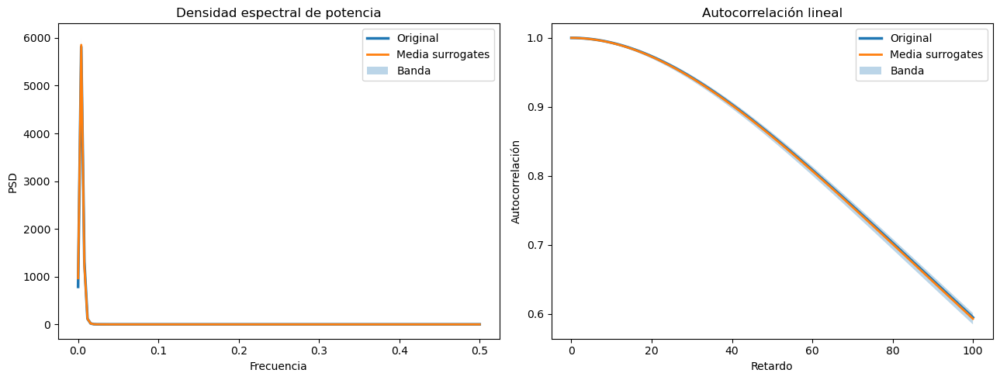


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.005057
Retardos dentro de la banda : 0.00%


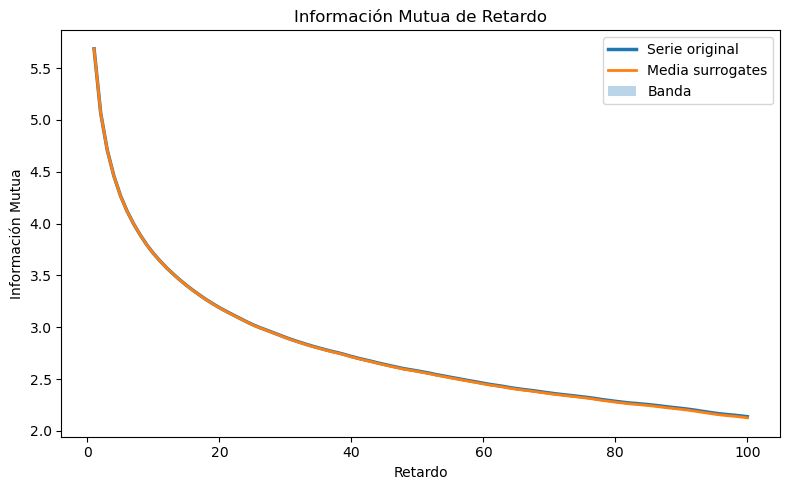

In [16]:
res_circular = validacion_surrogado(circular_surrogate, serie_original, n_surrogates=100, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : -60.876329
Media de las medias surrogate: -60.929909

Varianza original              : 179.390052
Media de las varianzas surrogate: 175.363133

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.02662
p-valor medio                : 0.00002


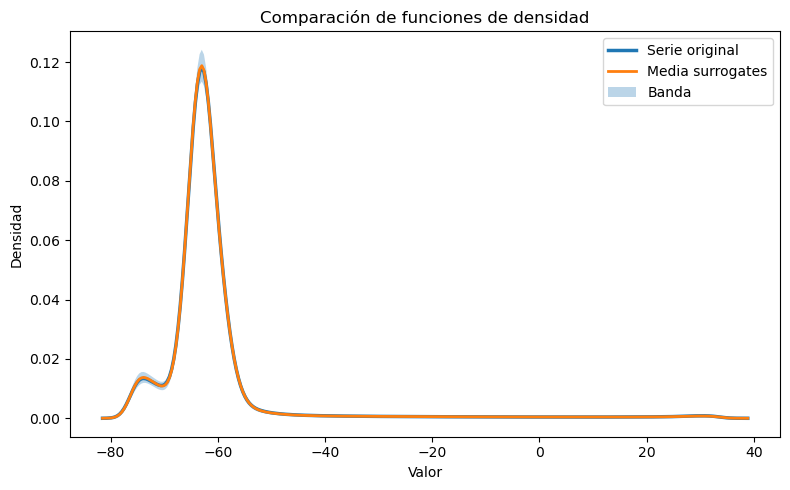


========== PSD ==========
Error relativo medio PSD: 432138579.335 %

========== Autocorrelación ==========
Error absoluto medio: 0.595092


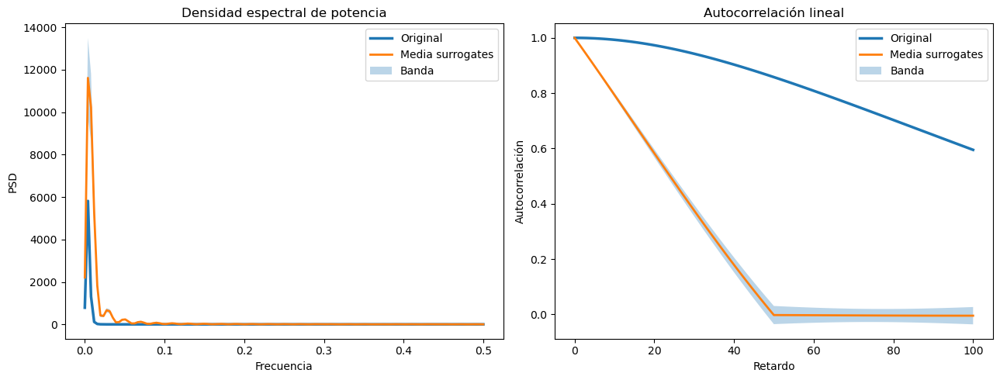


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.943923
Retardos dentro de la banda : 1.00%


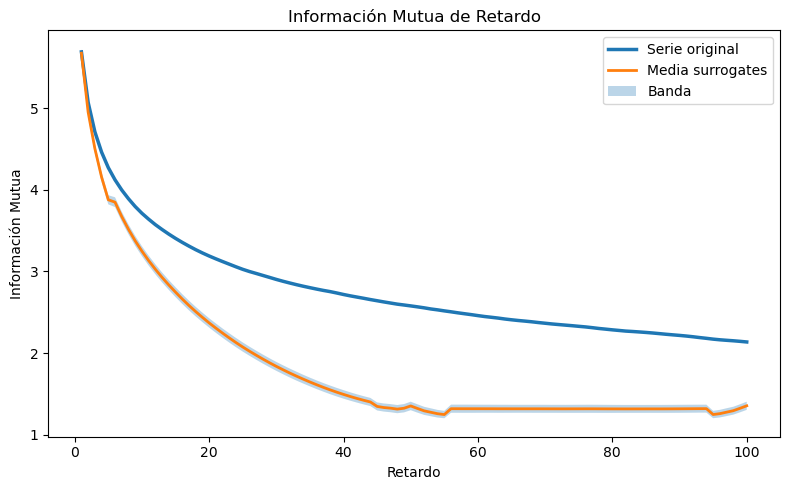

In [17]:
res_block = validacion_surrogado(block_surrogate, serie_original, n_surrogates=100, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : -60.876329
Media de las medias surrogate: -60.876329

Varianza original              : 179.390052
Media de las varianzas surrogate: 179.390052

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 0/100
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00003
p-valor medio                : 1.00000


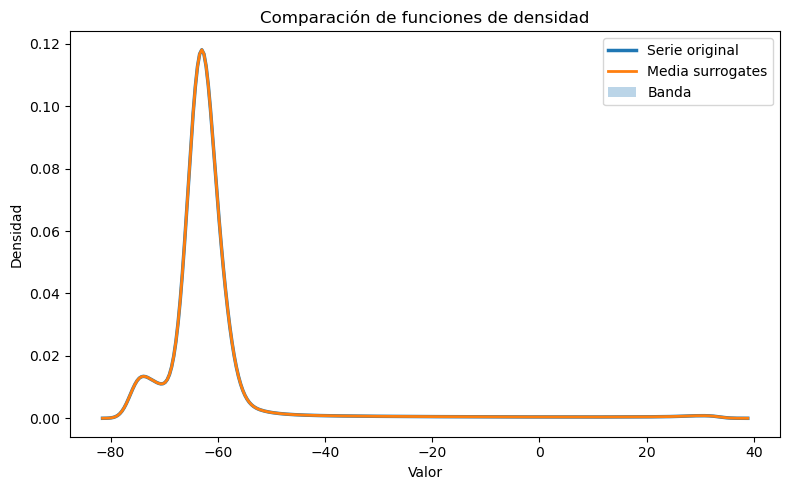


========== PSD ==========
Error relativo medio PSD: 10727549061.207 %

========== Autocorrelación ==========
Error absoluto medio: 0.217005


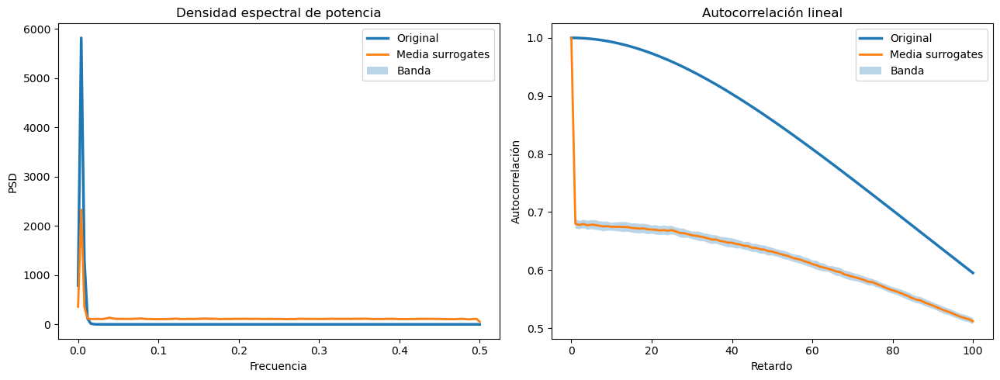

In [ ]:
res_local = validacion_surrogado(local_surrogate, serie_original, n_surrogates=100, perm_range=50)

Random Shuffling (`random`)


========== Información Mutua de Retardo ==========
Error absoluto medio : 2.788108
Retardos dentro de la banda : 0.00%


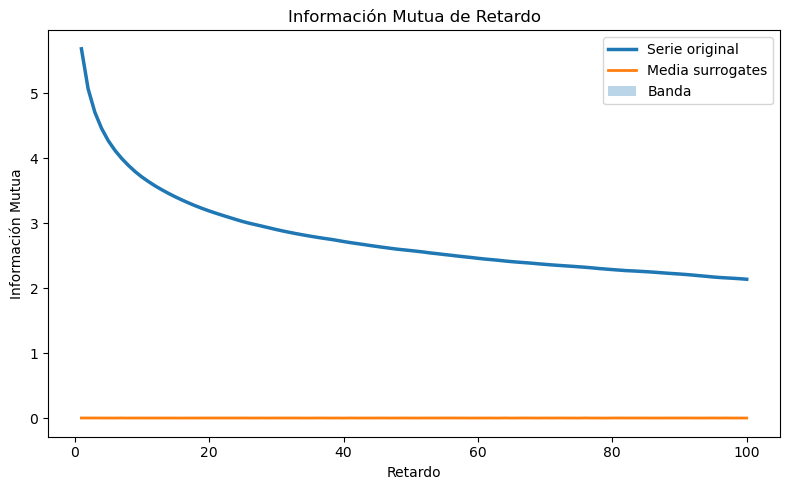

In [19]:
res_random = validacion_surrogado(random_surrogate, serie_original, n_surrogates=100)